In [1]:
import sys; 
print(sys.version)

3.10.18 | packaged by conda-forge | (main, Jun  4 2025, 14:46:25) [Clang 18.1.8 ]


In [2]:
import sys
sys.path.append(".")

In [12]:
# import necessary libraries
import cobra as cb
import numpy as np
import scanpy as sc
import pandas as pd
import matplotlib.pyplot as plt

In [4]:
# import local functions from scFBApy for flux generation
from utils_scFBApy import scFBApy, repairNeg, popModel 

In [5]:
# loading the flux model for flux generation
flux_model = cb.io.read_sbml_model("models/model.xml")
print("Flux Model loaded with", len(flux_model.reactions), "reactions")

Flux Model loaded with 449 reactions


# Import HECA dataset

In [6]:
adata = sc.read_h5ad("datasets/HECA-Subset.h5ad")
print("HECA AnnData loaded with shape:", adata.shape)

HECA AnnData loaded with shape: (90001, 17736)


In [7]:
adata

AnnData object with n_obs × n_vars = 90001 × 17736
    obs: 'n_genes', 'sample', 'percent_mito', 'n_counts', 'Endometriosis_stage', 'Endometriosis', 'Hormonal treatment', 'Binary Stage', 'Stage', 'phase', 'dataset', 'Age', 'lineage', 'celltype', 'label_long'
    var: 'gene_ids', 'feature_types'
    uns: 'Binary Stage_colors', 'Biopsy_type_colors', 'Endometrial_pathology_colors', 'Endometriosis_stage_colors', 'GarciaAlonso_celltype_colors', 'Group_colors', 'Hormonal treatment_colors', 'Library_genotype_colors', 'Mareckova_celltype_colors', 'Mareckova_epi_celltype_colors', 'Mareckova_lineage_colors', 'Processing_colors', 'Symbol_colors', 'Tan_cellsubtypes_colors', 'Tan_celltype_colors', 'Treatment_colors', 'celltype_colors', 'dataset_colors', 'genotype_colors', 'hvg', 'label_long_colors', 'leiden', 'leiden_R_colors', 'leiden_colors', 'lineage_colors', 'neighbors', 'phase_colors', 'umap'
    obsm: 'X_scVI', 'X_umap'
    obsp: 'connectivities', 'distances'

In [8]:
adata.obs['sample'].unique()

['GSM6605437', 'GSM6605440', 'GSM4577309', 'HCA_A_RepT_RNA13247830', 'GSM4577313', ..., 'UA_Endo9426402_FX1156', 'UA_Endo12680033_FX1254', 'UA_Endo10298210_FX1176', 'UA_Endo12961679_FX1285', 'UA_Endo12961681_FX1289']
Length: 87
Categories (87, object): ['4861STDY7387181', '4861STDY7387182', '4861STDY7771115', '4861STDY7771123', ..., 'UA_Endo12961681_SE03', 'UA_Endo12961682_FX1289', 'UA_Endo12961682_SE03', 'UA_Endo13646709']

In [9]:
# Unique cell types
cell_types = adata.obs['celltype'].unique()
print("Number of unique cell types:", len(cell_types))
print("\nList of cell types:")
print(cell_types)

Number of unique cell types: 36

List of cell types:
['Arterial', 'Ciliated', 'Cycling', 'Fibroblast_basalis', 'Glandular', ..., 'preGlandular', 'preLuminal', 'sHormones', 'uSMCs', 'dHormones']
Length: 36
Categories (36, object): ['SOX9_basalis', 'SOX9_functionalis_I', 'SOX9_functionalis_II', 'SOX9_luminal', ..., 'Immune_Myeloid', 'Venous', 'Arterial', 'Lymphatic']


In [10]:
# Count of cells per cell type
cell_type_counts = adata.obs['celltype'].value_counts()
print("Cell counts per cell type:")
print(cell_type_counts)

Cell counts per cell type:
celltype
eStromal                    15964
dStromal_mid                12571
Immune_Lymphoid              9891
dStromal_early               4824
Venous                       4447
eHormones                    4129
Glandular                    3746
SOX9_functionalis_II         3612
dStromal_late                3505
preGlandular                 3399
Immune_Myeloid               3232
Luminal                      2942
Glandular_secretory          2472
eStromal_cycling             2222
ePV_2                        2013
Ciliated                     1503
sHormones                    1186
Cycling                      1185
eStromal_MMPs                1146
ePV_1b                        790
preLuminal                    785
SOX9_luminal                  775
Arterial                      487
SOX9_functionalis_I           456
MUC5B                         399
uSMCs                         397
ePV_1a                        397
mPV                           389
HOXA13      

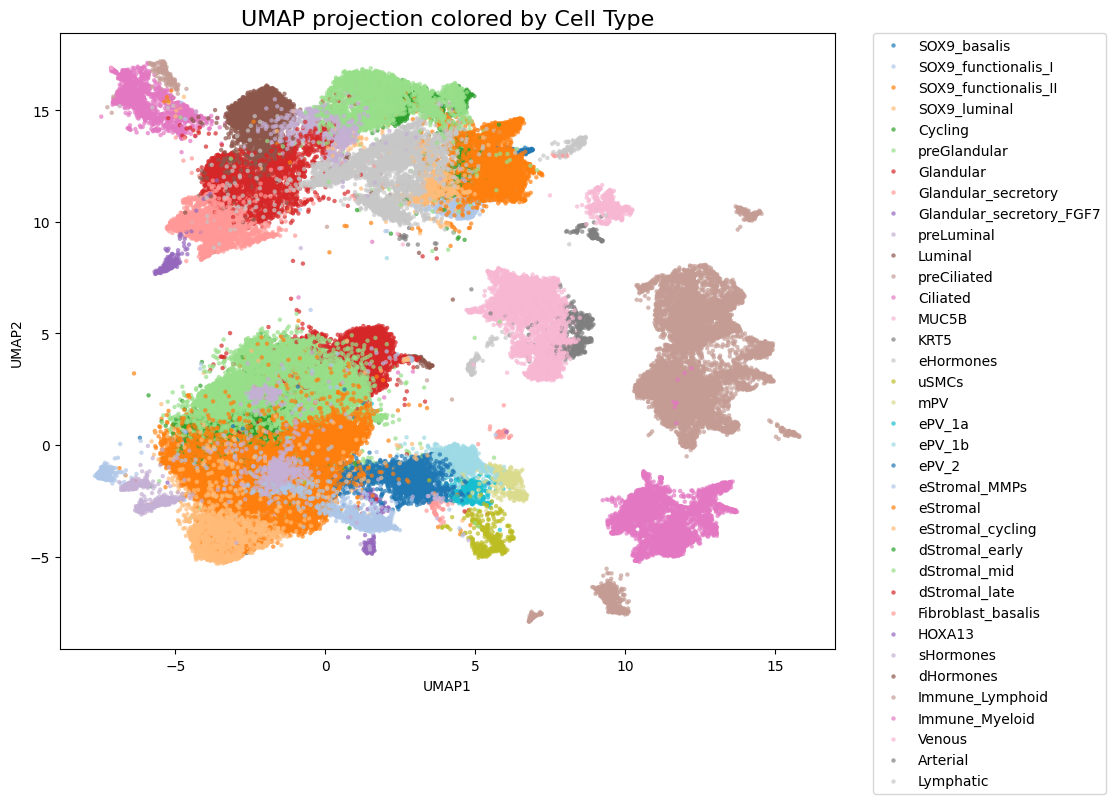

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns

umap_df = pd.DataFrame(adata.obsm['X_umap'], columns=["UMAP1", "UMAP2"])
umap_df['celltype'] = adata.obs['celltype'].values

plt.figure(figsize=(10,8))
sns.scatterplot(
    data=umap_df, x="UMAP1", y="UMAP2",
    hue="celltype", palette="tab20", s=10, alpha=0.7, linewidth=0
)
plt.title("UMAP projection colored by Cell Type", fontsize=16)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', borderaxespad=0.)
plt.show()


# Working with three cell types

/var/folders/3m/0mzmnr390d7_tzpq513jtf8h0000gn/T/ipykernel_1592/153525858.py:20: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  cell_counts = subset.groupby(["celltype_simple", "Endometriosis"]).size().unstack(fill_value=0)


Endometriosis    Control  Endometriosis
celltype_simple                        
Glandular           4700           1749
Immune_Myeloid       915           2317
eStromal           10796           8536


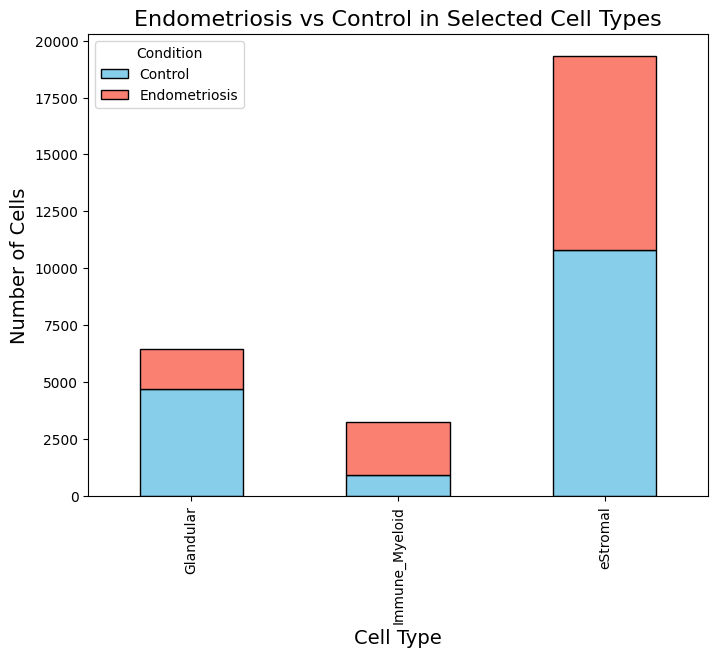

In [13]:

obs_df = adata.obs.copy()

# Collapse subtypes into main groups
def simplify_celltype(ct):
    if ct.startswith("eStromal"):
        return "eStromal"
    elif ct.startswith("Glandular"):
        return "Glandular"
    elif ct.startswith("Immune_Myeloid"):
        return "Immune_Myeloid"
    else:
        return None  

obs_df["celltype_simple"] = obs_df["celltype"].apply(simplify_celltype)

# Keep only selected groups
subset = obs_df[obs_df["celltype_simple"].notnull()]

# Count Endometriosis vs Control
cell_counts = subset.groupby(["celltype_simple", "Endometriosis"]).size().unstack(fill_value=0)

print(cell_counts)

# Plot
cell_counts.plot(kind="bar", stacked=True, figsize=(8,6), color=["skyblue", "salmon"], edgecolor="black")
plt.title("Endometriosis vs Control in Selected Cell Types", fontsize=16)
plt.ylabel("Number of Cells", fontsize=14)
plt.xlabel("Cell Type", fontsize=14)
plt.legend(title="Condition")
plt.show()


# Subset Creation

In [14]:
# Define the target cell types
target_cell_types = ["eStromal", "Glandular", "Immune_Myeloid"]

# Create a subset AnnData with only the selected cell types
subset_adata = adata[adata.obs["celltype"].isin(target_cell_types)].copy()

print("Subset details:")
print("Shape:", subset_adata.shape)  # (n_obs, n_vars)
print("Cell type distribution:")
print(subset_adata.obs["celltype"].value_counts())

Subset details:
Shape: (22942, 17736)
Cell type distribution:
celltype
eStromal          15964
Glandular          3746
Immune_Myeloid     3232
Name: count, dtype: int64


In [15]:
# Count unique patients in the subset
n_patients = subset_adata.obs["sample"].nunique()
print("Number of patients in the subset:", n_patients)

Number of patients in the subset: 80


In [17]:
# Function to compute variance of each row (cell)
def compute_variance(row, label, endo_mean, control_mean):
    ref = endo_mean if label == "Endometriosis" else control_mean
    return np.mean((row - ref) ** 2)

selected_indices = []

for cell_type in target_cell_types:
    # Work with just three cell type
    ct_data = subset_adata[subset_adata.obs["celltype"] == cell_type]
    df_ct = pd.DataFrame(ct_data.X.toarray(), index=ct_data.obs_names, columns=ct_data.var_names)
    df_ct["Endometriosis"] = ct_data.obs["Endometriosis"].values

    # Compute group means
    endo_mean = df_ct[df_ct["Endometriosis"] == "Endometriosis"].drop("Endometriosis", axis=1).mean()
    control_mean = df_ct[df_ct["Endometriosis"] == "Control"].drop("Endometriosis", axis=1).mean()

    # Calculate variance for each cell
    df_ct["variance"] = df_ct.drop("Endometriosis", axis=1).apply(
        lambda row: compute_variance(row, df_ct.loc[row.name, "Endometriosis"], endo_mean, control_mean),
        axis=1
    )

     # For each class, select top 60 cells by variance
    for condition in ["Endometriosis", "Control"]:
        top_cells = (
            df_ct[df_ct["Endometriosis"] == condition]
            .sort_values("variance", ascending=False)
            .head(60)
            .index
        )
        selected_indices.extend(top_cells)

# Create new AnnData subset with 600 cells
final_subset_adata = subset_adata[selected_indices].copy()

print("Final subset created by variance selection details:")
print("Shape:", final_subset_adata.shape)  
print("\nCell distribution:\n")
print(final_subset_adata.obs.groupby(["celltype", "Endometriosis"]).size())

Final subset created by variance selection details:
Shape: (360, 17736)

Cell distribution:

celltype        Endometriosis
Glandular       Control          60
                Endometriosis    60
eStromal        Control          60
                Endometriosis    60
Immune_Myeloid  Control          60
                Endometriosis    60
dtype: int64


/var/folders/3m/0mzmnr390d7_tzpq513jtf8h0000gn/T/ipykernel_1592/1580281293.py:40: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  print(final_subset_adata.obs.groupby(["celltype", "Endometriosis"]).size())



Cell distribution:

Endometriosis   Control  Endometriosis
celltype                              
Glandular            60             60
eStromal             60             60
Immune_Myeloid       60             60


/var/folders/3m/0mzmnr390d7_tzpq513jtf8h0000gn/T/ipykernel_1592/2739530049.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  cell_distribution = final_subset_adata.obs.groupby(["celltype", "Endometriosis"]).size().unstack(fill_value=0)


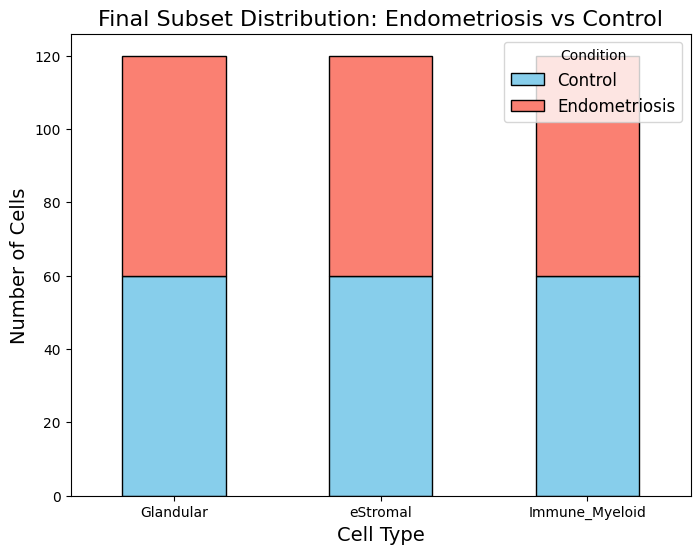

In [18]:

# Group by cell type and condition
cell_distribution = final_subset_adata.obs.groupby(["celltype", "Endometriosis"]).size().unstack(fill_value=0)

print("\nCell distribution:\n")
print(cell_distribution)

# Plot stacked bar chart
cell_distribution.plot(
    kind="bar",
    stacked=True,
    figsize=(8,6),
    color=["skyblue", "salmon"],
    edgecolor="black"
)

plt.title("Final Subset Distribution: Endometriosis vs Control", fontsize=16)
plt.ylabel("Number of Cells", fontsize=14)
plt.xlabel("Cell Type", fontsize=14)
plt.legend(title="Condition", fontsize=12)
plt.xticks(rotation=0)

plt.show()


# Flux Generation

In [19]:
final_subset_adata

The history saving thread hit an unexpected error (OperationalError('attempt to write a readonly database')).History will not be written to the database.


AnnData object with n_obs × n_vars = 360 × 17736
    obs: 'n_genes', 'sample', 'percent_mito', 'n_counts', 'Endometriosis_stage', 'Endometriosis', 'Hormonal treatment', 'Binary Stage', 'Stage', 'phase', 'dataset', 'Age', 'lineage', 'celltype', 'label_long'
    var: 'gene_ids', 'feature_types'
    uns: 'Binary Stage_colors', 'Biopsy_type_colors', 'Endometrial_pathology_colors', 'Endometriosis_stage_colors', 'GarciaAlonso_celltype_colors', 'Group_colors', 'Hormonal treatment_colors', 'Library_genotype_colors', 'Mareckova_celltype_colors', 'Mareckova_epi_celltype_colors', 'Mareckova_lineage_colors', 'Processing_colors', 'Symbol_colors', 'Tan_cellsubtypes_colors', 'Tan_celltype_colors', 'Treatment_colors', 'celltype_colors', 'dataset_colors', 'genotype_colors', 'hvg', 'label_long_colors', 'leiden', 'leiden_R_colors', 'leiden_colors', 'lineage_colors', 'neighbors', 'phase_colors', 'umap'
    obsm: 'X_scVI', 'X_umap'
    obsp: 'connectivities', 'distances'

In [20]:
print(final_subset_adata.var_names)

Index(['A1BG', 'A2M', 'A4GALT', 'AAAS', 'AACS', 'AADAC', 'AADACL2', 'AADACL4',
       'AADAT', 'AAGAB',
       ...
       'ZSWIM9', 'ZW10', 'ZWILCH', 'ZXDA', 'ZXDB', 'ZXDC', 'ZYG11A', 'ZYG11B',
       'ZYX', 'ZZEF1'],
      dtype='object', length=17736)


In [19]:
#Do not run this if you don't want to execute the flux generation or already have the flux file

# final_subset_adata.var_names = final_subset_adata.var["gene_ids"].astype(str)

# # Generate fluxes
# adata_fluxes = scFBApy(
#     model_orig=flux_model,
#     adata=final_subset_adata,
#     objective="Biomass",
#     cooperation=True,
#     eps=0.001,
#     compute_fva=True,
#     npop_fva=5,
#     type_ras_normalization="max",
#     and_expression=np.nanmin,
#     or_expression=np.nansum,
#     fraction_of_optimum=0,
#     processes=1,
#     round_c=10
# )

# print("Flux analysis done")
# print("Mean biomass per cell:", adata_fluxes.to_df()["Biomass"].mean())

# # Extract flux results as a dataframe
# flux_df = adata_fluxes.to_df()

# # Save to CSV
# flux_df.to_csv("top_60_flux_results.csv")

# print("lux results saved as top_60_flux_results.csv")

In [22]:
flux_df = pd.read_csv('top_60_flux_results.csv')

In [23]:
flux_df

,Unnamed: 0,ADSL2r,CYSO,LEUTA,EX_lys__L_e_#,ACOAD8m,r0761,SPMDtex2,t_Lcystin_glu__L,tyr_L_t,...,PRAGSr,HMR_1504,EX_gthrd_e_#,MTHFD2i,r0074,GRTT,ACOAD9m,SMO,GLUDC,DMATT
0,UA_Endo10298210_AACACACTCACTTCTA-Mareckova,0.000151,0.001000,0.000000,-0.813034,0.000000,0.000143,0.0,0.001000,-0.000213,...,0.000151,0.000027,0.0,-0.019516,0.001000,0.000055,0.000000,0.000027,-0.000000,0.000055
1,UA_Endo12680031_TTCATGTTCTTCGACC-Mareckova,0.000922,2.922510,0.000000,-0.813034,0.001000,-0.000000,0.0,0.001000,-0.001804,...,0.000922,0.000167,0.0,-4.284792,-0.001000,0.000333,0.001000,0.000167,-0.001000,0.000333
2,UA_Endo10298210_GTACAACTCCGTCCTA-Mareckova,0.000922,0.013331,0.000000,-0.813034,0.000000,0.000107,0.0,0.001000,-0.001304,...,0.000922,0.000167,0.0,-0.000005,0.001000,0.000333,0.001000,0.000167,0.001000,0.000333
3,UA_Endo10298210_TAGGTTGGTCATCAGT-Mareckova,0.000922,0.001000,0.000000,-0.813034,0.000000,0.000135,0.0,0.001000,-0.001304,...,0.000922,0.000167,0.0,0.001368,-0.001000,0.000333,0.001000,0.000167,0.001000,0.000333
4,UA_Endo10298210_TACATTCAGTATTCCG-Mareckova,0.000083,0.000461,0.000000,-0.813034,0.000000,-0.000143,0.0,0.001000,-0.000182,...,0.000083,0.000015,0.0,0.000849,-0.000877,0.000030,0.000000,0.000015,0.000466,0.000030
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
355,GSM6605438_CGCCAGAAGTCTGGTT-Huang,0.000088,0.000957,0.000000,-0.813034,0.000000,-0.000143,0.0,0.001000,-0.000124,...,0.000088,0.000016,0.0,0.001510,0.000321,0.000032,0.000039,0.000016,-0.001000,0.000032
356,GSM5572240_AGAACCTGTGGTTTAC-Lai,0.000126,0.001000,0.000000,-0.813034,0.000000,-0.000055,0.0,0.001000,-0.000178,...,0.000126,0.000023,0.0,-0.014972,0.001000,0.000046,0.001000,0.000023,0.001000,0.000046
357,GSM6605439_TTCATTGTCGTGGAAG-Huang,0.000098,0.000000,0.000000,-0.813034,0.000000,-0.000143,0.0,0.001643,-0.000227,...,0.000098,0.000018,0.0,0.000293,0.000230,0.000035,0.000000,0.000018,-0.001000,0.000035
358,UA_Endo9426399_GGTGAAGTCTAACACG-Mareckova,0.000107,0.000170,0.000000,-0.813034,0.000000,-0.000143,0.0,0.000000,-0.000253,...,0.000107,0.000019,0.0,-0.001114,0.001000,0.000039,0.000000,0.000019,0.000000,0.000039


# Collecting Highly variable genes

In [24]:

# Compute highly variable genes using Seurat v3 method 
sc.pp.highly_variable_genes(final_subset_adata, flavor='seurat_v3', n_top_genes=1000)

# Extract the top 1000 highly variable genes
top_1000_hvgs = final_subset_adata.var_names[final_subset_adata.var['highly_variable']].tolist()

print(f"Number of highly variable genes stored: {len(top_1000_hvgs)}")
print("Preview of top 10 genes:")
print(top_1000_hvgs[:10])


OMP: Info #276: omp_set_nested routine deprecated, please use omp_set_max_active_levels instead.


Number of highly variable genes stored: 1000
Preview of top 10 genes:
['A2M', 'ABAT', 'ABHD17C', 'ABI3', 'ABLIM1', 'AC007906.2', 'AC019117.2', 'AC024230.1', 'AC027288.3', 'AC078850.1']


# Patient investigation

In [25]:

df = final_subset_adata.obs

print("Total patients:", df["sample"].nunique())

patient_counts = df.groupby("sample").size().sort_values(ascending=False)

print(patient_counts)


Total patients: 47
sample
E02_EuE                   58
UA_Endo9426402_FX1156     45
GSM4577310                31
GSM5572239                22
GSM6605438                16
MRC_Endo8712032           15
C01_Ctrl                  14
GSM6605436                13
GSM6605434                13
UA_Endo10298210_FX1125    11
MRC_Endo8625698            9
C03_Ctrl                   9
E04_EuE                    7
GSM6605440                 7
C02_Ctrl                   6
4861STDY7387182            6
UA_Endo12680031_FX1259     6
GSM6605437                 6
UA_Endo12680033_FX1249     6
UA_Endo13646709            5
UA_Endo10298210_FX1176     5
GSM4577315                 5
GSM4577308                 3
GSM5572240                 3
UA_Endo12961679_SE02       3
4861STDY7387181            3
GSM6605432                 3
E07_EuE                    2
E01_EuE                    2
GSM4577311                 2
GSM4577306                 2
GSM5572238                 2
GSM6605431                 2
UA_Endo9426399_FX

/var/folders/3m/0mzmnr390d7_tzpq513jtf8h0000gn/T/ipykernel_1592/4228442305.py:5: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  patient_counts = df.groupby("sample").size().sort_values(ascending=False)


In [26]:
df = final_subset_adata.obs

patient_labels = df.groupby("sample")["Endometriosis"].first()

print("Total patients:", patient_labels.shape[0])

print("\nPatients per class:")
print(patient_labels.value_counts())

Total patients: 47

Patients per class:
Endometriosis
Control          28
Endometriosis    19
Name: count, dtype: int64


/var/folders/3m/0mzmnr390d7_tzpq513jtf8h0000gn/T/ipykernel_1592/3823154914.py:3: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  patient_labels = df.groupby("sample")["Endometriosis"].first()


# Classification on only transcriptomics data

In [30]:
import os, random
import scipy.sparse as sp
import joblib
from scipy import sparse
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import StratifiedKFold

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from xgboost import XGBClassifier
from sklearn.preprocessing import StandardScaler

from sklearn.model_selection import StratifiedGroupKFold

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix
)



In [45]:
os.makedirs("Results/Transcriptomics", exist_ok=True)
os.makedirs("Results/Transcriptomics/patient_mean", exist_ok=True)
os.makedirs("Results/Transcriptomics/patient_examples", exist_ok=True)  
os.makedirs("Results/Transcriptomics/patient_mean/confusion_matrix", exist_ok=True)
os.makedirs("Results/Transcriptomics/patient_examples/confusion_matrix", exist_ok=True)  

In [28]:
SEED = 42
os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)

In [32]:
# Helper functions for training
def to_dataframe(adata):
    cols = adata.var_names
    idx = adata.obs_names
    if sparse.issparse(adata.X):
        return pd.DataFrame.sparse.from_spmatrix(adata.X, index=idx, columns=cols)
    else:
        return pd.DataFrame(adata.X, index=idx, columns=cols)

def _sort_key_row(r):
    return ( r["acc_mean"], r["f1_mean"], r["prec_mean"], r["rec_mean"])

def _explainer_type(model_name: str) -> str:
    if model_name in {"Random Forest", "Gradient Boosting", "XGBoost"}:
        return "tree"
    if model_name == "Logistic Regression":
        return "linear"
    return "kernel"  # LinearSVC

def _ensure_df(X):
    return X if isinstance(X, pd.DataFrame) else pd.DataFrame(X)

def _align_X_to_features(X, feature_names):
    X = _ensure_df(X)
    return X.loc[:, list(feature_names)]

In [33]:
cell_types = ["eStromal", "Glandular", "Immune_Myeloid"]
adata = final_subset_adata[final_subset_adata.obs["celltype"].isin(cell_types)].copy()

# stable order so folds never change across runs
adata = adata[adata.obs_names.sort_values()].copy()

# Convert to DataFrame so we can subset HVGs using columns 
X_all = to_dataframe(adata)

# Labels
y_all = adata.obs["Endometriosis"].astype(str).values
y_all = pd.Series(y_all, name="Endometriosis")

le = LabelEncoder()
y_all_enc = le.fit_transform(y_all)

In [34]:
# Collecting HVG's
common_hvgs = [g for g in top_1000_hvgs if g in X_all.columns]

X_all = X_all.loc[:, common_hvgs]

print("Dataset shape (cells x HVGs):", X_all.shape)
print("Classes:", list(le.classes_))
print("Cell types used:", cell_types)

Dataset shape (cells x HVGs): (360, 1000)
Classes: ['Control', 'Endometriosis']
Cell types used: ['eStromal', 'Glandular', 'Immune_Myeloid']


In [35]:
# Check patient count in every fold
SEED = 42

# Create stratification key to keep both cell type AND disease label balanced across folds
strat_key = (
    adata.obs["celltype"].astype(str) + "||" +
    adata.obs["Endometriosis"].astype(str)
).values

groups = adata.obs["sample"].astype(str).values

cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)

X_np = X_all.to_numpy()

print("Cells:", X_np.shape[0], "Features:", X_np.shape[1])
print("Unique patients (sample):", pd.Series(groups).nunique())
print("Unique strata (celltype||label):", pd.Series(strat_key).nunique())

all_ok = True
for fold, (tr_idx, te_idx) in enumerate(cv.split(X_np, strat_key, groups=groups), start=1):
    tr_pat = set(groups[tr_idx])
    te_pat = set(groups[te_idx])
    overlap = tr_pat.intersection(te_pat)

    print(f"\nFold {fold}")
    print("  train cells:", len(tr_idx), "| test cells:", len(te_idx))
    print("  train patients:", len(tr_pat), "| test patients:", len(te_pat))
    print("  patient overlap:", len(overlap))

    if len(overlap) > 0:
        all_ok = False
        print("  ERROR: same patient appears in both train and test")
        print("  example overlap:", list(overlap)[:10])

    ytr = adata.obs["Endometriosis"].iloc[tr_idx].astype(str).value_counts()
    yte = adata.obs["Endometriosis"].iloc[te_idx].astype(str).value_counts()
    print("  train label counts:\n", ytr.to_string())
    print("  test  label counts:\n", yte.to_string())

    sk_tr = pd.Series(strat_key[tr_idx]).value_counts().head(5)
    sk_te = pd.Series(strat_key[te_idx]).value_counts().head(5)
    print("  train top strata:\n", sk_tr.to_string())
    print("  test  top strata:\n", sk_te.to_string())

if all_ok:
    print("\n Split check passed: no patient overlaps between train and test in any fold.")
else:
    raise RuntimeError(" Split check failed: patient overlap found. Fix before training.")

Cells: 360 Features: 1000
Unique patients (sample): 47
Unique strata (celltype||label): 6

Fold 1
  train cells: 324 | test cells: 36
  train patients: 39 | test patients: 8
  patient overlap: 0
  train label counts:
 Endometriosis
Control          166
Endometriosis    158
  test  label counts:
 Endometriosis
Endometriosis    22
Control          14
  train top strata:
 eStromal||Endometriosis          59
Glandular||Control               56
Immune_Myeloid||Control          55
eStromal||Control                55
Immune_Myeloid||Endometriosis    52
  test  top strata:
 Glandular||Endometriosis         13
Immune_Myeloid||Endometriosis     8
Immune_Myeloid||Control           5
eStromal||Control                 5
Glandular||Control                4

Fold 2
  train cells: 255 | test cells: 105
  train patients: 35 | test patients: 12
  patient overlap: 0
  train label counts:
 Endometriosis
Endometriosis    128
Control          127
  test  label counts:
 Endometriosis
Control          53
Endo

In [38]:
# model declaration
def get_models():
    return {
        "Logistic Regression": LogisticRegression(
            max_iter=5000,
            solver="liblinear",
            random_state=SEED
        ),
        "Random Forest": RandomForestClassifier(n_estimators=500, random_state=SEED, n_jobs=1),
        "Gradient Boosting": GradientBoostingClassifier(random_state=SEED),
        "SVM (RBF Kernel)": SVC(kernel="rbf", probability=True, random_state=SEED),
        "XGBoost": XGBClassifier(
            eval_metric="logloss",
            random_state=SEED,
            nthread=1,
            tree_method="hist",
            max_depth=3,
            learning_rate=0.05,
            n_estimators=900,
            subsample=0.9,
            colsample_bytree=0.9,
            reg_lambda=2.0,
        ),
    }

In [39]:
# Convert cell-level dataset → patient-level dataset.
df = X_all.copy()

df["sample"] = adata.obs["sample"].values
df["label"] = adata.obs["Endometriosis"].values

gene_cols = X_all.columns

patient_df = df.groupby("sample")[gene_cols].mean()

patient_labels = df.groupby("sample")["label"].first()

X_pat = patient_df.values
y_pat = LabelEncoder().fit_transform(patient_labels.values)
patients = patient_df.index.values

print("Patient feature matrix:", X_pat.shape)
print("Number of patients:", len(patients))


/var/folders/3m/0mzmnr390d7_tzpq513jtf8h0000gn/T/ipykernel_1592/1154529023.py:9: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  patient_df = df.groupby("sample")[gene_cols].mean()


Patient feature matrix: (47, 1000)
Number of patients: 47


/var/folders/3m/0mzmnr390d7_tzpq513jtf8h0000gn/T/ipykernel_1592/1154529023.py:11: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  patient_labels = df.groupby("sample")["label"].first()


## Training Transcriptomics - Patient Combined (Mean value)

In [40]:
cv_summary_rows = []
cv_fold_details = {}

X_np = X_pat
y_np = y_pat
group_ids = patients

print("Shape of X_pat:", X_np.shape)
print("Shape of y_pat:", y_np.shape)
print("Number of unique patients:", len(set(group_ids)))
models = get_models()
for name, model in models.items():
    fold_metrics = []
    fold_conf_mats = []
    fold_predictions = []

    print("\n" + "=" * 70)
    print("MODEL:", name)
    print("=" * 70)

    for fold, (tr_idx, te_idx) in enumerate(cv.split(X_np, y_np, groups=group_ids), start=1):
        Xtr, Xte = X_np[tr_idx], X_np[te_idx]
        ytr, yte = y_np[tr_idx], y_np[te_idx]

        train_patients = pd.Series(group_ids[tr_idx]).tolist()
        test_patients = pd.Series(group_ids[te_idx]).tolist()

        overlap = set(train_patients).intersection(set(test_patients))

        print(f"\nFold {fold}")
        print("Train patients:", len(train_patients))
        print("Test patients :", len(test_patients))
        print("Patient overlap:", overlap)

        model.fit(Xtr, ytr)
        pred = model.predict(Xte)

        m = {
            "model": name,
            "fold": fold,
            "accuracy": float(accuracy_score(yte, pred)),
            "precision": float(precision_score(yte, pred, zero_division=0)),
            "recall": float(recall_score(yte, pred, zero_division=0)),
            "f1_score": float(f1_score(yte, pred, zero_division=0)),
        }

        fold_metrics.append(m)
        fold_conf_mats.append(confusion_matrix(yte, pred))

        fold_predictions.append(
            pd.DataFrame({
                "fold": fold,
                "patient_id": test_patients,
                "y_true": yte,
                "y_pred": pred
            })
        )

    df_folds = pd.DataFrame(fold_metrics)

    cv_fold_details[name] = {
        "cv_fold_metrics": df_folds,
        "cv_confusion_matrices": fold_conf_mats,
        "oof_predictions": pd.concat(fold_predictions, ignore_index=True)
    }

    cv_summary_rows.append({
        "model": name,
        "acc_mean": df_folds["accuracy"].mean(),
        "acc_std": df_folds["accuracy"].std(ddof=0),
        "prec_mean": df_folds["precision"].mean(),
        "prec_std": df_folds["precision"].std(ddof=0),
        "rec_mean": df_folds["recall"].mean(),
        "rec_std": df_folds["recall"].std(ddof=0),
        "f1_mean": df_folds["f1_score"].mean(),
        "f1_std": df_folds["f1_score"].std(ddof=0),
    })

results_df = pd.DataFrame(cv_summary_rows)

results_df = results_df.sort_values(
    ["acc_mean", "f1_mean",  "prec_mean", "rec_mean"],
    ascending=False
).reset_index(drop=True)

print("\n================ 5-FOLD CV RESULTS ================\n")
print(results_df.to_string(index=False))

print("\n================ FOLD-WISE RESULTS FOR ALL MODELS ================\n")
for name in models.keys():
    print(f"\n----- {name} (Fold Results) -----\n")
    print(cv_fold_details[name]["cv_fold_metrics"].to_string(index=False))

best_model_name = results_df.iloc[0]["model"]

print("\n================ BEST MODEL ================\n")
print("Best model by mean accuracy across 5 folds:", best_model_name)
print("Mean accuracy:", results_df.iloc[0]["acc_mean"])

print("\nFold-by-fold metrics for best model:\n")
print(cv_fold_details[best_model_name]["cv_fold_metrics"].to_string(index=False))

best_model = models[best_model_name]
best_model.fit(X_np, y_np)



Shape of X_pat: (47, 1000)
Shape of y_pat: (47,)
Number of unique patients: 47

MODEL: Logistic Regression

Fold 1
Train patients: 37
Test patients : 10
Patient overlap: set()

Fold 2
Train patients: 38
Test patients : 9
Patient overlap: set()

Fold 3
Train patients: 38
Test patients : 9
Patient overlap: set()

Fold 4
Train patients: 37
Test patients : 10
Patient overlap: set()

Fold 5
Train patients: 38
Test patients : 9
Patient overlap: set()

MODEL: Random Forest

Fold 1
Train patients: 37
Test patients : 10
Patient overlap: set()

Fold 2
Train patients: 38
Test patients : 9
Patient overlap: set()

Fold 3
Train patients: 38
Test patients : 9
Patient overlap: set()

Fold 4
Train patients: 37
Test patients : 10
Patient overlap: set()

Fold 5
Train patients: 38
Test patients : 9
Patient overlap: set()

MODEL: Gradient Boosting

Fold 1
Train patients: 37
Test patients : 10
Patient overlap: set()

Fold 2
Train patients: 38
Test patients : 9
Patient overlap: set()

Fold 3
Train patients: 

,C,1.0
,kernel,'rbf'
,degree,3
,gamma,'scale'
,coef0,0.0
,shrinking,True
,probability,True
,tol,0.001
,cache_size,200
,class_weight,None
,verbose,False


In [41]:
# Saving results for further analysis
if "performance_results" not in globals():
    performance_results = {}

if "Only Transcriptomics" not in performance_results:
    performance_results["Transcriptomics"] = {}

performance_results["Transcriptomics"]["Patient Mean"] = {
    "summary_table": results_df,
    "all_models": cv_fold_details,
    "best": {
        "best_model_name": best_model_name,
        "best_model": best_model,
        "cv_mean_std": results_df[results_df["model"] == best_model_name].iloc[0].to_dict(),
        "cv_fold_metrics": cv_fold_details[best_model_name]["cv_fold_metrics"],
        "cv_confusion_matrices": cv_fold_details[best_model_name]["cv_confusion_matrices"],
        "oof_predictions": cv_fold_details[best_model_name]["oof_predictions"],
    },
    "shap_ready": {
        "best_model": best_model,
        "best_model_name": best_model_name,
        "best_model_metrics": {
            "cv_f1_mean": float(results_df.iloc[0]["f1_mean"]),
            "cv_f1_std": float(results_df.iloc[0]["f1_std"]),
            "cv_accuracy_mean": float(results_df.iloc[0]["acc_mean"]),
            "cv_accuracy_std": float(results_df.iloc[0]["acc_std"]),
            "cv_precision_mean": float(results_df.iloc[0]["prec_mean"]),
            "cv_precision_std": float(results_df.iloc[0]["prec_std"]),
            "cv_recall_mean": float(results_df.iloc[0]["rec_mean"]),
            "cv_recall_std": float(results_df.iloc[0]["rec_std"]),
        },
        "feature_names": list(X_all.columns),
        "X_eval": X_np,
        "y_eval": y_np,
        "patient_ids": group_ids,
    }
}

print("\nStored keys:")
print(performance_results["Transcriptomics"]["Patient Mean"].keys())
print(performance_results["Transcriptomics"]["Patient Mean"]["shap_ready"].keys())


Stored keys:
dict_keys(['summary_table', 'all_models', 'best', 'shap_ready'])
dict_keys(['best_model', 'best_model_name', 'best_model_metrics', 'feature_names', 'X_eval', 'y_eval', 'patient_ids'])


/var/folders/3m/0mzmnr390d7_tzpq513jtf8h0000gn/T/ipykernel_1592/4071769535.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


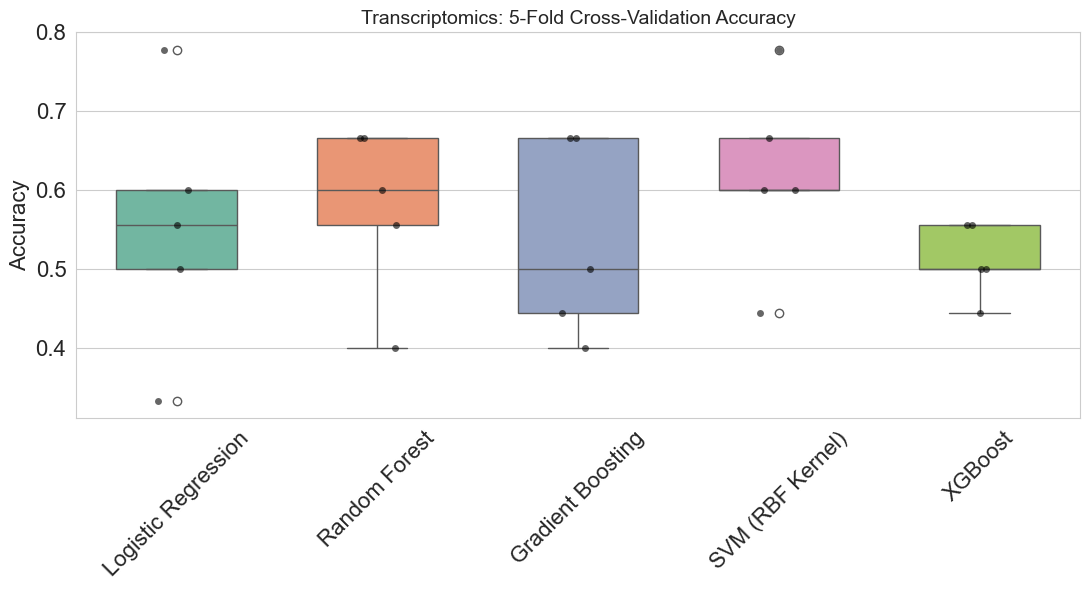

In [46]:
all_folds_df = pd.concat(
    [cv_fold_details[m]["cv_fold_metrics"] for m in models.keys()],
    ignore_index=True
)

plt.figure(figsize=(11, 6))
sns.set_style("whitegrid")

sns.boxplot(
    data=all_folds_df,
    x="model",
    y="accuracy",
    palette="Set2",
    width=0.6
)

sns.stripplot(
    data=all_folds_df,
    x="model",
    y="accuracy",
    color="black",
    size=5,
    jitter=True,
    alpha=0.6
)

plt.xticks(rotation=45, fontsize=16)
plt.yticks(fontsize=16)
plt.xlabel("")
plt.ylabel("Accuracy", fontsize=16)
plt.title("Transcriptomics: 5-Fold Cross-Validation Accuracy", fontsize=14)

plt.tight_layout()
plt.savefig("Results/Transcriptomics/patient_mean/5_fold_accuracy.pdf", bbox_inches="tight")
plt.show()

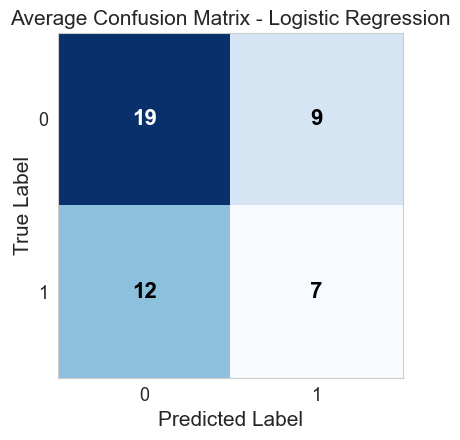

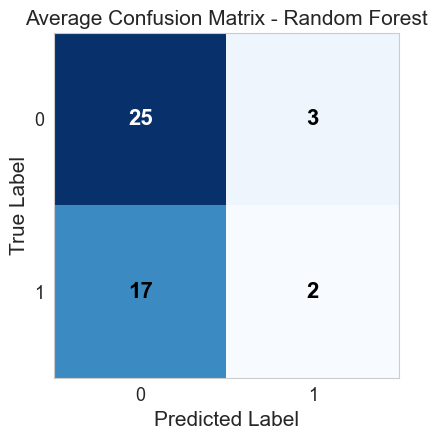

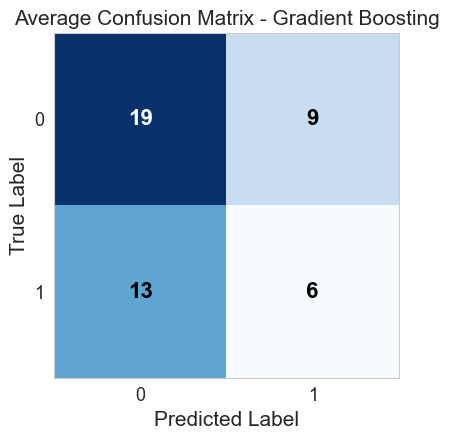

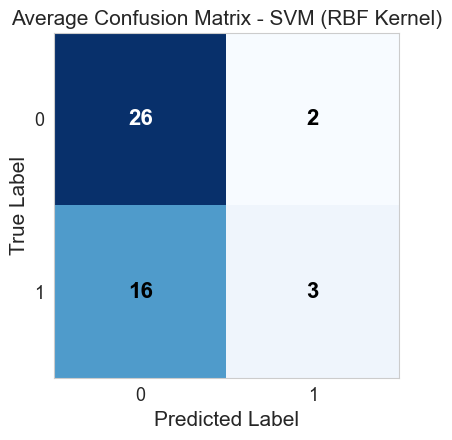

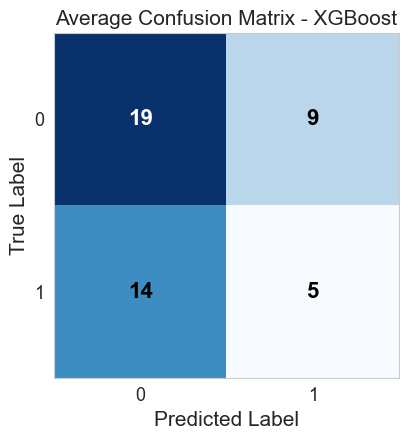

Average confusion matrices saved for all models.


In [48]:
os.makedirs("Experiment_1/Patient Mean", exist_ok=True)

for model_name, details in cv_fold_details.items():
    cms = details["cv_confusion_matrices"]
    avg_cm = np.sum(cms, axis=0)

    plt.figure(figsize=(4.5, 4.5))
    plt.imshow(avg_cm, cmap="Blues")

    plt.title(f"Average Confusion Matrix - {model_name}", fontsize=15)
    plt.xlabel("Predicted Label", fontsize=15)
    plt.ylabel("True Label", fontsize=15)

    plt.xticks([0, 1], fontsize=13)
    plt.yticks([0, 1], fontsize=13)

    for i in range(avg_cm.shape[0]):
        for j in range(avg_cm.shape[1]):
            value = round(avg_cm[i, j], 1)
            plt.text(
                j, i, value,
                ha="center",
                va="center",
                fontsize=16,
                fontweight="bold",
                color="white" if avg_cm[i, j] > avg_cm.max() / 1.2 else "black"
            )

    plt.tight_layout()
    plt.grid(False)

    safe_name = model_name.replace(" ", "_").replace("(", "").replace(")", "")
    plt.savefig(f"Results/Transcriptomics/patient_mean/confusion_matrix/Confusion_{safe_name}.pdf", bbox_inches="tight")
    plt.show()
    plt.close()

print("Average confusion matrices saved for all models.")

## Patient Examples

In [50]:
cv_summary_rows = []
cv_fold_details = {}

X_np = X_all.to_numpy()
y_np = y_all_enc
strat_key = (adata.obs["celltype"].astype(str) + "||" + adata.obs["Endometriosis"].astype(str)).values
group_ids = adata.obs["sample"].astype(str).values

print("Shape of X_all:", X_np.shape)
print("Shape of y_all_enc:", y_np.shape)
print("Number of unique samples:", len(set(group_ids)))

models = get_models()
for name, model in models.items():
    fold_metrics = []
    fold_conf_mats = []
    fold_class_counts = []
    fold_predictions = []

    print("\n" + "=" * 70)
    print("MODEL:", name)
    print("=" * 70)

    for fold, (tr_idx, te_idx) in enumerate(cv.split(X_np, strat_key, groups=group_ids), start=1):
        Xtr, Xte = X_np[tr_idx], X_np[te_idx]
        ytr, yte = y_np[tr_idx], y_np[te_idx]

        train_patients = pd.Series(group_ids[tr_idx]).unique()
        test_patients = pd.Series(group_ids[te_idx]).unique()
        overlap = set(train_patients).intersection(set(test_patients))

        print(f"\nFold {fold}")
        print("Train data:", len(tr_idx))
        print("Test data :", len(te_idx))
        print("Train patients:", len(train_patients))
        print("Test patients :", len(test_patients))
        print("Patient overlap:", len(overlap))

        train_view = pd.DataFrame({
            "sample": group_ids[tr_idx],
            "celltype": adata.obs["celltype"].iloc[tr_idx].values,
            "Endometriosis": adata.obs["Endometriosis"].iloc[tr_idx].values,
            "label": ytr
        })

        test_view = pd.DataFrame({
            "sample": group_ids[te_idx],
            "celltype": adata.obs["celltype"].iloc[te_idx].values,
            "Endometriosis": adata.obs["Endometriosis"].iloc[te_idx].values,
            "label": yte
        })

        print("Train class counts:")
        print(train_view["label"].value_counts().sort_index())

        print("Test class counts:")
        print(test_view["label"].value_counts().sort_index())

        model.fit(Xtr, ytr)
        pred = model.predict(Xte)

        m = {
            "model": name,
            "fold": fold,
            "accuracy": float(accuracy_score(yte, pred)),
            "precision": float(precision_score(yte, pred, zero_division=0)),
            "recall": float(recall_score(yte, pred, zero_division=0)),
            "f1_score": float(f1_score(yte, pred, zero_division=0)),
        }

        fold_metrics.append(m)
        fold_conf_mats.append(confusion_matrix(yte, pred))

        fold_class_counts.append({
            "model": name,
            "fold": fold,
            "train_class_0": int((train_view["label"] == 0).sum()),
            "train_class_1": int((train_view["label"] == 1).sum()),
            "test_class_0": int((test_view["label"] == 0).sum()),
            "test_class_1": int((test_view["label"] == 1).sum()),
        })

        fold_predictions.append(
            pd.DataFrame({
                "model": name,
                "fold": fold,
                "sample": group_ids[te_idx],
                "y_true": yte,
                "y_pred": pred
            })
        )

    df_folds = pd.DataFrame(fold_metrics)

    cv_fold_details[name] = {
        "fold_metrics": df_folds,
        "confusion_matrices": fold_conf_mats,
        "class_counts": pd.DataFrame(fold_class_counts),
        "predictions": pd.concat(fold_predictions, ignore_index=True)
    }

    cv_summary_rows.append({
        "model": name,
        "acc_mean": df_folds["accuracy"].mean(),
        "acc_std": df_folds["accuracy"].std(ddof=0),
        "prec_mean": df_folds["precision"].mean(),
        "prec_std": df_folds["precision"].std(ddof=0),
        "rec_mean": df_folds["recall"].mean(),
        "rec_std": df_folds["recall"].std(ddof=0),
        "f1_mean": df_folds["f1_score"].mean(),
        "f1_std": df_folds["f1_score"].std(ddof=0),
    })

results_df = pd.DataFrame(cv_summary_rows)

results_df = results_df.sort_values(
    ["acc_mean", "f1_mean", "prec_mean", "rec_mean"],
    ascending=False
).reset_index(drop=True)

print("\n================ 5-FOLD CV RESULTS ================\n")
print(results_df.to_string(index=False))

print("\n================ FOLD-WISE RESULTS FOR ALL MODELS ================\n")
for model_name in models.keys():
    print(f"\n----- {model_name} (Fold Results) -----\n")
    print(cv_fold_details[model_name]["fold_metrics"].to_string(index=False))

print("\n================ FOLD-WISE CLASS COUNTS FOR ALL MODELS ================\n")
for model_name in models.keys():
    print(f"\n----- {model_name} (Class Counts) -----\n")
    print(cv_fold_details[model_name]["class_counts"].to_string(index=False))

best_model_name = results_df.iloc[0]["model"]

print("\n================ BEST MODEL ================\n")
print("Best model by mean accuracy across 5 folds:", best_model_name)
print("Mean accuracy:", results_df.iloc[0]["acc_mean"])

print("\nFold-by-fold metrics for best model:\n")
print(cv_fold_details[best_model_name]["fold_metrics"].to_string(index=False))

print("\nFold-by-fold class counts for best model:\n")
print(cv_fold_details[best_model_name]["class_counts"].to_string(index=False))

best_model = models[best_model_name]
best_model.fit(X_np, y_np)



Shape of X_all: (360, 1000)
Shape of y_all_enc: (360,)
Number of unique samples: 47

MODEL: Logistic Regression

Fold 1
Train data: 324
Test data : 36
Train patients: 39
Test patients : 8
Patient overlap: 0
Train class counts:
label
0    166
1    158
Name: count, dtype: int64
Test class counts:
label
0    14
1    22
Name: count, dtype: int64

Fold 2
Train data: 255
Test data : 105
Train patients: 35
Test patients : 12
Patient overlap: 0
Train class counts:
label
0    127
1    128
Name: count, dtype: int64
Test class counts:
label
0    53
1    52
Name: count, dtype: int64

Fold 3
Train data: 296
Test data : 64
Train patients: 37
Test patients : 10
Patient overlap: 0
Train class counts:
label
0    158
1    138
Name: count, dtype: int64
Test class counts:
label
0    22
1    42
Name: count, dtype: int64

Fold 4
Train data: 327
Test data : 33
Train patients: 39
Test patients : 8
Patient overlap: 0
Train class counts:
label
0    151
1    176
Name: count, dtype: int64
Test class counts:
label

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,42
,solver,'liblinear'
,max_iter,5000
,multi_class,'deprecated'


In [51]:
if "performance_results" not in globals():
    performance_results = {}

if "Transcriptomics" not in performance_results:
    performance_results["Transcriptomics"] = {}

#storing the results for furhter analysis
performance_results["Transcriptomics"]["Patient-Wise Split"] = {
    "summary_table": results_df,
    "all_models": cv_fold_details,
    "best": {
        "best_model_name": best_model_name,
        "best_model": best_model,
        "cv_mean_std": results_df[results_df["model"] == best_model_name].iloc[0].to_dict(),
        "cv_fold_metrics": cv_fold_details[best_model_name]["fold_metrics"],
        "cv_confusion_matrices": cv_fold_details[best_model_name]["confusion_matrices"],
        "class_counts": cv_fold_details[best_model_name]["class_counts"],
        "predictions": cv_fold_details[best_model_name]["predictions"],
    },
    "shap_ready": {
        "best_model": best_model,
        "best_model_name": best_model_name,
        "best_model_metrics": {
            "cv_f1_mean": float(results_df.iloc[0]["f1_mean"]),
            "cv_f1_std": float(results_df.iloc[0]["f1_std"]),
            "cv_accuracy_mean": float(results_df.iloc[0]["acc_mean"]),
            "cv_accuracy_std": float(results_df.iloc[0]["acc_std"]),
            "cv_precision_mean": float(results_df.iloc[0]["prec_mean"]),
            "cv_precision_std": float(results_df.iloc[0]["prec_std"]),
            "cv_recall_mean": float(results_df.iloc[0]["rec_mean"]),
            "cv_recall_std": float(results_df.iloc[0]["rec_std"]),
        },
        "X_eval": X_np,
        "y_eval": y_np,
        "patient_ids": group_ids,
    }
}

print("\nStored keys:")
print(performance_results["Transcriptomics"]["Patient-Wise Split"].keys())
print(performance_results["Transcriptomics"]["Patient-Wise Split"]["best"].keys())
print(performance_results["Transcriptomics"]["Patient-Wise Split"]["shap_ready"].keys())


Stored keys:
dict_keys(['summary_table', 'all_models', 'best', 'shap_ready'])
dict_keys(['best_model_name', 'best_model', 'cv_mean_std', 'cv_fold_metrics', 'cv_confusion_matrices', 'class_counts', 'predictions'])
dict_keys(['best_model', 'best_model_name', 'best_model_metrics', 'X_eval', 'y_eval', 'patient_ids'])


/var/folders/3m/0mzmnr390d7_tzpq513jtf8h0000gn/T/ipykernel_1592/590341439.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


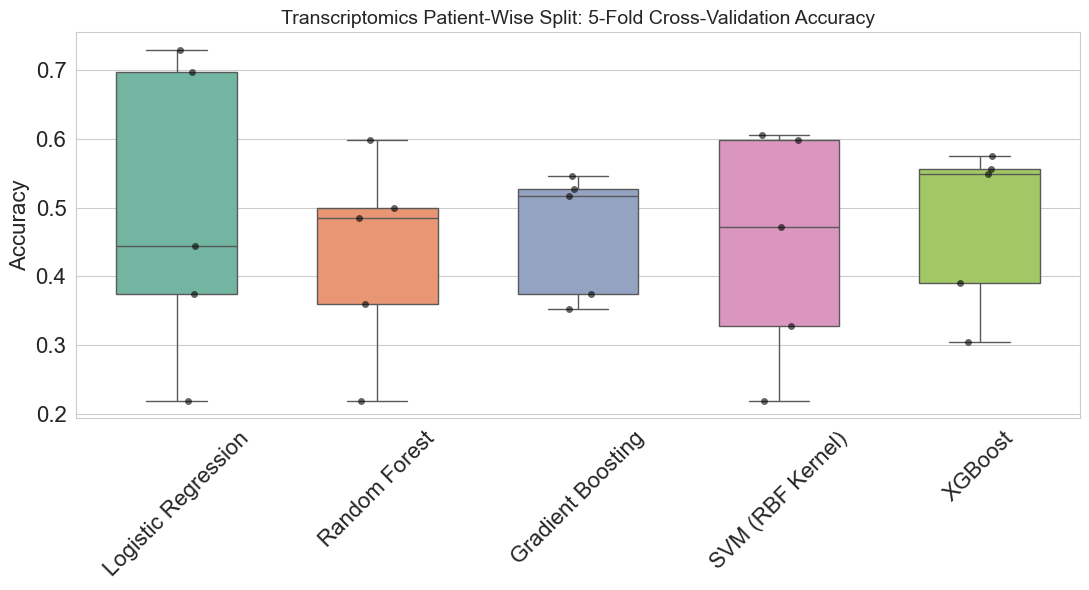

In [52]:
all_folds_df = pd.concat(
    [cv_fold_details[m]["fold_metrics"] for m in models.keys()],
    ignore_index=True
)

plt.figure(figsize=(11, 6))
sns.set_style("whitegrid")

sns.boxplot(
    data=all_folds_df,
    x="model",
    y="accuracy",
    palette="Set2",
    width=0.6
)

sns.stripplot(
    data=all_folds_df,
    x="model",
    y="accuracy",
    color="black",
    size=5,
    jitter=True,
    alpha=0.6
)

plt.xticks(rotation=45, fontsize=16)
plt.yticks(fontsize=16)
plt.xlabel("")
plt.ylabel("Accuracy", fontsize=16)
plt.title("Transcriptomics Patient-Wise Split: 5-Fold Cross-Validation Accuracy", fontsize=14)

plt.tight_layout()
plt.savefig("Results/Transcriptomics/patient_examples/5_fold_accuracy.pdf", bbox_inches="tight")
plt.show()

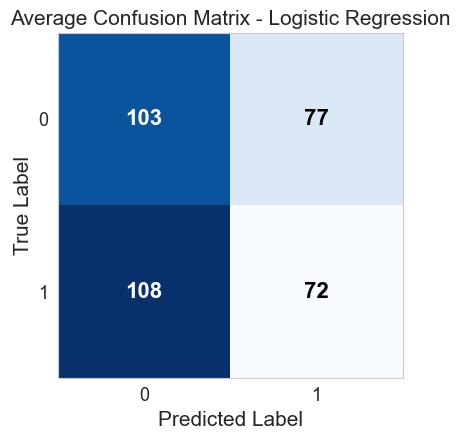

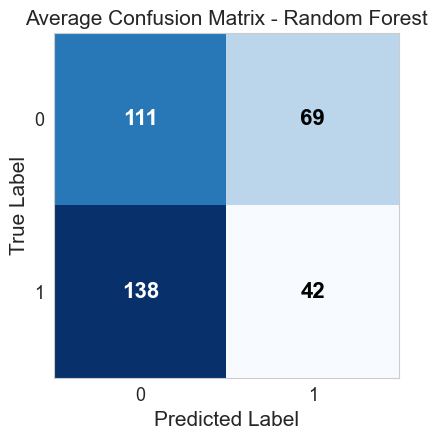

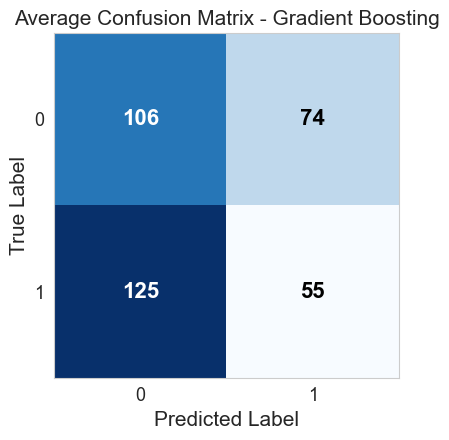

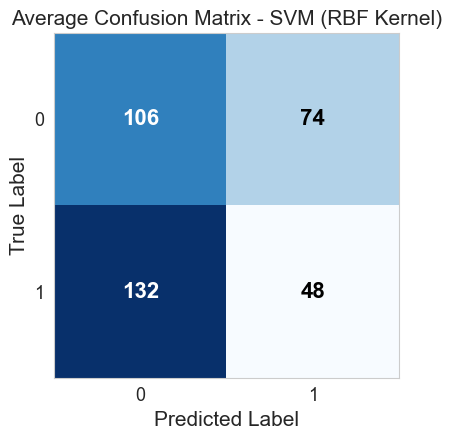

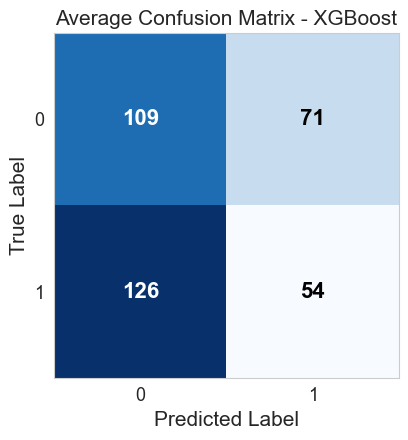

Average confusion matrices saved for all models.


In [53]:
os.makedirs("Experiment_1/Patient_Wise_Split", exist_ok=True)

for model_name, details in cv_fold_details.items():
    cms = details["confusion_matrices"]
    avg_cm = np.sum(cms, axis=0)

    plt.figure(figsize=(4.5, 4.5))
    plt.imshow(avg_cm, cmap="Blues")

    plt.title(f"Average Confusion Matrix - {model_name}", fontsize=15)
    plt.xlabel("Predicted Label", fontsize=15)
    plt.ylabel("True Label", fontsize=15)

    plt.xticks([0, 1], fontsize=13)
    plt.yticks([0, 1], fontsize=13)

    for i in range(avg_cm.shape[0]):
        for j in range(avg_cm.shape[1]):
            plt.text(
                j, i, round(avg_cm[i, j], 1),
                ha="center",
                va="center",
                fontsize=16,
                fontweight="bold",
                color="white" if avg_cm[i, j] > avg_cm.max() / 1.3 else "black"
            )

    plt.tight_layout()
    plt.grid(False)

    plt.savefig(
        f"Results/Transcriptomics/patient_examples/confusion_matrix/Confusion_{model_name.replace(' ', '_').replace('(', '').replace(')', '')}.jpg",
        bbox_inches="tight"
    )
    plt.show()
    plt.close()

print("Average confusion matrices saved for all models.")

# Classification on only flux data

In [55]:
os.makedirs("Results/Fluxomics", exist_ok=True)
os.makedirs("Results/Fluxomics/patient_mean", exist_ok=True)
os.makedirs("Results/Fluxomics/patient_examples", exist_ok=True)  
os.makedirs("Results/Fluxomics/patient_mean/confusion_matrix", exist_ok=True)
os.makedirs("Results/Fluxomics/patient_examples/confusion_matrix", exist_ok=True)  

In [56]:


# flux_df from scFBApy
# flux_df = adata_fluxes.to_df().copy()
flux_df = pd.read_csv('top_60_flux_results.csv')

#remove existing index column
flux_df = flux_df.reset_index(drop=True)
if "Unnamed: 0" in flux_df.columns:
    flux_df = flux_df.drop(columns=["Unnamed: 0"])

# Assign original cell names from subset_from_fixed (the same AnnData used for scFBA)
flux_df.index = final_subset_adata.obs.index.astype(str)



In [57]:
flux_df.shape

(360, 449)

In [58]:
flux_df

,ADSL2r,CYSO,LEUTA,EX_lys__L_e_#,ACOAD8m,r0761,SPMDtex2,t_Lcystin_glu__L,tyr_L_t,GND,...,PRAGSr,HMR_1504,EX_gthrd_e_#,MTHFD2i,r0074,GRTT,ACOAD9m,SMO,GLUDC,DMATT
UA_Endo10298210_AACACACTCACTTCTA-Mareckova,0.000151,0.001000,0.000000,-0.813034,0.000000,0.000143,0.0,0.001000,-0.000213,-0.001000,...,0.000151,0.000027,0.0,-0.019516,0.001000,0.000055,0.000000,0.000027,-0.000000,0.000055
UA_Endo12680031_TTCATGTTCTTCGACC-Mareckova,0.000922,2.922510,0.000000,-0.813034,0.001000,-0.000000,0.0,0.001000,-0.001804,-0.001000,...,0.000922,0.000167,0.0,-4.284792,-0.001000,0.000333,0.001000,0.000167,-0.001000,0.000333
UA_Endo10298210_GTACAACTCCGTCCTA-Mareckova,0.000922,0.013331,0.000000,-0.813034,0.000000,0.000107,0.0,0.001000,-0.001304,0.001000,...,0.000922,0.000167,0.0,-0.000005,0.001000,0.000333,0.001000,0.000167,0.001000,0.000333
UA_Endo10298210_TAGGTTGGTCATCAGT-Mareckova,0.000922,0.001000,0.000000,-0.813034,0.000000,0.000135,0.0,0.001000,-0.001304,0.001800,...,0.000922,0.000167,0.0,0.001368,-0.001000,0.000333,0.001000,0.000167,0.001000,0.000333
UA_Endo10298210_TACATTCAGTATTCCG-Mareckova,0.000083,0.000461,0.000000,-0.813034,0.000000,-0.000143,0.0,0.001000,-0.000182,-0.000850,...,0.000083,0.000015,0.0,0.000849,-0.000877,0.000030,0.000000,0.000015,0.000466,0.000030
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
GSM6605438_CGCCAGAAGTCTGGTT-Huang,0.000088,0.000957,0.000000,-0.813034,0.000000,-0.000143,0.0,0.001000,-0.000124,-0.000977,...,0.000088,0.000016,0.0,0.001510,0.000321,0.000032,0.000039,0.000016,-0.001000,0.000032
GSM5572240_AGAACCTGTGGTTTAC-Lai,0.000126,0.001000,0.000000,-0.813034,0.000000,-0.000055,0.0,0.001000,-0.000178,0.001000,...,0.000126,0.000023,0.0,-0.014972,0.001000,0.000046,0.001000,0.000023,0.001000,0.000046
GSM6605439_TTCATTGTCGTGGAAG-Huang,0.000098,0.000000,0.000000,-0.813034,0.000000,-0.000143,0.0,0.001643,-0.000227,0.000761,...,0.000098,0.000018,0.0,0.000293,0.000230,0.000035,0.000000,0.000018,-0.001000,0.000035
UA_Endo9426399_GGTGAAGTCTAACACG-Mareckova,0.000107,0.000170,0.000000,-0.813034,0.000000,-0.000143,0.0,0.000000,-0.000253,0.001000,...,0.000107,0.000019,0.0,-0.001114,0.001000,0.000039,0.000000,0.000019,0.000000,0.000039


In [59]:

# Make sure flux_df index matches obs index type
flux_df.index = flux_df.index.astype(str)

# Extract the two columns from obs
meta_df = final_subset_adata.obs[['celltype', 'Endometriosis']]

# Join flux_df with the metadata based on the cell index
flux_with_meta = flux_df.join(meta_df, how='inner')
sample_df = final_subset_adata.obs[['sample']]
flux_with_meta = flux_with_meta.join(sample_df, how='inner')


In [60]:
flux_with_meta

,ADSL2r,CYSO,LEUTA,EX_lys__L_e_#,ACOAD8m,r0761,SPMDtex2,t_Lcystin_glu__L,tyr_L_t,GND,...,MTHFD2i,r0074,GRTT,ACOAD9m,SMO,GLUDC,DMATT,celltype,Endometriosis,sample
UA_Endo10298210_AACACACTCACTTCTA-Mareckova,0.000151,0.001000,0.000000,-0.813034,0.000000,0.000143,0.0,0.001000,-0.000213,-0.001000,...,-0.019516,0.001000,0.000055,0.000000,0.000027,-0.000000,0.000055,eStromal,Endometriosis,UA_Endo10298210_FX1176
UA_Endo12680031_TTCATGTTCTTCGACC-Mareckova,0.000922,2.922510,0.000000,-0.813034,0.001000,-0.000000,0.0,0.001000,-0.001804,-0.001000,...,-4.284792,-0.001000,0.000333,0.001000,0.000167,-0.001000,0.000333,eStromal,Endometriosis,UA_Endo12680031_FX1259
UA_Endo10298210_GTACAACTCCGTCCTA-Mareckova,0.000922,0.013331,0.000000,-0.813034,0.000000,0.000107,0.0,0.001000,-0.001304,0.001000,...,-0.000005,0.001000,0.000333,0.001000,0.000167,0.001000,0.000333,eStromal,Endometriosis,UA_Endo10298210_FX1125
UA_Endo10298210_TAGGTTGGTCATCAGT-Mareckova,0.000922,0.001000,0.000000,-0.813034,0.000000,0.000135,0.0,0.001000,-0.001304,0.001800,...,0.001368,-0.001000,0.000333,0.001000,0.000167,0.001000,0.000333,eStromal,Endometriosis,UA_Endo10298210_FX1125
UA_Endo10298210_TACATTCAGTATTCCG-Mareckova,0.000083,0.000461,0.000000,-0.813034,0.000000,-0.000143,0.0,0.001000,-0.000182,-0.000850,...,0.000849,-0.000877,0.000030,0.000000,0.000015,0.000466,0.000030,eStromal,Endometriosis,UA_Endo10298210_FX1125
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
GSM6605438_CGCCAGAAGTCTGGTT-Huang,0.000088,0.000957,0.000000,-0.813034,0.000000,-0.000143,0.0,0.001000,-0.000124,-0.000977,...,0.001510,0.000321,0.000032,0.000039,0.000016,-0.001000,0.000032,Immune_Myeloid,Control,GSM6605438
GSM5572240_AGAACCTGTGGTTTAC-Lai,0.000126,0.001000,0.000000,-0.813034,0.000000,-0.000055,0.0,0.001000,-0.000178,0.001000,...,-0.014972,0.001000,0.000046,0.001000,0.000023,0.001000,0.000046,Immune_Myeloid,Control,GSM5572240
GSM6605439_TTCATTGTCGTGGAAG-Huang,0.000098,0.000000,0.000000,-0.813034,0.000000,-0.000143,0.0,0.001643,-0.000227,0.000761,...,0.000293,0.000230,0.000035,0.000000,0.000018,-0.001000,0.000035,Immune_Myeloid,Control,GSM6605439
UA_Endo9426399_GGTGAAGTCTAACACG-Mareckova,0.000107,0.000170,0.000000,-0.813034,0.000000,-0.000143,0.0,0.000000,-0.000253,0.001000,...,-0.001114,0.001000,0.000039,0.000000,0.000019,0.000000,0.000039,Immune_Myeloid,Control,UA_Endo9426399_FX1146


In [61]:
def _explainer_type(name):
    if name in {"Random Forest", "Gradient Boosting", "XGBoost"}: return "tree"
    if name == "Logistic Regression": return "linear"
    return "kernel"  # SVC

def _align(X, cols):
    X = X if isinstance(X, pd.DataFrame) else pd.DataFrame(X)
    return X.loc[:, list(cols)]


In [62]:
cell_types = ["eStromal", "Glandular", "Immune_Myeloid"]
df = flux_with_meta.copy()
df = df[df["celltype"].isin(cell_types)].copy()
df = df.sort_index()

flux_cols = [c for c in df.columns if c not in ["celltype", "Endometriosis", "sample"]]

patient_df = df.groupby("sample")[flux_cols].mean()
patient_labels = df.groupby("sample")["Endometriosis"].first()

le = LabelEncoder()
y_pat_flux = le.fit_transform(patient_labels.astype(str).values)

X_pat_flux = patient_df.values
patients_flux = patient_df.index.values

print("Patient feature matrix:", X_pat_flux.shape)
print("Number of patients:", len(patients_flux))
print("Classes:", list(le.classes_))

Patient feature matrix: (47, 449)
Number of patients: 47
Classes: ['Control', 'Endometriosis']


/var/folders/3m/0mzmnr390d7_tzpq513jtf8h0000gn/T/ipykernel_1592/3496087360.py:8: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  patient_df = df.groupby("sample")[flux_cols].mean()
/var/folders/3m/0mzmnr390d7_tzpq513jtf8h0000gn/T/ipykernel_1592/3496087360.py:9: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  patient_labels = df.groupby("sample")["Endometriosis"].first()


## Patient mean

In [63]:
strat_key = (df["celltype"].astype(str) + "||" + df["Endometriosis"].astype(str)).values
cv = StratifiedKFold(n_splits=5, shuffle=False)

cv_rows = []
cv_fold_details = {}

models = get_models()
for name, model in models.items():

    fold_metrics = []
    fold_cms = []
    fold_class_counts = []
    fold_predictions = []


    print("MODEL:", name)


    for fold, (tr_idx, te_idx) in enumerate(cv.split(X_pat_flux, y_pat_flux), start=1):

        Xtr, Xte = X_pat_flux[tr_idx], X_pat_flux[te_idx]
        ytr, yte = y_pat_flux[tr_idx], y_pat_flux[te_idx]
    
        train_patients = patients_flux[tr_idx]
        test_patients = patients_flux[te_idx]

        print("\nFold", fold)
        print("Train patients:", len(train_patients))
        print("Test patients :", len(test_patients))
        
        # print("Train patient list:", train_patients)
        # print("Test patient list :", test_patients)

        print("Train class counts:")
        print(pd.Series(ytr).value_counts().sort_index())

        print("Test class counts:")
        print(pd.Series(yte).value_counts().sort_index())

        scaler = StandardScaler()
        Xtr = scaler.fit_transform(Xtr)
        print(Xtr.shape)
        Xte = scaler.transform(Xte)

        model.fit(Xtr, ytr)
        pred = model.predict(Xte)

        acc = accuracy_score(yte, pred)
        prec = precision_score(yte, pred, zero_division=0)
        rec = recall_score(yte, pred, zero_division=0)
        f1 = f1_score(yte, pred, zero_division=0)

        print("Accuracy:", acc)
        print("Precision:", prec)
        print("Recall:", rec)
        print("F1:", f1)

        fold_metrics.append({
            "fold": fold,
            "accuracy": acc,
            "precision": prec,
            "recall": rec,
            "f1_score": f1
        })

        fold_cms.append(confusion_matrix(yte, pred))

        fold_class_counts.append({
            "fold": fold,
            "train_class_0": int(np.sum(ytr == 0)),
            "train_class_1": int(np.sum(ytr == 1)),
            "test_class_0": int(np.sum(yte == 0)),
            "test_class_1": int(np.sum(yte == 1)),
        })

        fold_predictions.append(
            pd.DataFrame({
                "fold": fold,
                "patient_id": test_patients,
                "y_true": yte,
                "y_pred": pred
            })
        )

    df_folds = pd.DataFrame(fold_metrics)

    cv_fold_details[name] = {
        "fold_metrics": df_folds,
        "confusion_matrices": fold_cms,
        "class_counts": pd.DataFrame(fold_class_counts),
        "predictions": pd.concat(fold_predictions, ignore_index=True)
    }

    cv_rows.append({
        "model": name,
        "acc_mean": df_folds["accuracy"].mean(),
        "acc_std": df_folds["accuracy"].std(ddof=0),
        "prec_mean": df_folds["precision"].mean(),
        "prec_std": df_folds["precision"].std(ddof=0),
        "rec_mean": df_folds["recall"].mean(),
        "rec_std": df_folds["recall"].std(ddof=0),
        "f1_mean": df_folds["f1_score"].mean(),
        "f1_std": df_folds["f1_score"].std(ddof=0)
    })

results_df = pd.DataFrame(cv_rows).sort_values(
    ["acc_mean", "f1_mean"], ascending=False
).reset_index(drop=True)

print("\n===== 5-Fold CV Results =====\n")
print(results_df.to_string(index=False))

print("\n===== Fold Results =====\n")
for model_name in models.keys():
    print("\n", model_name)
    print(cv_fold_details[model_name]["fold_metrics"])

print("\n===== Fold Class Counts =====\n")
for model_name in models.keys():
    print("\n", model_name)
    print(cv_fold_details[model_name]["class_counts"])

best_model_name = results_df.iloc[0]["model"]

print("\n===== Best Model =====")
print("Best model:", best_model_name)
print("Mean accuracy:", results_df.iloc[0].acc_mean)

print("\nBest model fold metrics:\n")
print(cv_fold_details[best_model_name]["fold_metrics"])

print("\nBest model class counts:\n")
print(cv_fold_details[best_model_name]["class_counts"])

scaler = StandardScaler()
X_fit = scaler.fit_transform(X_pat_flux)

best_model = models[best_model_name]
best_model.fit(X_fit, y_pat_flux)



MODEL: Logistic Regression

Fold 1
Train patients: 37
Test patients : 10
Train class counts:
0    22
1    15
Name: count, dtype: int64
Test class counts:
0    6
1    4
Name: count, dtype: int64
(37, 449)
Accuracy: 0.6
Precision: 0.5
Recall: 0.25
F1: 0.3333333333333333

Fold 2
Train patients: 37
Test patients : 10
Train class counts:
0    22
1    15
Name: count, dtype: int64
Test class counts:
0    6
1    4
Name: count, dtype: int64
(37, 449)
Accuracy: 0.3
Precision: 0.2
Recall: 0.25
F1: 0.2222222222222222

Fold 3
Train patients: 38
Test patients : 9
Train class counts:
0    22
1    16
Name: count, dtype: int64
Test class counts:
0    6
1    3
Name: count, dtype: int64
(38, 449)
Accuracy: 0.4444444444444444
Precision: 0.0
Recall: 0.0
F1: 0.0

Fold 4
Train patients: 38
Test patients : 9
Train class counts:
0    23
1    15
Name: count, dtype: int64
Test class counts:
0    5
1    4
Name: count, dtype: int64
(38, 449)
Accuracy: 0.5555555555555556
Precision: 0.5
Recall: 0.5
F1: 0.5

Fold 5
T

,objective,'binary:logistic'
,base_score,None
,booster,None
,callbacks,None
,colsample_bylevel,None
,colsample_bynode,None
,colsample_bytree,0.9
,device,None
,early_stopping_rounds,None
,enable_categorical,False
,eval_metric,'logloss'


In [64]:
if "performance_results" not in globals():
    performance_results = {}

if "Fluxomics" not in performance_results:
    performance_results["Fluxomics"] = {}

# Store results for further analysis
performance_results["Fluxomics"]["Patient Mean"] = {
    "summary_table": results_df,
    "all_models": cv_fold_details,
    "best": {
        "best_model_name": best_model_name,
        "best_model": best_model,
        "cv_mean_std": results_df[results_df["model"] == best_model_name].iloc[0].to_dict(),
        "cv_fold_metrics": cv_fold_details[best_model_name]["fold_metrics"],
        "cv_confusion_matrices": cv_fold_details[best_model_name]["confusion_matrices"],
        "class_counts": cv_fold_details[best_model_name]["class_counts"],
        "predictions": cv_fold_details[best_model_name]["predictions"],
    },
    "shap_ready": {
        "best_model": best_model,
        "best_model_name": best_model_name,
        "best_model_metrics": {
            "cv_f1_mean": float(results_df.iloc[0]["f1_mean"]),
            "cv_f1_std": float(results_df.iloc[0]["f1_std"]),
            "cv_accuracy_mean": float(results_df.iloc[0]["acc_mean"]),
            "cv_accuracy_std": float(results_df.iloc[0]["acc_std"]),
            "cv_precision_mean": float(results_df.iloc[0]["prec_mean"]),
            "cv_precision_std": float(results_df.iloc[0]["prec_std"]),
            "cv_recall_mean": float(results_df.iloc[0]["rec_mean"]),
            "cv_recall_std": float(results_df.iloc[0]["rec_std"]),
        },
        "feature_names": list(patient_df.columns),
        "X_eval": X_pat_flux,
        "y_eval": y_pat_flux,
        "patient_ids": patients_flux,
    }
}

print("\nStored keys:")
print(performance_results["Fluxomics"]["Patient Mean"].keys())
print(performance_results["Fluxomics"]["Patient Mean"]["best"].keys())
print(performance_results["Fluxomics"]["Patient Mean"]["shap_ready"].keys())


Stored keys:
dict_keys(['summary_table', 'all_models', 'best', 'shap_ready'])
dict_keys(['best_model_name', 'best_model', 'cv_mean_std', 'cv_fold_metrics', 'cv_confusion_matrices', 'class_counts', 'predictions'])
dict_keys(['best_model', 'best_model_name', 'best_model_metrics', 'feature_names', 'X_eval', 'y_eval', 'patient_ids'])


/var/folders/3m/0mzmnr390d7_tzpq513jtf8h0000gn/T/ipykernel_1592/964224154.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


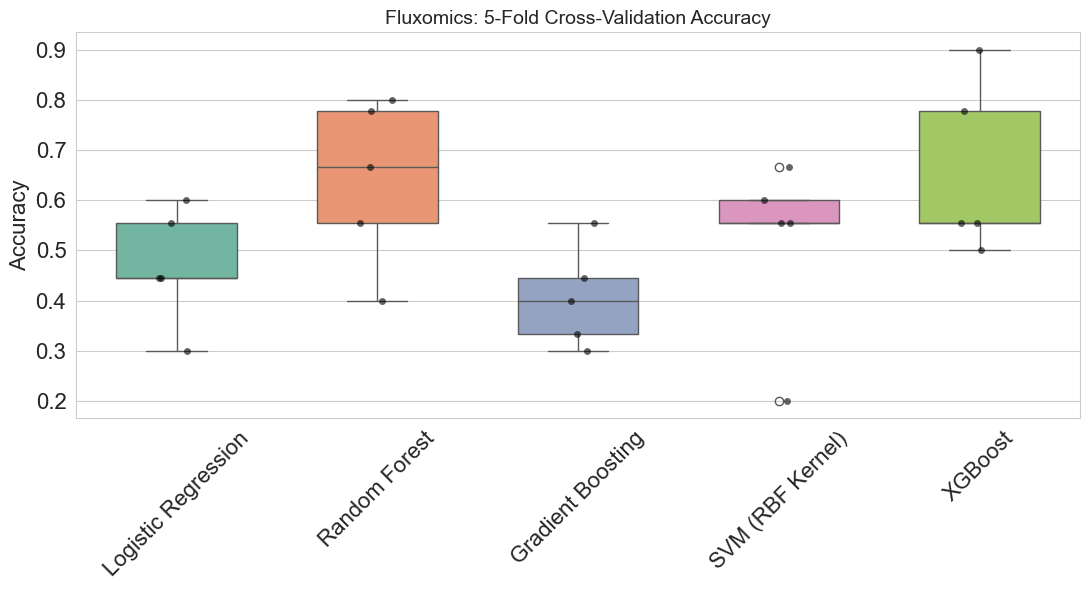

In [65]:
all_folds_df = pd.concat(
    [cv_fold_details[m]["fold_metrics"].assign(model=m) for m in models.keys()],
    ignore_index=True
)

plt.figure(figsize=(11, 6))
sns.set_style("whitegrid")

sns.boxplot(
    data=all_folds_df,
    x="model",
    y="accuracy",
    palette="Set2",
    width=0.6
)

sns.stripplot(
    data=all_folds_df,
    x="model",
    y="accuracy",
    color="black",
    size=5,
    jitter=True,
    alpha=0.6
)

plt.xticks(rotation=45, fontsize=16)
plt.yticks(fontsize=16)
plt.xlabel("")
plt.ylabel("Accuracy", fontsize=16)
plt.title("Fluxomics: 5-Fold Cross-Validation Accuracy", fontsize=14)

plt.tight_layout()
plt.savefig("Results/Fluxomics/patient_mean/fold_Accuracy.pdf", bbox_inches="tight")
plt.show()

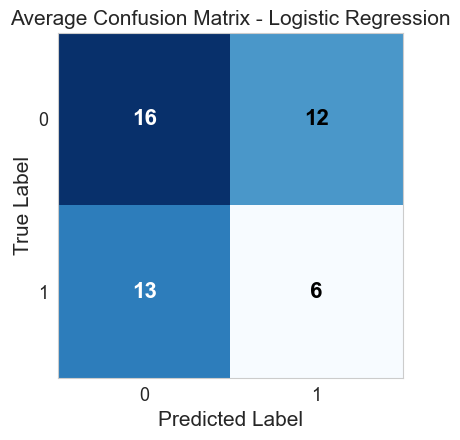

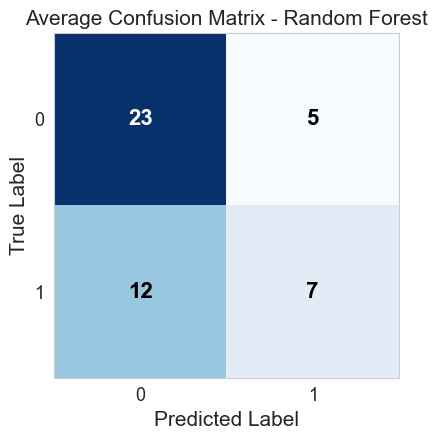

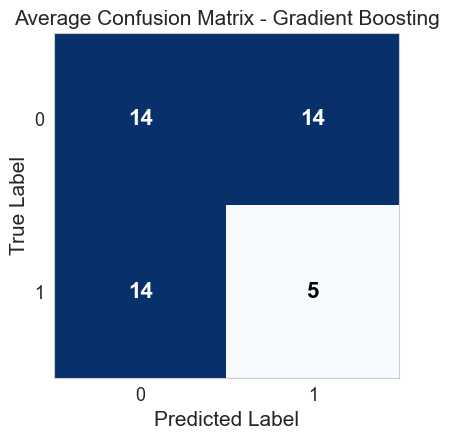

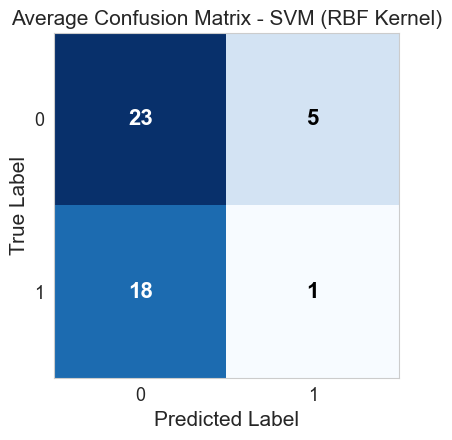

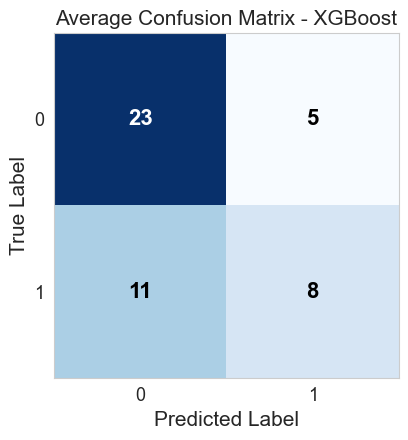

Average confusion matrices saved for all models.


In [66]:
os.makedirs("Experiment_2/Patient_mean", exist_ok=True)

for model_name, details in cv_fold_details.items():
    cms = details["confusion_matrices"]
    avg_cm = np.sum(cms, axis=0)

    plt.figure(figsize=(4.5, 4.5))
    plt.imshow(avg_cm, cmap="Blues")

    plt.title(f"Average Confusion Matrix - {model_name}", fontsize=15)
    plt.xlabel("Predicted Label", fontsize=15)
    plt.ylabel("True Label", fontsize=15)

    plt.xticks([0, 1], fontsize=13)
    plt.yticks([0, 1], fontsize=13)

    for i in range(avg_cm.shape[0]):
        for j in range(avg_cm.shape[1]):
            plt.text(
                j, i, round(avg_cm[i, j], 1),
                ha="center",
                va="center",
                fontsize=16,
                fontweight="bold",
                color="white" if avg_cm[i, j] > avg_cm.max() / 1.3 else "black"
            )

    plt.tight_layout()
    plt.grid(False)

    plt.savefig(
        f"Results/Fluxomics/patient_mean/confusion_matrix/Confusion_{model_name.replace(' ', '_').replace('(', '').replace(')', '')}.pdf",
        bbox_inches="tight"
    )
    plt.show()
    plt.close()

print("Average confusion matrices saved for all models.")

## Patient Examples

In [67]:
df["sample"] = adata.obs.loc[df.index, "sample"].values

flux_cols = flux_df.columns.tolist()
X_all = df.loc[:, flux_cols].copy()
y_all = df["Endometriosis"].astype(str)

le = LabelEncoder()
y_enc = le.fit_transform(y_all)

X_np = X_all.to_numpy()
y_np = np.array(y_enc)

strat_key = (df["celltype"].astype(str) + "||" + df["Endometriosis"].astype(str)).values
groups = df["sample"].astype(str).values

cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)

pos = int(np.sum(y_np == 1))
neg = int(np.sum(y_np == 0))
scale_pos_weight = float(neg / max(pos, 1))

In [68]:
cv_rows = []
cv_fold_details = {}

models = get_models()
for name, model in models.items():
    fold_rows = []
    fold_cms = []
    fold_class_counts = []
    fold_predictions = []

    print("\n" + "=" * 70)
    print("MODEL:", name)
    print("=" * 70)

    for fold, (tr, te) in enumerate(cv.split(X_np, strat_key, groups=groups), start=1):
        Xtr, Xte = X_np[tr], X_np[te]
        ytr, yte = y_np[tr], y_np[te]

        train_patients = pd.Series(groups[tr]).unique()
        test_patients = pd.Series(groups[te]).unique()
        overlap = set(train_patients).intersection(set(test_patients))

        print(f"\nFold {fold}")
        print("Train cells   :", len(tr))
        print("Test cells    :", len(te))
        # print("Train patients:", len(train_patients))
        # print("Test patients :", len(test_patients))
        print("Patient overlap:", len(overlap))

        print("Train class counts:")
        print(pd.Series(ytr).value_counts().sort_index())

        print("Test class counts:")
        print(pd.Series(yte).value_counts().sort_index())

        scaler = StandardScaler()
        Xtr = scaler.fit_transform(Xtr)
        Xte = scaler.transform(Xte)

        print(Xtr.shape)
        model.fit(Xtr, ytr)
        pred = model.predict(Xte)

        fold_rows.append({
            "fold": fold,
            "accuracy": float(accuracy_score(yte, pred)),
            "precision": float(precision_score(yte, pred, zero_division=0)),
            "recall": float(recall_score(yte, pred, zero_division=0)),
            "f1_score": float(f1_score(yte, pred, zero_division=0)),
        })

        fold_cms.append(confusion_matrix(yte, pred))

        fold_class_counts.append({
            "fold": fold,
            "train_class_0": int(np.sum(ytr == 0)),
            "train_class_1": int(np.sum(ytr == 1)),
            "test_class_0": int(np.sum(yte == 0)),
            "test_class_1": int(np.sum(yte == 1)),
        })

        fold_predictions.append(
            pd.DataFrame({
                "fold": fold,
                "patient_id": groups[te],
                "y_true": yte,
                "y_pred": pred
            })
        )

    df_folds = pd.DataFrame(fold_rows)

    cv_fold_details[name] = {
        "fold_metrics": df_folds,
        "confusion_matrices": fold_cms,
        "class_counts": pd.DataFrame(fold_class_counts),
        "predictions": pd.concat(fold_predictions, ignore_index=True)
    }

    cv_rows.append({
        "model": name,
        "acc_mean": df_folds["accuracy"].mean(),
        "acc_std": df_folds["accuracy"].std(ddof=0),
        "prec_mean": df_folds["precision"].mean(),
        "prec_std": df_folds["precision"].std(ddof=0),
        "rec_mean": df_folds["recall"].mean(),
        "rec_std": df_folds["recall"].std(ddof=0),
        "f1_mean": df_folds["f1_score"].mean(),
        "f1_std": df_folds["f1_score"].std(ddof=0),
    })

results_df = pd.DataFrame(cv_rows).sort_values(
    ["acc_mean", "f1_mean"], ascending=False
).reset_index(drop=True)

print("\n===== 5-Fold CV Results (Mean) =====\n")
print(results_df.to_string(index=False))

print("\n===== Fold-wise results (all models) =====\n")
for model_name in models.keys():
    print(f"\n----- {model_name} -----\n")
    print(cv_fold_details[model_name]["fold_metrics"].to_string(index=False))

print("\n===== Fold-wise class counts (all models) =====\n")
for model_name in models.keys():
    print(f"\n----- {model_name} -----\n")
    print(cv_fold_details[model_name]["class_counts"].to_string(index=False))

best_model_name = results_df.iloc[0]["model"]
best_acc = results_df.iloc[0]["acc_mean"]

print("\n===== Best Model =====\n")
print("Best Model:", best_model_name)
print(f"Best Model Accuracy (5-fold mean): {best_acc:.3f}")

print("\nBest model fold-wise metrics:\n")
print(cv_fold_details[best_model_name]["fold_metrics"].to_string(index=False))

print("\nBest model fold-wise class counts:\n")
print(cv_fold_details[best_model_name]["class_counts"].to_string(index=False))

scaler = StandardScaler()
X_fit = scaler.fit_transform(X_np)

best_model = models[best_model_name]
best_model.fit(X_fit, y_np)




MODEL: Logistic Regression

Fold 1
Train cells   : 324
Test cells    : 36
Patient overlap: 0
Train class counts:
0    166
1    158
Name: count, dtype: int64
Test class counts:
0    14
1    22
Name: count, dtype: int64
(324, 449)

Fold 2
Train cells   : 255
Test cells    : 105
Patient overlap: 0
Train class counts:
0    127
1    128
Name: count, dtype: int64
Test class counts:
0    53
1    52
Name: count, dtype: int64
(255, 449)

Fold 3
Train cells   : 296
Test cells    : 64
Patient overlap: 0
Train class counts:
0    158
1    138
Name: count, dtype: int64
Test class counts:
0    22
1    42
Name: count, dtype: int64
(296, 449)

Fold 4
Train cells   : 327
Test cells    : 33
Patient overlap: 0
Train class counts:
0    151
1    176
Name: count, dtype: int64
Test class counts:
0    29
1     4
Name: count, dtype: int64
(327, 449)

Fold 5
Train cells   : 238
Test cells    : 122
Patient overlap: 0
Train class counts:
0    118
1    120
Name: count, dtype: int64
Test class counts:
0    62
1    

,C,1.0
,kernel,'rbf'
,degree,3
,gamma,'scale'
,coef0,0.0
,shrinking,True
,probability,True
,tol,0.001
,cache_size,200
,class_weight,None
,verbose,False


In [69]:
if "performance_results" not in globals():
    performance_results = {}

if "Fluxomics" not in performance_results:
    performance_results["Fluxomics"] = {}

performance_results["Fluxomics"]["Patient-Wise Split"] = {
    "summary_table": results_df,
    "all_models": cv_fold_details,
    "best": {
        "best_model_name": best_model_name,
        "best_model": best_model,
        "cv_mean_std": results_df[results_df["model"] == best_model_name].iloc[0].to_dict(),
        "cv_fold_metrics": cv_fold_details[best_model_name]["fold_metrics"],
        "cv_confusion_matrices": cv_fold_details[best_model_name]["confusion_matrices"],
        "class_counts": cv_fold_details[best_model_name]["class_counts"],
        "predictions": cv_fold_details[best_model_name]["predictions"],
    },
    "shap_ready": {
        "best_model": best_model,
        "best_model_name": best_model_name,
        "best_model_metrics": {
            "cv_f1_mean": float(results_df.iloc[0]["f1_mean"]),
            "cv_f1_std": float(results_df.iloc[0]["f1_std"]),
            "cv_accuracy_mean": float(results_df.iloc[0]["acc_mean"]),
            "cv_accuracy_std": float(results_df.iloc[0]["acc_std"]),
            "cv_precision_mean": float(results_df.iloc[0]["prec_mean"]),
            "cv_precision_std": float(results_df.iloc[0]["prec_std"]),
            "cv_recall_mean": float(results_df.iloc[0]["rec_mean"]),
            "cv_recall_std": float(results_df.iloc[0]["rec_std"]),
        },
        "X_eval": X_np,
        "y_eval": y_np,
        "patient_ids": groups,
    }
}

print("\nStored keys:")
print(performance_results["Fluxomics"]["Patient-Wise Split"].keys())
print(performance_results["Fluxomics"]["Patient-Wise Split"]["best"].keys())
print(performance_results["Fluxomics"]["Patient-Wise Split"]["shap_ready"].keys())


Stored keys:
dict_keys(['summary_table', 'all_models', 'best', 'shap_ready'])
dict_keys(['best_model_name', 'best_model', 'cv_mean_std', 'cv_fold_metrics', 'cv_confusion_matrices', 'class_counts', 'predictions'])
dict_keys(['best_model', 'best_model_name', 'best_model_metrics', 'X_eval', 'y_eval', 'patient_ids'])


/var/folders/3m/0mzmnr390d7_tzpq513jtf8h0000gn/T/ipykernel_1592/2114513105.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


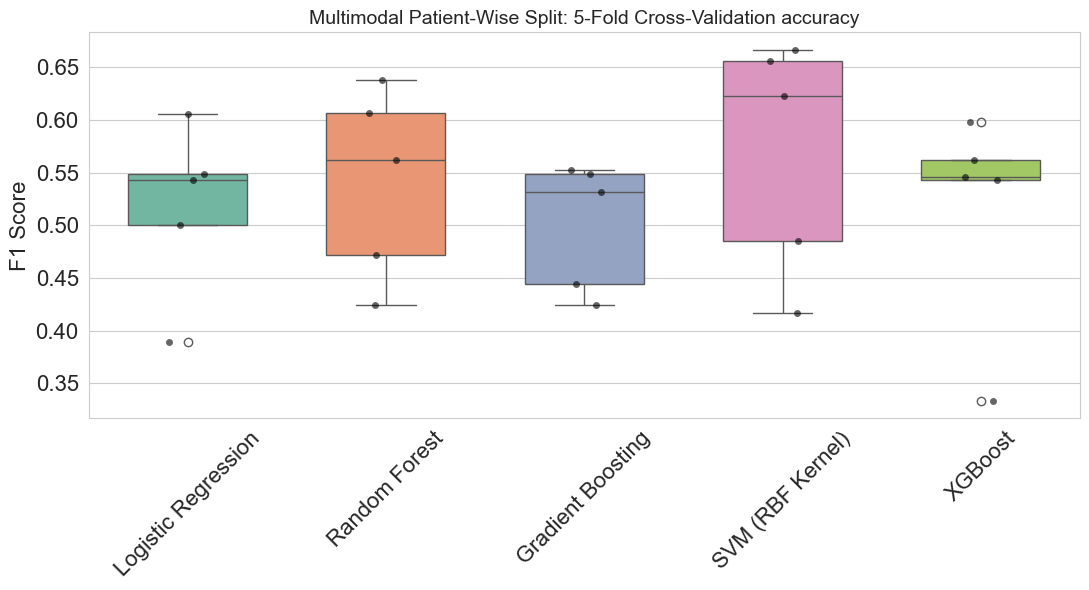

In [70]:
all_folds_df = pd.concat(
    [cv_fold_details[m]["fold_metrics"].assign(model=m) for m in models.keys()],
    ignore_index=True
)

plt.figure(figsize=(11, 6))
sns.set_style("whitegrid")

sns.boxplot(
    data=all_folds_df,
    x="model",
    y="accuracy",
    palette="Set2",
    width=0.6
)

sns.stripplot(
    data=all_folds_df,
    x="model",
    y="accuracy",
    color="black",
    size=5,
    jitter=True,
    alpha=0.6
)

plt.xticks(rotation=45, fontsize=16)
plt.yticks(fontsize=16)
plt.xlabel("")
plt.ylabel("F1 Score", fontsize=16)
plt.title("Multimodal Patient-Wise Split: 5-Fold Cross-Validation accuracy", fontsize=14)

plt.tight_layout()
plt.savefig("Results/Fluxomics/patient_examples/5_fold_accuracy.pdf", bbox_inches="tight")
plt.show()

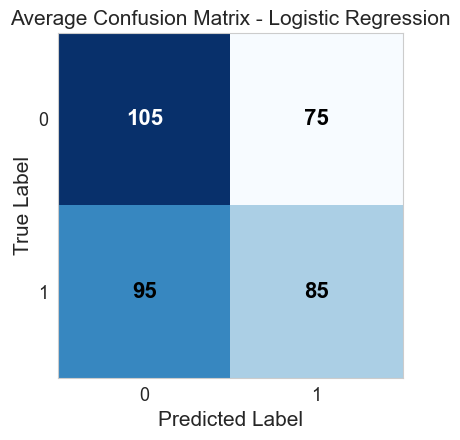

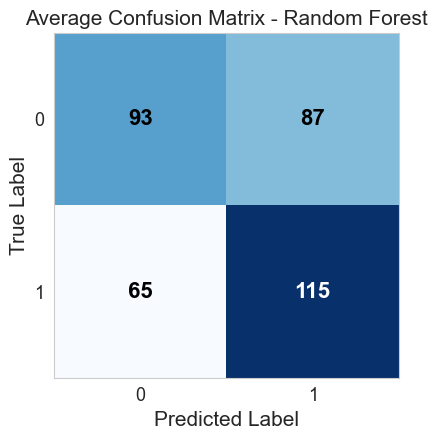

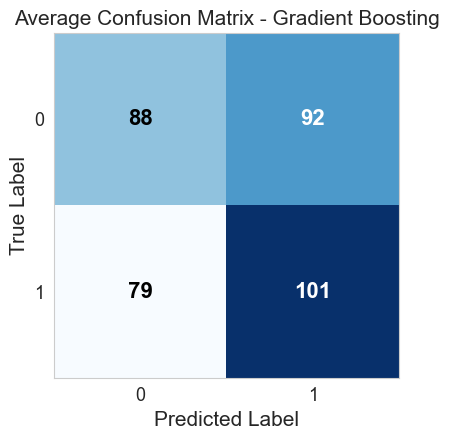

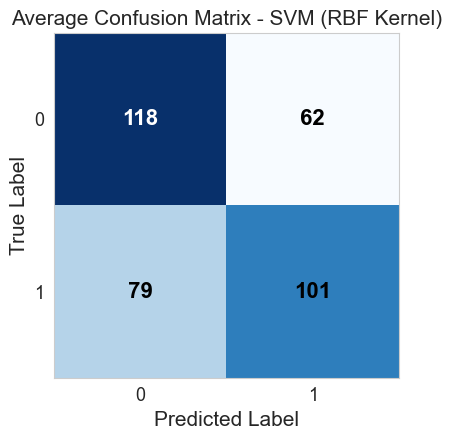

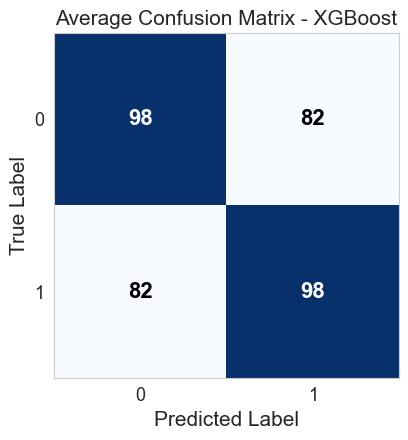

Average confusion matrices saved for all models.


In [71]:


for model_name, details in cv_fold_details.items():
    cms = details["confusion_matrices"]
    avg_cm = np.sum(cms, axis=0)

    plt.figure(figsize=(4.5, 4.5))
    plt.imshow(avg_cm, cmap="Blues")

    plt.title(f"Average Confusion Matrix - {model_name}", fontsize=15)
    plt.xlabel("Predicted Label", fontsize=15)
    plt.ylabel("True Label", fontsize=15)

    plt.xticks([0, 1], fontsize=13)
    plt.yticks([0, 1], fontsize=13)

    for i in range(avg_cm.shape[0]):
        for j in range(avg_cm.shape[1]):
            plt.text(
                j, i, round(avg_cm[i, j], 1),
                ha="center",
                va="center",
                fontsize=16,
                fontweight="bold",
                color="white" if avg_cm[i, j] > avg_cm.max() / 1.1 else "black"
            )

    plt.tight_layout()
    plt.grid(False)

    plt.savefig(
        f"Results/Fluxomics/patient_examples/confusion_matrix/Confusion_{model_name.replace(' ', '_').replace('(', '').replace(')', '')}.jpg",
        bbox_inches="tight"
    )
    plt.show()
    plt.close()

print("Average confusion matrices saved for all models.")

# Shap Analysis on Fluxomics and Transcriptomics Seperately

## Patient mean

In [73]:
entry = performance_results["Transcriptomics"]["Patient Mean"]["shap_ready"]
best_model = entry["best_model"]
print(best_model)

SVC(probability=True, random_state=42)


In [75]:
os.makedirs("Results/SHAP", exist_ok=True)


In [74]:

import shap

def get_top100_shap(entry):
    best_model = entry["best_model"]
    X_eval = entry["X_eval"]
    feature_names = entry["feature_names"]

    if isinstance(X_eval, pd.DataFrame):
        X_df = X_eval.copy()
    else:
        X_df = pd.DataFrame(X_eval, columns=feature_names)

    X_sample = X_df.sample(min(500, len(X_df)), random_state=0)

    model_name = type(best_model).__name__

    if model_name in ["RandomForestClassifier", "GradientBoostingClassifier", "XGBClassifier"]:
        explainer = shap.TreeExplainer(best_model)
        shap_values = explainer.shap_values(X_sample)

    elif model_name == "LogisticRegression":
        explainer = shap.LinearExplainer(best_model, X_sample)
        shap_values = explainer.shap_values(X_sample)

    elif model_name == "SVC":
        background = X_sample.sample(min(100, len(X_sample)), random_state=0)
        explainer = shap.KernelExplainer(best_model.predict_proba, background)
        shap_values = explainer.shap_values(X_sample)

    else:
        raise ValueError(f"Unsupported model type: {model_name}")

    if isinstance(shap_values, list):
        shap_values = shap_values[1]
    
    shap_values = np.array(shap_values)
    
    if shap_values.ndim == 3:
        shap_values = shap_values[:, :, 1]
    
    mean_abs_shap = np.mean(np.abs(shap_values), axis=0).ravel()
    
    print("X_df shape:", X_df.shape)
    print("SHAP shape:", shap_values.shape)
    print("mean_abs_shap shape:", mean_abs_shap.shape)
    
    top100 = pd.DataFrame({
        "feature": X_df.columns,
        "mean_abs_shap": mean_abs_shap
    }).sort_values("mean_abs_shap", ascending=False).head(100).reset_index(drop=True)

    return top100


top100_transcriptomics_pm = get_top100_shap(
    performance_results["Transcriptomics"]["Patient Mean"]["shap_ready"]
)

print("Top 10 — Transcriptomics Patient Mean")
print(top100_transcriptomics_pm.head(10))


top100_fluxomics_pm = get_top100_shap(
    performance_results["Fluxomics"]["Patient Mean"]["shap_ready"]
)

print("\nTop 10 — Fluxomics Patient Mean")
print(top100_fluxomics_pm.head(10))

  0%|          | 0/47 [00:00<?, ?it/s]

X_df shape: (47, 1000)
SHAP shape: (47, 1000)
mean_abs_shap shape: (1000,)
Top 10 — Transcriptomics Patient Mean
   feature  mean_abs_shap
0      FTL       0.065022
1      LYZ       0.011371
2  SCGB1D2       0.009860
3  SCGB2A1       0.008597
4     SPP1       0.006892
5   COL1A1       0.006013
6  HLA-DRA       0.004793
7   COL3A1       0.002870
8      MGP       0.002356
9     APOE       0.002032
X_df shape: (47, 449)
SHAP shape: (47, 449)
mean_abs_shap shape: (449,)

Top 10 — Fluxomics Patient Mean
                     feature  mean_abs_shap
0                    asp_L_t       0.820682
1                    glu_L_t       0.432067
2                   AKGMALtm       0.380240
3                   HMR_4964       0.325474
4  carnitineAcylTransferaseI       0.303665
5                   HMGCOASm       0.298725
6                      HDCAt       0.293421
7                      PSP_L       0.283579
8                     THRD_L       0.253945
9                     ACONTm       0.231552


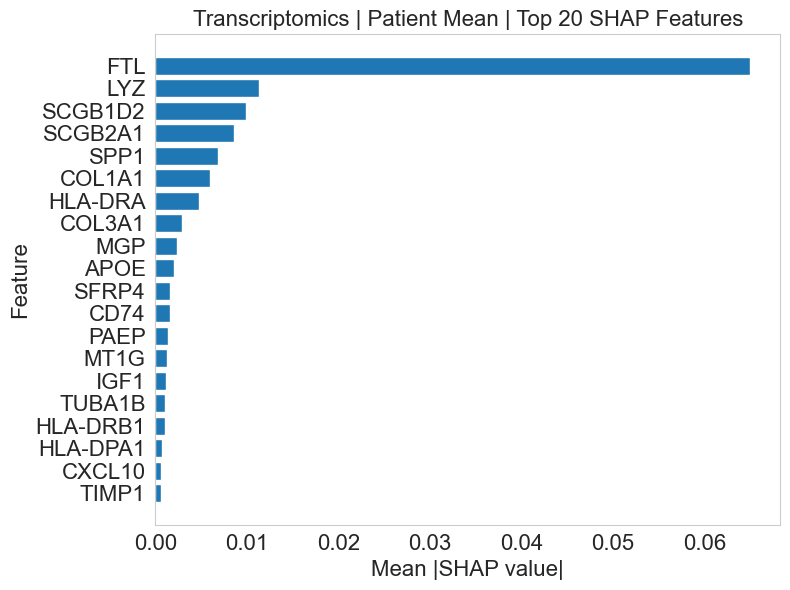

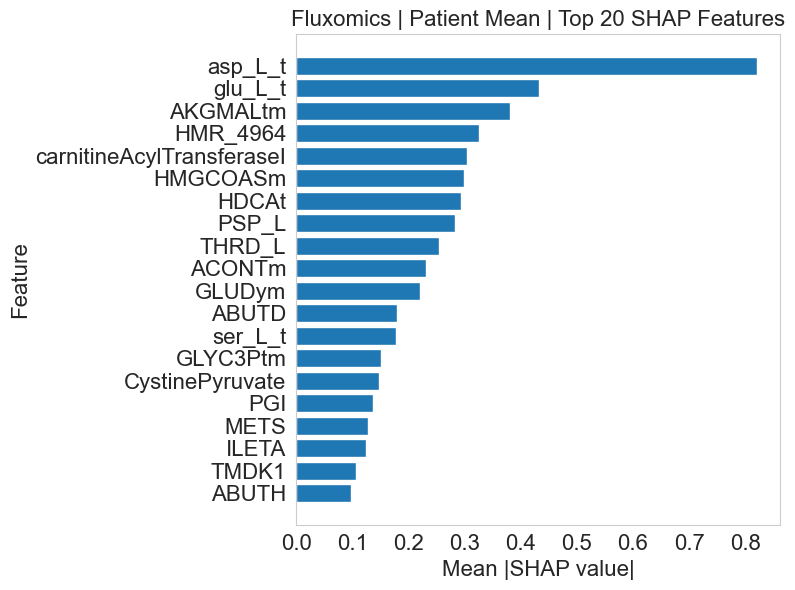

In [76]:


# -------- Transcriptomics Plot --------
plt.figure(figsize=(8, 6))
plt.barh(
    top100_transcriptomics_pm["feature"].head(20)[::-1],
    top100_transcriptomics_pm["mean_abs_shap"].head(20)[::-1]
)

plt.xlabel("Mean |SHAP value|", fontsize=16)
plt.ylabel("Feature", fontsize=16)
plt.title("Transcriptomics | Patient Mean | Top 20 SHAP Features", fontsize=16)

plt.xticks(fontsize=16)
plt.yticks(fontsize=16)

plt.grid(False)
plt.tight_layout()

plt.savefig("Results/SHAP/transcriptomics_top20_shap.pdf", format="pdf")
plt.show()


# -------- Fluxomics Plot --------
plt.figure(figsize=(8, 6))
plt.barh(
    top100_fluxomics_pm["feature"].head(20)[::-1],
    top100_fluxomics_pm["mean_abs_shap"].head(20)[::-1]
)

plt.xlabel("Mean |SHAP value|", fontsize=16)
plt.ylabel("Feature", fontsize=16)
plt.title("Fluxomics | Patient Mean | Top 20 SHAP Features", fontsize=16)

plt.xticks(fontsize=16)
plt.yticks(fontsize=16)

plt.grid(False)
plt.tight_layout()

plt.savefig("Results/SHAP/fluxomics_top20_shap.pdf", format="pdf")
plt.show()

# Multimodal Classification

In [77]:
os.makedirs("Results/Multimodal", exist_ok=True)
os.makedirs("Results/Multimodal/patient_mean", exist_ok=True)
os.makedirs("Results/Multimodal/patient_examples", exist_ok=True)  
os.makedirs("Results/Multimodal/patient_mean/confusion_matrix", exist_ok=True)
os.makedirs("Results/Multimodal/patient_examples/confusion_matrix", exist_ok=True)  


In [78]:
from scipy.sparse import issparse
CELLTYPES = ['eStromal', 'Glandular', 'Immune_Myeloid']
LABEL_COL = 'Endometriosis'
CELTYPE_COL = 'celltype'
SEED = 42
N_SPLITS = 5

In [79]:
# Collecting top features based on SHAP results
flux_df = flux_with_meta.copy()
cell_names = flux_df.index.values
top100_flux = top100_fluxomics_pm
top100_transcriptomics = top100_transcriptomics_pm
# flux top features that exist
flux_feature_names = [f for f in top100_flux["feature"] if f in flux_df.columns]

# metadata columns to carry
meta_cols = [c for c in [LABEL_COL, CELTYPE_COL, "cell_name"] if c in flux_df.columns]
flux_df_sub = flux_df[meta_cols + flux_feature_names].copy()

# transcriptomics matrix aligned to flux cells
adata_cell_names = adata.obs.index.values
name_to_idx = {name: i for i, name in enumerate(adata_cell_names)}

common_cells = [c for c in cell_names if c in name_to_idx]
if len(common_cells) == 0:
    raise ValueError("No overlapping cell names between flux_with_meta.index and adata.obs.index")

cell_indices = [name_to_idx[c] for c in common_cells]

X_rna = adata.X[cell_indices, :]
if issparse(X_rna):
    tx_full = pd.DataFrame.sparse.from_spmatrix(X_rna, index=common_cells, columns=adata.var_names)
else:
    tx_full = pd.DataFrame(X_rna, index=common_cells, columns=adata.var_names)

# transcriptomics top features that exist
tx_feature_names = [g for g in top100_transcriptomics["feature"] if g in tx_full.columns]
tx_sub = tx_full.loc[:, tx_feature_names].copy()

# merge (inner join on cell names)
combined = pd.merge(
    flux_df_sub,
    tx_sub,
    left_index=True,
    right_index=True,
    how="inner",
)

# keep only your 3 cell types (same as your pipeline)
if CELTYPE_COL in combined.columns:
    combined = combined[combined[CELTYPE_COL].isin(CELLTYPES)].copy()

# stable order for deterministic folds
combined = combined.sort_index()

print("Combined dataset shape:", combined.shape)


Combined dataset shape: (360, 202)


In [80]:
combined

,Endometriosis,celltype,asp_L_t,glu_L_t,AKGMALtm,HMR_4964,carnitineAcylTransferaseI,HMGCOASm,HDCAt,PSP_L,...,BCAT1,BCKDHB,BCL2A1,BCL2L10,BCL2L14,BDKRB2,BGN,BHLHE41,BID,BIRC3
4861STDY7387181_ATGGGAGTCCGCATAA-GarciaAlonso,Control,eStromal,-0.001497,-0.001000,0.000000,0.000422,-0.000279,0.000000,0.001757,0.000000,...,1.0,0,0,0,0,1.0,7.0,1.0,2.0,0
4861STDY7387181_CCTATTACACTCTGTC-GarciaAlonso,Control,eStromal,-0.008045,0.000165,0.004000,-0.000000,-0.000000,-0.000000,0.000414,-0.001000,...,1.0,0,0,0,0,1.0,5.0,1.0,0,0
4861STDY7387181_GCGCCAAAGCTGAACG-GarciaAlonso,Control,Immune_Myeloid,0.005895,-0.001000,0.001448,0.001289,-0.000471,-0.000000,0.000298,-0.000887,...,0,0,0,0,0,2.0,5.0,7.0,0,0
4861STDY7387182_ACACTGACACCTGGTG-GarciaAlonso,Control,eStromal,0.002868,-0.001000,0.001000,0.007546,-0.000429,0.000000,0.001819,0.001000,...,0,0,0,0,0,4.0,9.0,1.0,3.0,0
4861STDY7387182_TCTCATACATAACCTG-GarciaAlonso,Control,eStromal,-0.004913,-0.001000,-0.005000,-0.001000,-0.000074,0.000000,0.000777,-0.001000,...,0,0,0,0,0,0,6.0,1.0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
UA_Endo9426402_TTACTGTCACTCGATA-Mareckova,Endometriosis,Glandular,0.000000,0.000012,0.001769,0.000000,-0.000443,-0.000000,0.000469,0.001000,...,40.0,0,0,1.0,0,0,0,0,0,0
UA_Endo9426402_TTCGATTGTCCTATAG-Mareckova,Endometriosis,Glandular,0.000000,0.002476,0.002166,0.003112,-0.000449,0.000000,0.002096,0.001000,...,9.0,1.0,0,0,0,0,0,0,0,8.0
UA_Endo9426402_TTGGGTATCACTCTTA-Mareckova,Endometriosis,Glandular,0.000409,-0.001000,-0.000132,-0.000000,-0.000242,0.000037,0.000631,-0.000321,...,0,2.0,0,2.0,1.0,0,0,0,0,17.0
UA_Endo9426402_TTGGTTTCATCCGGCA-Mareckova,Endometriosis,Glandular,-0.000612,-0.001000,-0.000012,0.001000,-0.000175,0.000000,0.000256,-0.001000,...,17.0,0,0,0,0,0,0,12.0,0,1.0


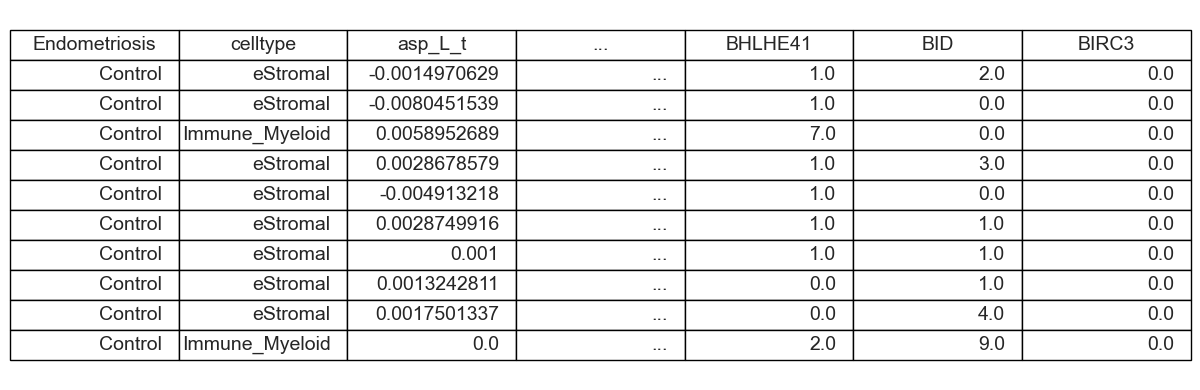

In [81]:
# Select first 3 and last 3 columns
preview_df = pd.concat(
    [combined.iloc[:, :3], combined.iloc[:, -3:]],
    axis=1
)

# Add "..." column in the middle
preview_df.insert(3, "...", ["..." for _ in range(len(preview_df))])

# Take a small sample (e.g., first 10 rows)
preview_df = preview_df.head(10)

# Plot as table
plt.figure(figsize=(12, 4))
plt.axis('off')

table = plt.table(
    cellText=preview_df.values,
    colLabels=preview_df.columns,
    loc='center'
)

# Make text larger
table.auto_set_font_size(False)
table.set_fontsize(14)
table.scale(1.2, 1.5)

plt.tight_layout()
plt.savefig("Results/Multimodal/multimodal_preview.pdf", bbox_inches="tight")
plt.show()

In [82]:
meta_cols = [c for c in [LABEL_COL, CELTYPE_COL, "cell_name"] if c in combined.columns]
feature_cols = [c for c in combined.columns if c not in meta_cols]

X_all = combined[feature_cols].copy()
y_all = combined[LABEL_COL].astype(str).copy()

# encode labels once
le_y = LabelEncoder()
y_enc = le_y.fit_transform(y_all)

print("Classes:", list(le_y.classes_))
print("X shape:", X_all.shape)

# stratify by (celltype + label) to keep balance in each fold
if CELTYPE_COL in combined.columns:
    strat_key = (combined[CELTYPE_COL].astype(str) + "||" + combined[LABEL_COL].astype(str)).values
else:
    strat_key = y_enc

cv = StratifiedKFold(n_splits=N_SPLITS, shuffle=False)

Classes: ['Control', 'Endometriosis']
X shape: (360, 200)


In [83]:
pos = np.sum(y_enc == 1)
neg = np.sum(y_enc == 0)
scale_pos_weight = float(neg / max(pos, 1))

models = {
    "Logistic Regression": LogisticRegression(max_iter=2000, random_state=SEED),
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=SEED, n_jobs=1),
    "Gradient Boosting": GradientBoostingClassifier(random_state=SEED),
    "SVM (RBF Kernel)": SVC(kernel="rbf", probability=True, random_state=SEED),
    "XGBoost": XGBClassifier(
        eval_metric="logloss",
        random_state=SEED,
        nthread=1,          # deterministic
        tree_method="hist",
        max_depth=3,
        learning_rate=0.05,
        n_estimators=900,
        subsample=0.9,
        colsample_bytree=0.9,
        reg_lambda=2.0,
        scale_pos_weight=scale_pos_weight,
    ),
}

## Patient Mean

In [84]:

combined["sample"] = adata.obs.loc[combined.index, "sample"].values

# metadata + feature columns
meta_cols = [c for c in [LABEL_COL, CELTYPE_COL, "cell_name", "sample"] if c in combined.columns]
feature_cols = [c for c in combined.columns if c not in meta_cols]

print("Combined shape:", combined.shape)
print("Number of multimodal features:", len(feature_cols))
print("Metadata columns:", meta_cols)

Combined shape: (360, 203)
Number of multimodal features: 200
Metadata columns: ['Endometriosis', 'celltype', 'sample']


In [85]:
df_mm = combined.copy()

patient_df = df_mm.groupby("sample")[feature_cols].mean()
patient_labels = df_mm.groupby("sample")[LABEL_COL].first().astype(str)

le_pat = LabelEncoder()
y_pat_mm = le_pat.fit_transform(patient_labels.values)

X_pat_mm = patient_df.values
patients_mm = patient_df.index.astype(str).values

print("Patient mean feature matrix:", X_pat_mm.shape)
print("Number of patients:", len(patients_mm))
print("Classes:", list(le_pat.classes_))


/var/folders/3m/0mzmnr390d7_tzpq513jtf8h0000gn/T/ipykernel_1592/2213822021.py:3: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  patient_df = df_mm.groupby("sample")[feature_cols].mean()


Patient mean feature matrix: (47, 200)
Number of patients: 47
Classes: ['Control', 'Endometriosis']


/var/folders/3m/0mzmnr390d7_tzpq513jtf8h0000gn/T/ipykernel_1592/2213822021.py:4: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  patient_labels = df_mm.groupby("sample")[LABEL_COL].first().astype(str)


In [86]:
cv_mean = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

cv_summary_rows = []
cv_fold_details = {}

models = get_models()
for name, model in models.items():
    fold_metrics = []
    fold_conf_mats = []
    fold_predictions = []

    print("\n" + "=" * 70)
    print("MODEL:", name)
    print("=" * 70)

    for fold, (tr_idx, te_idx) in enumerate(cv_mean.split(X_pat_mm, y_pat_mm), start=1):
        Xtr, Xte = X_pat_mm[tr_idx], X_pat_mm[te_idx]
        ytr, yte = y_pat_mm[tr_idx], y_pat_mm[te_idx]

        train_patients = patients_mm[tr_idx]
        test_patients = patients_mm[te_idx]

        overlap = set(train_patients).intersection(set(test_patients))

        print(f"\nFold {fold}")
        print("Train patients:", len(train_patients))
        print("Test patients :", len(test_patients))
        print("Patient overlap:", overlap)

        print("Train class counts:")
        print(pd.Series(ytr).value_counts().sort_index())

        print("Test class counts:")
        print(pd.Series(yte).value_counts().sort_index())

        scaler = StandardScaler()
        Xtr = scaler.fit_transform(Xtr)
        Xte = scaler.transform(Xte)

        model.fit(Xtr, ytr)
        pred = model.predict(Xte)

        fold_metrics.append({
            "fold": fold,
            "accuracy": float(accuracy_score(yte, pred)),
            "precision": float(precision_score(yte, pred, zero_division=0)),
            "recall": float(recall_score(yte, pred, zero_division=0)),
            "f1_score": float(f1_score(yte, pred, zero_division=0)),
        })

        fold_conf_mats.append(confusion_matrix(yte, pred))

        fold_predictions.append(
            pd.DataFrame({
                "fold": fold,
                "patient_id": test_patients,
                "y_true": yte,
                "y_pred": pred
            })
        )

    df_folds = pd.DataFrame(fold_metrics)

    cv_fold_details[name] = {
        "fold_metrics": df_folds,
        "confusion_matrices": fold_conf_mats,
        "predictions": pd.concat(fold_predictions, ignore_index=True)
    }

    cv_summary_rows.append({
        "model": name,
        "acc_mean": df_folds["accuracy"].mean(),
        "acc_std": df_folds["accuracy"].std(ddof=0),
        "prec_mean": df_folds["precision"].mean(),
        "prec_std": df_folds["precision"].std(ddof=0),
        "rec_mean": df_folds["recall"].mean(),
        "rec_std": df_folds["recall"].std(ddof=0),
        "f1_mean": df_folds["f1_score"].mean(),
        "f1_std": df_folds["f1_score"].std(ddof=0),
    })

results_df = pd.DataFrame(cv_summary_rows).sort_values(
    ["acc_mean", "f1_mean", "prec_mean", "rec_mean"],
    ascending=False
).reset_index(drop=True)

print("\n===== MULTIMODAL 5-FOLD CV RESULTS (PATIENT MEAN) =====\n")
print(results_df.to_string(index=False))

print("\n===== FOLD-WISE RESULTS (ALL MODELS) =====\n")
for model_name in models.keys():
    print(f"\n----- {model_name} -----\n")
    print(cv_fold_details[model_name]["fold_metrics"].to_string(index=False))

best_model_name = results_df.iloc[0]["model"]
print("\n===== BEST MODEL =====\n")
print("Best model:", best_model_name)
print("Mean accuracy:", results_df.iloc[0]["acc_mean"])

print("\nBest model fold-wise metrics:\n")
print(cv_fold_details[best_model_name]["fold_metrics"].to_string(index=False))

scaler_mean = StandardScaler()
X_fit_mean = scaler_mean.fit_transform(X_pat_mm)

best_model = models[best_model_name]
best_model.fit(X_fit_mean, y_pat_mm)

if "performance_results" not in globals():
    performance_results = {}

if "Multimodal" not in performance_results:
    performance_results["Multimodal"] = {}

performance_results["Multimodal"]["Patient Mean"] = {
    "summary_table": results_df,
    "all_models": cv_fold_details,
    "best": {
        "best_model_name": best_model_name,
        "best_model": best_model,
        "cv_mean_std": results_df[results_df["model"] == best_model_name].iloc[0].to_dict(),
        "cv_fold_metrics": cv_fold_details[best_model_name]["fold_metrics"],
        "cv_confusion_matrices": cv_fold_details[best_model_name]["confusion_matrices"],
        "predictions": cv_fold_details[best_model_name]["predictions"],
    },
    "shap_ready": {
        "best_model": best_model,
        "best_model_name": best_model_name,
        "best_model_metrics": {
            "cv_f1_mean": float(results_df.iloc[0]["f1_mean"]),
            "cv_f1_std": float(results_df.iloc[0]["f1_std"]),
            "cv_accuracy_mean": float(results_df.iloc[0]["acc_mean"]),
            "cv_accuracy_std": float(results_df.iloc[0]["acc_std"]),
            "cv_precision_mean": float(results_df.iloc[0]["prec_mean"]),
            "cv_precision_std": float(results_df.iloc[0]["prec_std"]),
            "cv_recall_mean": float(results_df.iloc[0]["rec_mean"]),
            "cv_recall_std": float(results_df.iloc[0]["rec_std"]),
        },
        "feature_names": list(patient_df.columns),
        "X_eval": X_pat_mm,
        "y_eval": y_pat_mm,
        "patient_ids": patients_mm,
    }
}

print("\nStored keys:")
print(performance_results["Multimodal"]["Patient Mean"].keys())
print(performance_results["Multimodal"]["Patient Mean"]["best"].keys())
print(performance_results["Multimodal"]["Patient Mean"]["shap_ready"].keys())


MODEL: Logistic Regression

Fold 1
Train patients: 37
Test patients : 10
Patient overlap: set()
Train class counts:
0    22
1    15
Name: count, dtype: int64
Test class counts:
0    6
1    4
Name: count, dtype: int64

Fold 2
Train patients: 37
Test patients : 10
Patient overlap: set()
Train class counts:
0    22
1    15
Name: count, dtype: int64
Test class counts:
0    6
1    4
Name: count, dtype: int64

Fold 3
Train patients: 38
Test patients : 9
Patient overlap: set()
Train class counts:
0    22
1    16
Name: count, dtype: int64
Test class counts:
0    6
1    3
Name: count, dtype: int64

Fold 4
Train patients: 38
Test patients : 9
Patient overlap: set()
Train class counts:
0    23
1    15
Name: count, dtype: int64
Test class counts:
0    5
1    4
Name: count, dtype: int64

Fold 5
Train patients: 38
Test patients : 9
Patient overlap: set()
Train class counts:
0    23
1    15
Name: count, dtype: int64
Test class counts:
0    5
1    4
Name: count, dtype: int64

MODEL: Random Forest

Fo

,n_estimators,500
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [87]:
if "performance_results" not in globals():
    performance_results = {}

if "Multimodal" not in performance_results:
    performance_results["Multimodal"] = {}

performance_results["Multimodal"]["Patient Mean"] = {
    "summary_table": results_df,
    "all_models": cv_fold_details,
    "best": {
        "best_model_name": best_model_name,
        "best_model": best_model,
        "cv_mean_std": results_df[results_df["model"] == best_model_name].iloc[0].to_dict(),
        "cv_fold_metrics": cv_fold_details[best_model_name]["fold_metrics"],
        "cv_confusion_matrices": cv_fold_details[best_model_name]["confusion_matrices"],
        "predictions": cv_fold_details[best_model_name]["predictions"],
    },
    "shap_ready": {
        "best_model": best_model,
        "best_model_name": best_model_name,
        "best_model_metrics": {
            "cv_f1_mean": float(results_df.iloc[0]["f1_mean"]),
            "cv_f1_std": float(results_df.iloc[0]["f1_std"]),
            "cv_accuracy_mean": float(results_df.iloc[0]["acc_mean"]),
            "cv_accuracy_std": float(results_df.iloc[0]["acc_std"]),
            "cv_precision_mean": float(results_df.iloc[0]["prec_mean"]),
            "cv_precision_std": float(results_df.iloc[0]["prec_std"]),
            "cv_recall_mean": float(results_df.iloc[0]["rec_mean"]),
            "cv_recall_std": float(results_df.iloc[0]["rec_std"]),
        },
        "feature_names": list(patient_df.columns),
        "X_eval": X_pat_mm,
        "y_eval": y_pat_mm,
        "patient_ids": patients_mm,
    }
}

print("\nStored keys:")
print(performance_results["Multimodal"]["Patient Mean"].keys())
print(performance_results["Multimodal"]["Patient Mean"]["best"].keys())
print(performance_results["Multimodal"]["Patient Mean"]["shap_ready"].keys())


Stored keys:
dict_keys(['summary_table', 'all_models', 'best', 'shap_ready'])
dict_keys(['best_model_name', 'best_model', 'cv_mean_std', 'cv_fold_metrics', 'cv_confusion_matrices', 'predictions'])
dict_keys(['best_model', 'best_model_name', 'best_model_metrics', 'feature_names', 'X_eval', 'y_eval', 'patient_ids'])


/var/folders/3m/0mzmnr390d7_tzpq513jtf8h0000gn/T/ipykernel_1592/3347354891.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


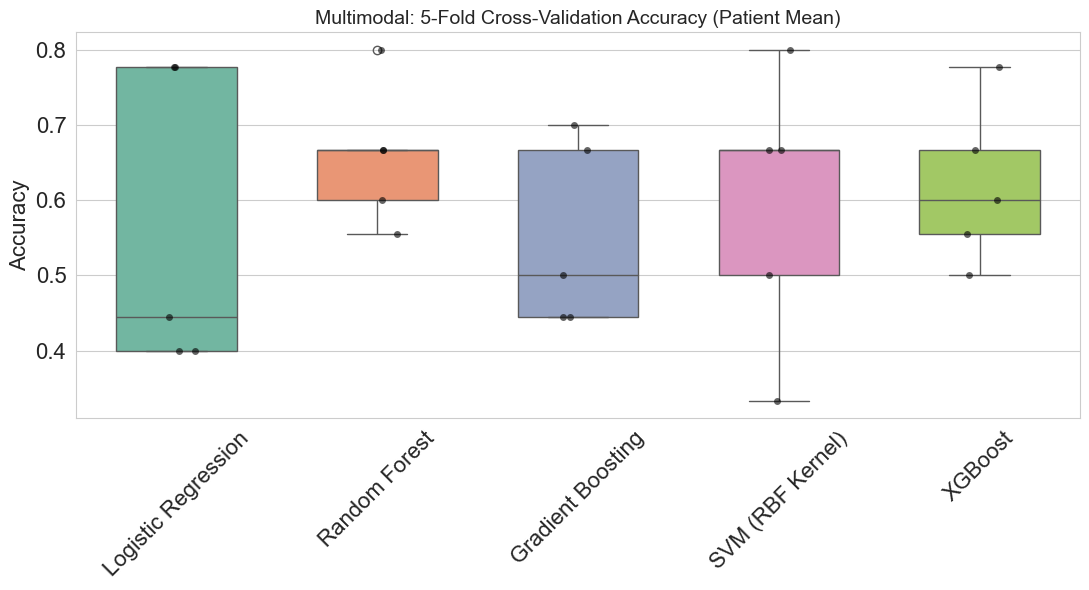

In [88]:

cv_fold_details = performance_results["Multimodal"]["Patient Mean"]["all_models"]
models = get_models()

all_folds_df = pd.concat(
    [cv_fold_details[m]["fold_metrics"].assign(model=m) for m in models.keys()],
    ignore_index=True
)

plt.figure(figsize=(11, 6))
sns.set_style("whitegrid")

sns.boxplot(
    data=all_folds_df,
    x="model",
    y="accuracy",
    palette="Set2",
    width=0.6
)

sns.stripplot(
    data=all_folds_df,
    x="model",
    y="accuracy",
    color="black",
    size=5,
    jitter=True,
    alpha=0.6
)

plt.xticks(rotation=45, fontsize=16)
plt.yticks(fontsize=16)
plt.xlabel("")
plt.ylabel("Accuracy", fontsize=16)
plt.title("Multimodal: 5-Fold Cross-Validation Accuracy (Patient Mean)", fontsize=14)

plt.tight_layout()
plt.savefig("Results/Multimodal/patient_mean/5_fold_accuracy_patient_mean.pdf", bbox_inches="tight")
plt.show()
plt.close()

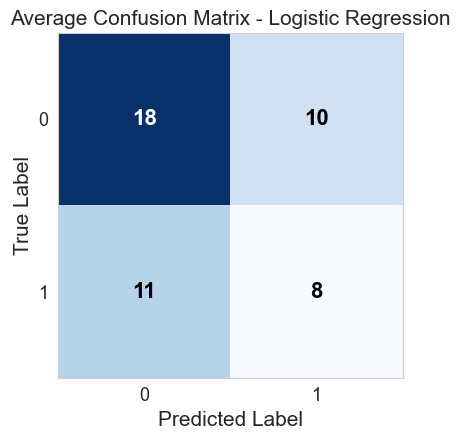

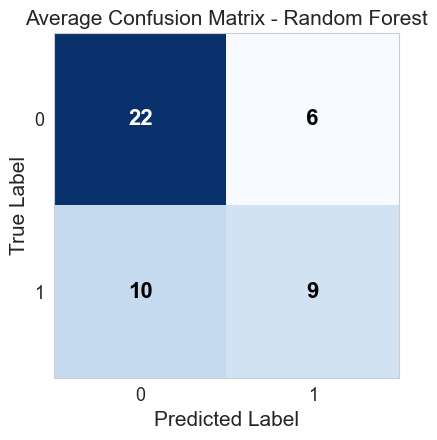

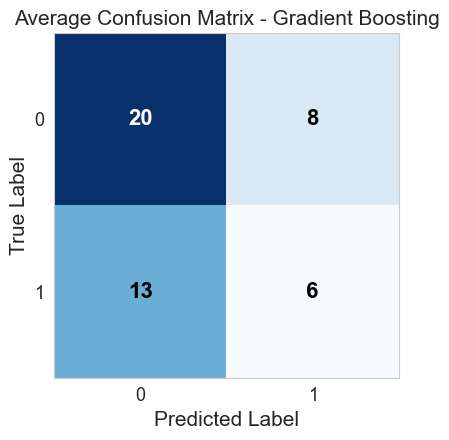

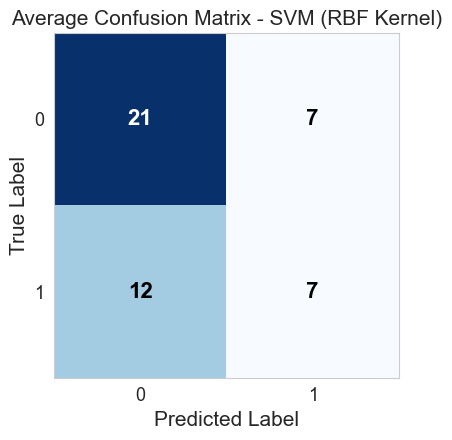

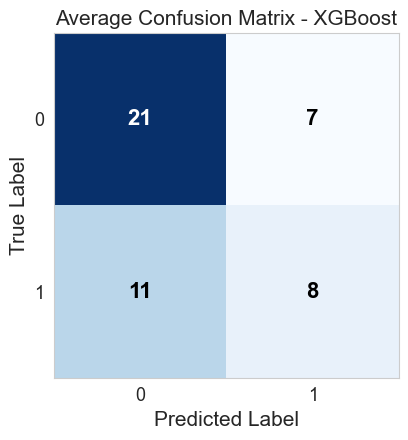

In [90]:
for model_name, details in cv_fold_details.items():
    cms = details["confusion_matrices"]
    avg_cm = np.sum(cms, axis=0)

    plt.figure(figsize=(4.5, 4.5))
    plt.imshow(avg_cm, cmap="Blues")

    plt.title(f"Average Confusion Matrix - {model_name}", fontsize=15)
    plt.xlabel("Predicted Label", fontsize=15)
    plt.ylabel("True Label", fontsize=15)

    plt.xticks([0, 1], fontsize=13)
    plt.yticks([0, 1], fontsize=13)

    for i in range(avg_cm.shape[0]):
        for j in range(avg_cm.shape[1]):
            plt.text(
                j, i, round(avg_cm[i, j], 1),
                ha="center",
                va="center",
                fontsize=16,
                fontweight="bold",
                color="white" if avg_cm[i, j] > avg_cm.max() / 1.3 else "black"
            )

    plt.tight_layout()
    plt.grid(False)

    plt.savefig(
        f"Results/Multimodal/patient_mean/confusion_matrix/Confusion_{model_name.replace(' ', '_').replace('(', '').replace(')', '')}.pdf",
        bbox_inches="tight"
    )
    plt.show()
    plt.close()



## Patient Examples

In [91]:
df_mm = combined.copy()

X_all = df_mm[feature_cols].copy()
y_all = df_mm[LABEL_COL].astype(str).copy()

le_all = LabelEncoder()
y_enc = le_all.fit_transform(y_all)

X_np = X_all.to_numpy()
y_np = np.array(y_enc)

groups = df_mm["sample"].astype(str).values

if CELTYPE_COL in df_mm.columns:
    strat_key = (df_mm[CELTYPE_COL].astype(str) + "||" + df_mm[LABEL_COL].astype(str)).values
else:
    strat_key = y_np

print("All-example feature matrix:", X_np.shape)
print("Number of samples:", len(np.unique(groups)))
print("Classes:", list(le_all.classes_))


All-example feature matrix: (360, 200)
Number of samples: 47
Classes: ['Control', 'Endometriosis']


In [92]:
cv_group = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)

cv_rows = []
cv_fold_details = {}

models = get_models()
for name, model in models.items():
    fold_rows = []
    fold_cms = []
    fold_class_counts = []
    fold_predictions = []

    print("\n" + "=" * 70)
    print("MODEL:", name)
    print("=" * 70)

    for fold, (tr, te) in enumerate(cv_group.split(X_np, strat_key, groups=groups), start=1):
        Xtr, Xte = X_np[tr], X_np[te]
        ytr, yte = y_np[tr], y_np[te]

        train_patients = pd.Series(groups[tr]).unique()
        test_patients = pd.Series(groups[te]).unique()
        overlap = set(train_patients).intersection(set(test_patients))

        print(f"\nFold {fold}")
        print("Train cells   :", len(tr))
        print("Test cells    :", len(te))
        print("Train patients:", len(train_patients))
        print("Test patients :", len(test_patients))
        print("Patient overlap:", len(overlap))

        print("Train class counts:")
        print(pd.Series(ytr).value_counts().sort_index())

        print("Test class counts:")
        print(pd.Series(yte).value_counts().sort_index())

        scaler = StandardScaler()
        Xtr = scaler.fit_transform(Xtr)
        Xte = scaler.transform(Xte)

        model.fit(Xtr, ytr)
        pred = model.predict(Xte)

        fold_rows.append({
            "fold": fold,
            "accuracy": float(accuracy_score(yte, pred)),
            "precision": float(precision_score(yte, pred, zero_division=0)),
            "recall": float(recall_score(yte, pred, zero_division=0)),
            "f1_score": float(f1_score(yte, pred, zero_division=0)),
        })

        fold_cms.append(confusion_matrix(yte, pred))

        fold_class_counts.append({
            "fold": fold,
            "train_class_0": int(np.sum(ytr == 0)),
            "train_class_1": int(np.sum(ytr == 1)),
            "test_class_0": int(np.sum(yte == 0)),
            "test_class_1": int(np.sum(yte == 1)),
        })

        fold_predictions.append(
            pd.DataFrame({
                "fold": fold,
                "patient_id": groups[te],
                "y_true": yte,
                "y_pred": pred
            })
        )

    df_folds = pd.DataFrame(fold_rows)

    cv_fold_details[name] = {
        "fold_metrics": df_folds,
        "confusion_matrices": fold_cms,
        "class_counts": pd.DataFrame(fold_class_counts),
        "predictions": pd.concat(fold_predictions, ignore_index=True)
    }

    cv_rows.append({
        "model": name,
        "acc_mean": df_folds["accuracy"].mean(),
        "acc_std": df_folds["accuracy"].std(ddof=0),
        "prec_mean": df_folds["precision"].mean(),
        "prec_std": df_folds["precision"].std(ddof=0),
        "rec_mean": df_folds["recall"].mean(),
        "rec_std": df_folds["recall"].std(ddof=0),
        "f1_mean": df_folds["f1_score"].mean(),
        "f1_std": df_folds["f1_score"].std(ddof=0),
    })

results_df = pd.DataFrame(cv_rows).sort_values(
    ["acc_mean", "f1_mean", "prec_mean", "rec_mean"],
    ascending=False
).reset_index(drop=True)

print("\n===== MULTIMODAL 5-FOLD CV RESULTS (PATIENT-WISE SPLIT) =====\n")
print(results_df.to_string(index=False))

print("\n===== FOLD-WISE RESULTS (ALL MODELS) =====\n")
for model_name in models.keys():
    print(f"\n----- {model_name} -----\n")
    print(cv_fold_details[model_name]["fold_metrics"].to_string(index=False))

print("\n===== FOLD-WISE CLASS COUNTS (ALL MODELS) =====\n")
for model_name in models.keys():
    print(f"\n----- {model_name} -----\n")
    print(cv_fold_details[model_name]["class_counts"].to_string(index=False))

best_model_name = results_df.iloc[0]["model"]
best_acc = results_df.iloc[0]["acc_mean"]

print("\n===== BEST MODEL =====\n")
print("Best model:", best_model_name)
print(f"Best model accuracy (5-fold mean): {best_acc:.3f}")

print("\nBest model fold-wise metrics:\n")
print(cv_fold_details[best_model_name]["fold_metrics"].to_string(index=False))

print("\nBest model fold-wise class counts:\n")
print(cv_fold_details[best_model_name]["class_counts"].to_string(index=False))

scaler_split = StandardScaler()
X_fit_split = scaler_split.fit_transform(X_np)

best_model = models[best_model_name]
best_model.fit(X_fit_split, y_np)




MODEL: Logistic Regression

Fold 1
Train cells   : 324
Test cells    : 36
Train patients: 39
Test patients : 8
Patient overlap: 0
Train class counts:
0    166
1    158
Name: count, dtype: int64
Test class counts:
0    14
1    22
Name: count, dtype: int64

Fold 2
Train cells   : 255
Test cells    : 105
Train patients: 35
Test patients : 12
Patient overlap: 0
Train class counts:
0    127
1    128
Name: count, dtype: int64
Test class counts:
0    53
1    52
Name: count, dtype: int64

Fold 3
Train cells   : 296
Test cells    : 64
Train patients: 37
Test patients : 10
Patient overlap: 0
Train class counts:
0    158
1    138
Name: count, dtype: int64
Test class counts:
0    22
1    42
Name: count, dtype: int64

Fold 4
Train cells   : 327
Test cells    : 33
Train patients: 39
Test patients : 8
Patient overlap: 0
Train class counts:
0    151
1    176
Name: count, dtype: int64
Test class counts:
0    29
1     4
Name: count, dtype: int64

Fold 5
Train cells   : 238
Test cells    : 122
Train pat

,C,1.0
,kernel,'rbf'
,degree,3
,gamma,'scale'
,coef0,0.0
,shrinking,True
,probability,True
,tol,0.001
,cache_size,200
,class_weight,None
,verbose,False


In [93]:
if "performance_results" not in globals():
    performance_results = {}

if "Multimodal" not in performance_results:
    performance_results["Multimodal"] = {}

performance_results["Multimodal"]["Patient-Wise Split"] = {
    "summary_table": results_df,
    "all_models": cv_fold_details,
    "best": {
        "best_model_name": best_model_name,
        "best_model": best_model,
        "cv_mean_std": results_df[results_df["model"] == best_model_name].iloc[0].to_dict(),
        "cv_fold_metrics": cv_fold_details[best_model_name]["fold_metrics"],
        "cv_confusion_matrices": cv_fold_details[best_model_name]["confusion_matrices"],
        "class_counts": cv_fold_details[best_model_name]["class_counts"],
        "predictions": cv_fold_details[best_model_name]["predictions"],
    },
    "shap_ready": {
        "best_model": best_model,
        "best_model_name": best_model_name,
        "best_model_metrics": {
            "cv_f1_mean": float(results_df.iloc[0]["f1_mean"]),
            "cv_f1_std": float(results_df.iloc[0]["f1_std"]),
            "cv_accuracy_mean": float(results_df.iloc[0]["acc_mean"]),
            "cv_accuracy_std": float(results_df.iloc[0]["acc_std"]),
            "cv_precision_mean": float(results_df.iloc[0]["prec_mean"]),
            "cv_precision_std": float(results_df.iloc[0]["prec_std"]),
            "cv_recall_mean": float(results_df.iloc[0]["rec_mean"]),
            "cv_recall_std": float(results_df.iloc[0]["rec_std"]),
        },
        "feature_names": list(X_all.columns),
        "X_eval": X_np,
        "y_eval": y_np,
        "patient_ids": groups,
    }
}

print("\nStored keys:")
print(performance_results["Multimodal"]["Patient-Wise Split"].keys())
print(performance_results["Multimodal"]["Patient-Wise Split"]["best"].keys())
print(performance_results["Multimodal"]["Patient-Wise Split"]["shap_ready"].keys())


Stored keys:
dict_keys(['summary_table', 'all_models', 'best', 'shap_ready'])
dict_keys(['best_model_name', 'best_model', 'cv_mean_std', 'cv_fold_metrics', 'cv_confusion_matrices', 'class_counts', 'predictions'])
dict_keys(['best_model', 'best_model_name', 'best_model_metrics', 'feature_names', 'X_eval', 'y_eval', 'patient_ids'])


/var/folders/3m/0mzmnr390d7_tzpq513jtf8h0000gn/T/ipykernel_1592/136858396.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


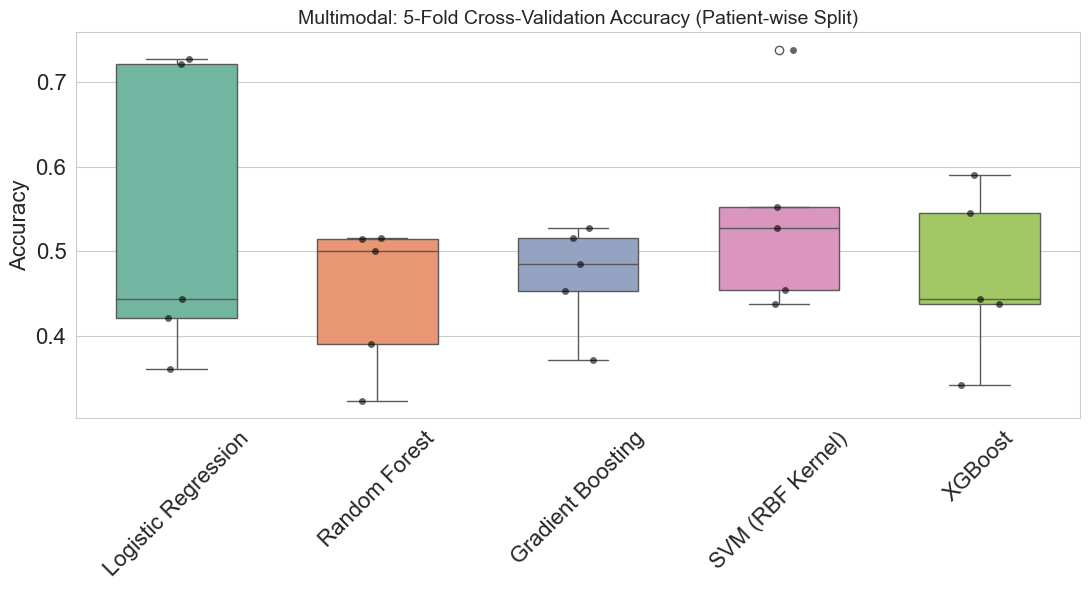

In [94]:


cv_fold_details = performance_results["Multimodal"]["Patient-Wise Split"]["all_models"]
models = get_models()

all_folds_df = pd.concat(
    [cv_fold_details[m]["fold_metrics"].assign(model=m) for m in models.keys()],
    ignore_index=True
)

plt.figure(figsize=(11, 6))
sns.set_style("whitegrid")

sns.boxplot(
    data=all_folds_df,
    x="model",
    y="accuracy",
    palette="Set2",
    width=0.6
)

sns.stripplot(
    data=all_folds_df,
    x="model",
    y="accuracy",
    color="black",
    size=5,
    jitter=True,
    alpha=0.6
)

plt.xticks(rotation=45, fontsize=16)
plt.yticks(fontsize=16)
plt.xlabel("")
plt.ylabel("Accuracy", fontsize=16)
plt.title("Multimodal: 5-Fold Cross-Validation Accuracy (Patient-wise Split)", fontsize=14)

plt.tight_layout()
plt.savefig("Results/Multimodal/patient_examples/5_fold_accuracy_patient_wise_split.pdf", bbox_inches="tight")
plt.show()
plt.close()

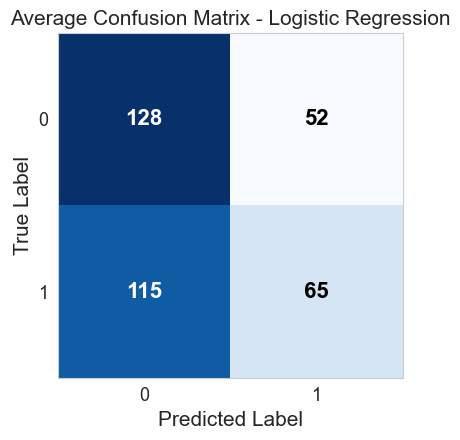

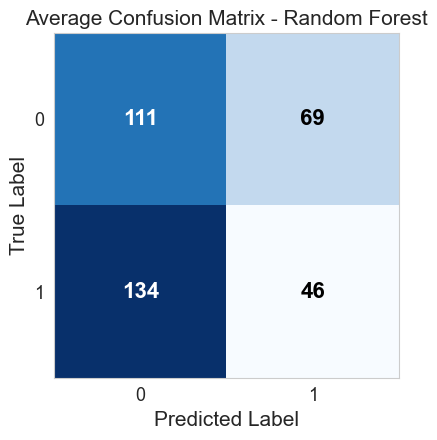

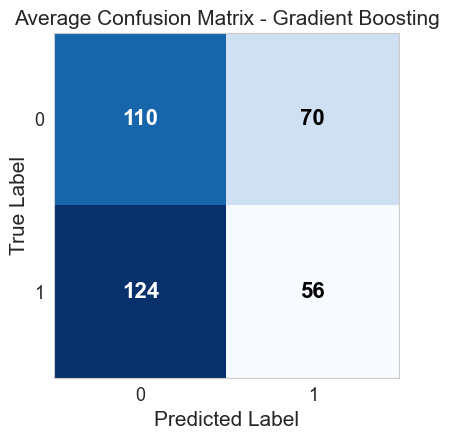

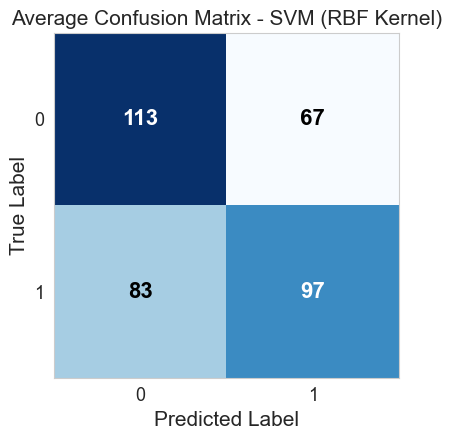

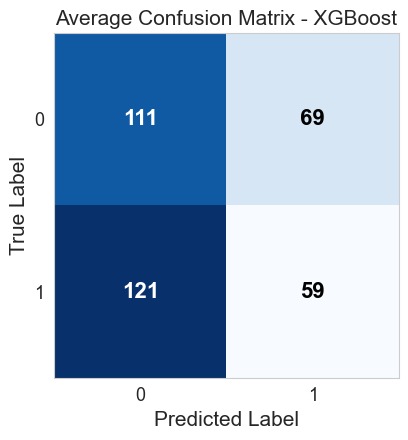

Patient-wise split plots saved in Experiment_3/Patient_wise_split


In [95]:
for model_name, details in cv_fold_details.items():
    cms = details["confusion_matrices"]
    avg_cm = np.sum(cms, axis=0)

    plt.figure(figsize=(4.5, 4.5))
    plt.imshow(avg_cm, cmap="Blues")

    plt.title(f"Average Confusion Matrix - {model_name}", fontsize=15)
    plt.xlabel("Predicted Label", fontsize=15)
    plt.ylabel("True Label", fontsize=15)

    plt.xticks([0, 1], fontsize=13)
    plt.yticks([0, 1], fontsize=13)

    for i in range(avg_cm.shape[0]):
        for j in range(avg_cm.shape[1]):
            plt.text(
                j, i, round(avg_cm[i, j], 1),
                ha="center",
                va="center",
                fontsize=16,
                fontweight="bold",
                color="white" if avg_cm[i, j] > avg_cm.max() / 1.3 else "black"
            )

    plt.tight_layout()
    plt.grid(False)

    plt.savefig(
        f"Results/Multimodal/patient_examples/confusion_matrix/Confusion_{model_name.replace(' ', '_').replace('(', '').replace(')', '')}.jpg",
        bbox_inches="tight"
    )
    plt.show()
    plt.close()

print("Patient-wise split plots saved in Experiment_3/Patient_wise_split")

# Combined performance summary:

In [96]:
for exp_name, exp_data in performance_results.items():
    if isinstance(exp_data, dict) and "Patient Mean" in exp_data and "all_models" in exp_data["Patient Mean"]:
        print(f"\n{exp_name}")
        for model_name, model_details in exp_data["Patient Mean"]["all_models"].items():
            print(model_name, "->", model_details.keys())


Transcriptomics
Logistic Regression -> dict_keys(['cv_fold_metrics', 'cv_confusion_matrices', 'oof_predictions'])
Random Forest -> dict_keys(['cv_fold_metrics', 'cv_confusion_matrices', 'oof_predictions'])
Gradient Boosting -> dict_keys(['cv_fold_metrics', 'cv_confusion_matrices', 'oof_predictions'])
SVM (RBF Kernel) -> dict_keys(['cv_fold_metrics', 'cv_confusion_matrices', 'oof_predictions'])
XGBoost -> dict_keys(['cv_fold_metrics', 'cv_confusion_matrices', 'oof_predictions'])

Fluxomics
Logistic Regression -> dict_keys(['fold_metrics', 'confusion_matrices', 'class_counts', 'predictions'])
Random Forest -> dict_keys(['fold_metrics', 'confusion_matrices', 'class_counts', 'predictions'])
Gradient Boosting -> dict_keys(['fold_metrics', 'confusion_matrices', 'class_counts', 'predictions'])
SVM (RBF Kernel) -> dict_keys(['fold_metrics', 'confusion_matrices', 'class_counts', 'predictions'])
XGBoost -> dict_keys(['fold_metrics', 'confusion_matrices', 'class_counts', 'predictions'])

Multimo

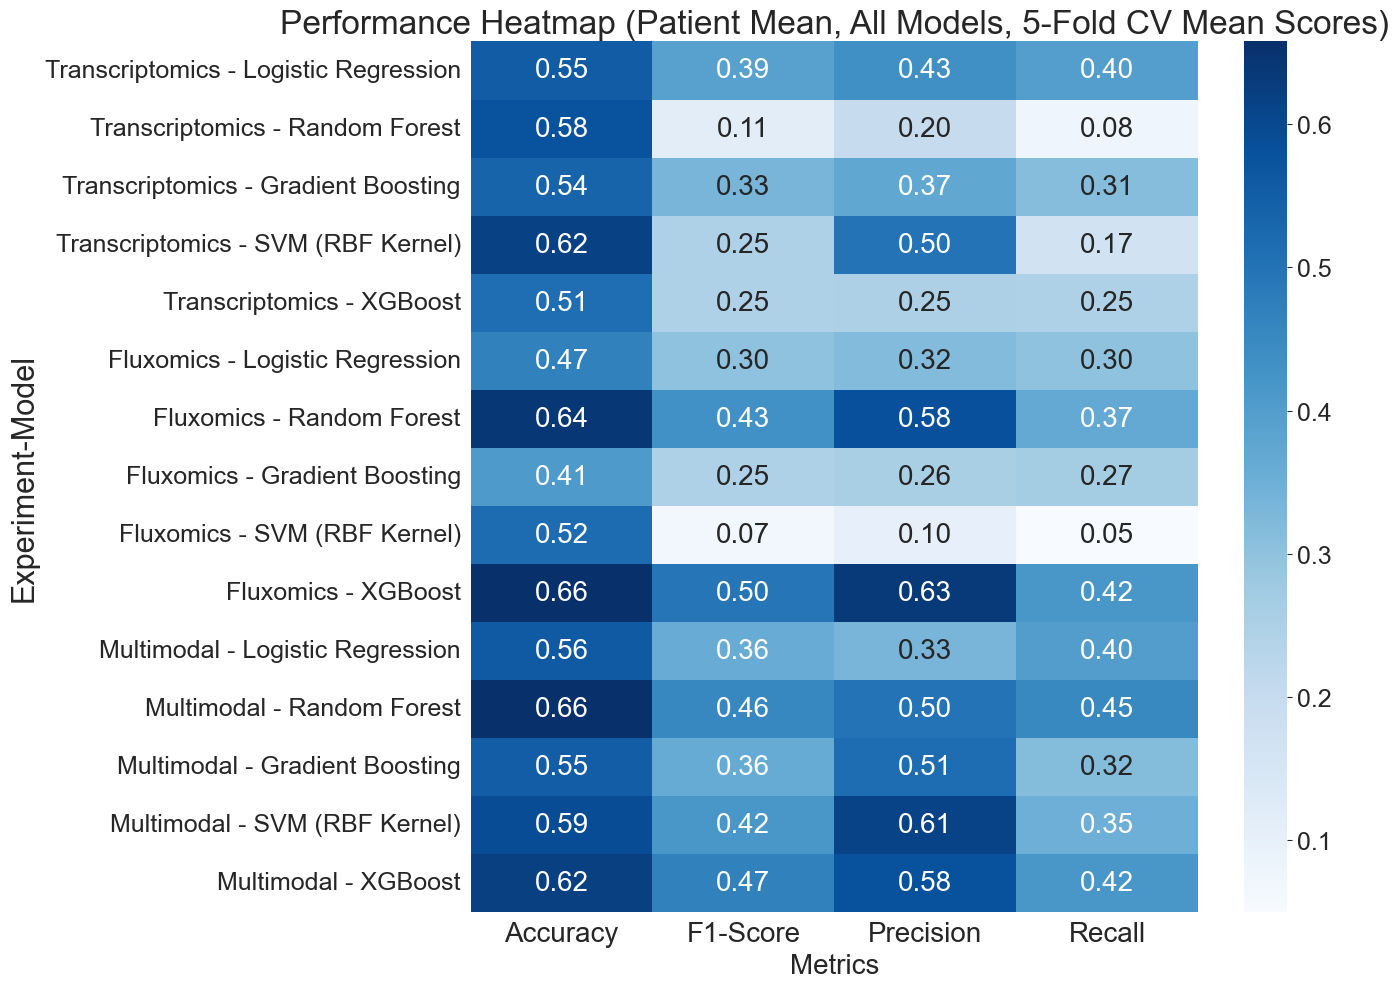

In [97]:
rows = []

for exp_name, exp_data in performance_results.items():

    if not isinstance(exp_data, dict) or "Patient Mean" not in exp_data:
        continue

    patient_mean_block = exp_data["Patient Mean"]

    if "all_models" not in patient_mean_block:
        continue

    for model_name, model_details in patient_mean_block["all_models"].items():

        if "fold_metrics" in model_details:
            fold_df = model_details["fold_metrics"]
        elif "cv_fold_metrics" in model_details:
            fold_df = model_details["cv_fold_metrics"]
        else:
            print(f"Skipped: {exp_name} - {model_name} (no fold metrics key found)")
            continue

        rows.append([
            f"{exp_name} - {model_name}",
            fold_df["accuracy"].mean(),
            fold_df["f1_score"].mean(),
            fold_df["precision"].mean(),
            fold_df["recall"].mean(),
        ])

# Create DataFrame
heatmap_df = pd.DataFrame(
    rows,
    columns=["Experiment-Model", "Accuracy", "F1-Score", "Precision", "Recall"]
).set_index("Experiment-Model")

# Plot heatmap
plt.figure(figsize=(14, 10))

ax = sns.heatmap(
    heatmap_df,
    annot=True,
    cmap="Blues",
    fmt=".2f",
    annot_kws={"size": 20},
    cbar_kws={"shrink": 1.0}
)

# Colorbar tick size
cbar = ax.collections[0].colorbar
cbar.ax.tick_params(labelsize=18)

# Increase title size
plt.title(
    "Performance Heatmap (Patient Mean, All Models, 5-Fold CV Mean Scores)",
    fontsize=24
)

# Increase axis label sizes
plt.xlabel("Metrics", fontsize=20)
plt.ylabel("Experiment-Model", fontsize=22)

# Increase tick label sizes
plt.xticks(fontsize=20)
plt.yticks(fontsize=18)

plt.tight_layout()
plt.grid(False)

# Save and show
plt.savefig(
    "Results/performance_heatmap_patient_mean_all_models_cv_mean.pdf",
    bbox_inches="tight"
)
plt.show()

# Combined Shap Analysis

In [102]:

# Combined SHAP Analysis - Patient Mean


if "shap_ready" not in globals():
    shap_ready = {}

_modality = "Multimodal"
_setting = "Patient Mean"

best_block = performance_results[_modality][_setting]["best"]

best_model_name_combined = best_block["best_model_name"]
best_model_combined = best_block["best_model"]

feature_names_combined = performance_results[_modality][_setting]["shap_ready"]["feature_names"]
X_eval_combined = performance_results[_modality][_setting]["shap_ready"]["X_eval"]
y_eval_combined = performance_results[_modality][_setting]["shap_ready"]["y_eval"]
patient_ids_combined = performance_results[_modality][_setting]["shap_ready"]["patient_ids"]

shap_explainer_type_combined = _explainer_type(best_model_name_combined)

# scale full evaluation data and refit best model
scaler = StandardScaler()
X_scaled_full = scaler.fit_transform(X_eval_combined)

best_model_combined.fit(X_scaled_full, y_eval_combined)

X_eval_combined_df = pd.DataFrame(
    X_scaled_full,
    columns=feature_names_combined,
    index=patient_ids_combined
)

background_combined = None
if shap_explainer_type_combined == "kernel":
    background_combined = X_eval_combined_df.sample(
        min(200, len(X_eval_combined_df)),
        random_state=SEED
    )

cv_best = best_block["cv_mean_std"]

shap_ready[f"{_modality} - {_setting}"] = {
    "best_model": best_model_combined,
    "best_model_name": best_model_name_combined,
    "best_model_metrics": {
        "cv_accuracy_mean": float(cv_best["acc_mean"]),
        "cv_f1_mean": float(cv_best["f1_mean"]),
        "cv_precision_mean": float(cv_best["prec_mean"]),
        "cv_recall_mean": float(cv_best["rec_mean"]),
    },
    "feature_names": feature_names_combined,
    "explainer_type": shap_explainer_type_combined,
    "X_eval": X_eval_combined_df,
    "y_eval": y_eval_combined.copy(),
    "background": background_combined,
    "patient_ids": patient_ids_combined,
}

print("Best combined model:", best_model_name_combined)
print("Stored SHAP-ready keys:", list(shap_ready[f'{_modality} - {_setting}'].keys()))

Best combined model: Random Forest
Stored SHAP-ready keys: ['best_model', 'best_model_name', 'best_model_metrics', 'feature_names', 'explainer_type', 'X_eval', 'y_eval', 'background', 'patient_ids']


In [103]:
# features actually used in the trained patient-mean multimodal model
feature_cols_combined = performance_results["Multimodal"]["Patient Mean"]["shap_ready"]["feature_names"]

# fluxomics top features that are present in the trained feature set
flux_feature_names_combined = [
    f for f in top100_fluxomics_pm["feature"]
    if f in feature_cols_combined
]

# transcriptomics top features that are present in the trained feature set
tx_feature_names_combined = [
    g for g in top100_transcriptomics_pm["feature"]
    if g in feature_cols_combined
]

# feature -> modality mapping
feature_modality_map = pd.DataFrame({
    "feature": flux_feature_names_combined + tx_feature_names_combined,
    "modality": (["Fluxomics"] * len(flux_feature_names_combined)) +
                (["Transcriptomics"] * len(tx_feature_names_combined))
})

print("Total trained multimodal patient-mean features:", len(feature_cols_combined))
print("Fluxomics features in model:", len(flux_feature_names_combined))
print("Transcriptomics features in model:", len(tx_feature_names_combined))

Total trained multimodal patient-mean features: 200
Fluxomics features in model: 100
Transcriptomics features in model: 100


In [104]:
def _to_df(X, feature_names, index=None):
    if isinstance(X, pd.DataFrame):
        return X.copy()
    X = np.array(X)
    return pd.DataFrame(X, columns=feature_names, index=index)


# Build SHAP explainer from shap_ready entry
def _make_explainer_from_entry(entry):
    model = entry["best_model"]
    expl_type = entry["explainer_type"]   # "tree" | "linear" | "kernel"
    feature_names = list(entry["feature_names"])

    X_bg_raw = entry["background"] if entry["background"] is not None else entry["X_eval"]
    X_bg = _to_df(X_bg_raw, feature_names)

    if expl_type == "tree":
        return shap.TreeExplainer(model, X_bg)

    if expl_type == "linear":
        return shap.LinearExplainer(model, X_bg)

    # kernel SHAP
    def f(X):
        Xdf = _to_df(X, feature_names)
        if hasattr(model, "predict_proba"):
            return model.predict_proba(Xdf)[:, 1]
        elif hasattr(model, "decision_function"):
            return model.decision_function(Xdf)
        else:
            return model.predict(Xdf)

    K = min(50, len(X_bg))
    bg_summary = shap.kmeans(X_bg, K)
    return shap.KernelExplainer(f, bg_summary)


# Run SHAP for one stored entry from shap_ready
def run_shap_for_best(modality_key, max_samples=500, top_k=20, make_plots=False):
    entry = shap_ready[modality_key]

    model_name = entry["best_model_name"]
    feature_names = list(entry["feature_names"])
    patient_ids = entry.get("patient_ids", None)

    X_eval = _to_df(entry["X_eval"], feature_names, index=patient_ids)

    # subsample for speed
    if len(X_eval) > max_samples:
        X_sample = X_eval.sample(max_samples, random_state=SEED)
    else:
        X_sample = X_eval.copy()

    explainer = _make_explainer_from_entry(entry)
    shap_values = explainer.shap_values(X_sample)

    # SHAP output can be list or array
    if isinstance(shap_values, list):
        shap_arr = np.array(shap_values[1] if len(shap_values) > 1 else shap_values[0])
    else:
        shap_arr = np.array(shap_values)

    # if shape is (n_samples, n_features, n_outputs), reduce outputs
    if shap_arr.ndim == 3:
        shap_arr = shap_arr.mean(axis=2)

    mean_abs_shap = np.mean(np.abs(shap_arr), axis=0).reshape(-1)

    k = min(top_k, len(feature_names))
    top_idx = np.argsort(mean_abs_shap)[::-1][:k].astype(int)

    top_features = pd.DataFrame({
        "feature": [feature_names[i] for i in top_idx],
        "mean_abs_shap": mean_abs_shap[top_idx],
    })

    # map modality
    if modality_key == "Fluxomics":
        top_features["modality"] = "Fluxomics"

    elif modality_key == "Transcriptomics":
        top_features["modality"] = "Transcriptomics"

    elif modality_key == "Multimodal - Patient Mean":
        top_features = top_features.merge(
            feature_modality_map,
            on="feature",
            how="left"
        )
        top_features["modality"] = top_features["modality"].fillna("Unknown")

    else:
        top_features["modality"] = modality_key

    print(f"\n===== SHAP analysis for: {modality_key} =====")
    print(f"Best model: {model_name}")
    print(f"Top {k} features by mean |SHAP|:\n")
    print(top_features.to_string(index=False))

    if make_plots:
        shap.summary_plot(shap_arr, X_sample, feature_names=feature_names)
        shap.summary_plot(shap_arr, X_sample, feature_names=feature_names, plot_type="bar")

    return top_features, shap_arr, X_sample

top_combined, shap_combined, X_combined_sample = run_shap_for_best(
    "Multimodal - Patient Mean",
    max_samples=500,
    top_k=30,
    make_plots=False
)


===== SHAP analysis for: Multimodal - Patient Mean =====
Best model: Random Forest
Top 30 features by mean |SHAP|:

                   feature  mean_abs_shap        modality
                       PGI   5.848104e-11       Fluxomics
                       TPI   2.931134e-11       Fluxomics
                     ABUTD   2.696946e-11       Fluxomics
                   asp_L_t   2.577711e-11       Fluxomics
                   PTRCOX1   2.410058e-11       Fluxomics
                  AKGMALtm   2.262826e-11       Fluxomics
                      ATF5   1.975609e-11 Transcriptomics
                     ACITL   1.958481e-11       Fluxomics
                  HMGCOASm   1.953540e-11       Fluxomics
                     FOLR2   1.901169e-11       Fluxomics
                     CO2tm   1.896558e-11       Fluxomics
                      PGCD   1.831012e-11       Fluxomics
                     PSERT   1.781276e-11       Fluxomics
                     PSP_L   1.768759e-11       Fluxomics
             

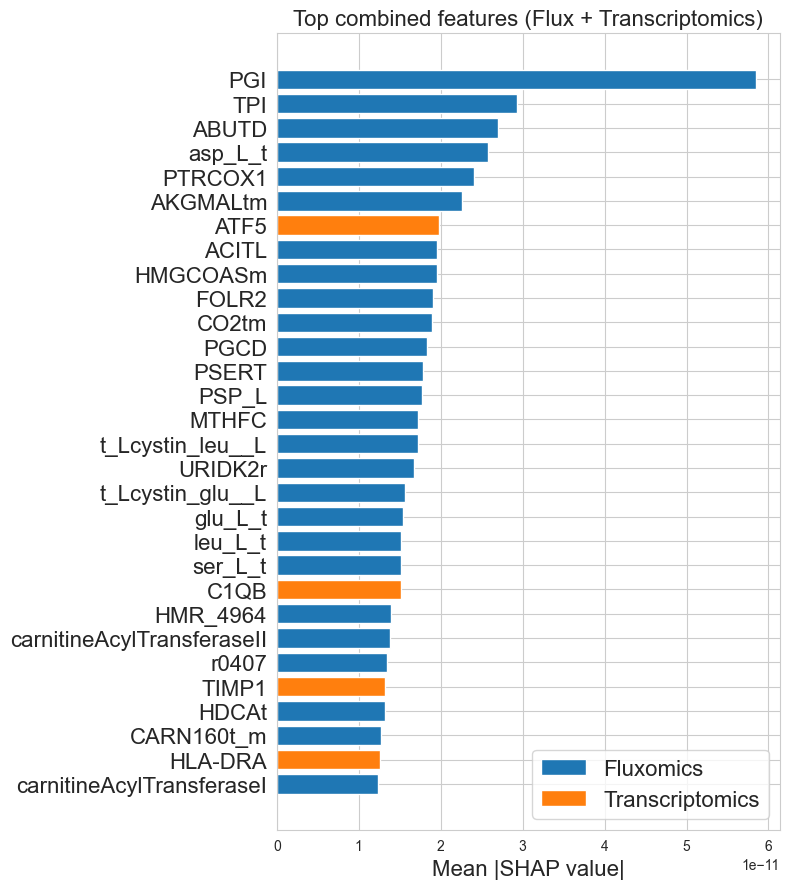

In [105]:
df = top_combined.copy().sort_values("mean_abs_shap", ascending=True)
title = "Top combined features (Flux + Transcriptomics)"
y_pos = np.arange(len(df))

flux_mask = df["modality"] == "Fluxomics"
tx_mask   = df["modality"] == "Transcriptomics"

plt.figure(figsize=(8, max(4, len(df) * 0.3)))

plt.barh(y_pos[flux_mask], df.loc[flux_mask, "mean_abs_shap"],
         align="center", label="Fluxomics")
plt.barh(y_pos[tx_mask], df.loc[tx_mask, "mean_abs_shap"],
         align="center", label="Transcriptomics")

plt.yticks(y_pos, df["feature"], fontsize=16)
plt.xlabel("Mean |SHAP value|", fontsize=16)
plt.title(title, fontsize=16)
plt.legend(fontsize=16)

plt.tight_layout()
plt.savefig("Results/SHAP/combined_shap_top_features.pdf", bbox_inches="tight")
plt.show()

In [106]:
top_combined.to_csv("Results/SHAP/top_combined_features.csv", index=False)

print("Saved")

Saved


Total contribution per modality (sum of mean |SHAP|):
modality
Fluxomics          9.756272e-10
Transcriptomics    3.880401e-10
Name: mean_abs_shap, dtype: float64

Percentage contribution per modality:
modality
Fluxomics          71.544372
Transcriptomics    28.455628
Name: mean_abs_shap, dtype: float64


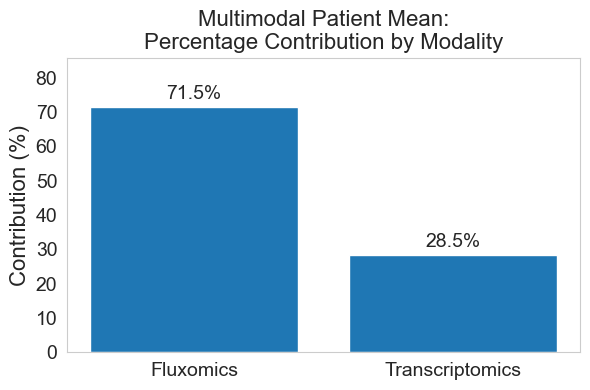

In [107]:

# Get SHAP values for Multimodal Patient Mean

entry_combined = shap_ready["Multimodal - Patient Mean"]

# feature names in the same order as SHAP columns
feature_names_combined = list(entry_combined["feature_names"])

# shap_combined should already come from:
# top_combined, shap_combined, X_combined_sample = run_shap_for_best("Multimodal - Patient Mean", ...)
shap_arr = np.array(shap_combined)

# if shape is (n_samples, n_features, n_outputs), average over outputs
if shap_arr.ndim == 3:
    shap_arr = shap_arr.mean(axis=2)

# global importance per feature = mean |SHAP| over samples
mean_abs_shap = np.mean(np.abs(shap_arr), axis=0).reshape(-1)

feature_importance = pd.DataFrame({
    "feature": feature_names_combined,
    "mean_abs_shap": mean_abs_shap,
})



# Attach modality (Fluxomics / Transcriptomics)


fi_with_mod = feature_importance.merge(
    feature_modality_map,
    on="feature",
    how="left"
)

# remove unmatched rows if any
fi_with_mod = fi_with_mod.dropna(subset=["modality"]).copy()



#  Aggregate and compute %


modality_contrib = fi_with_mod.groupby("modality")["mean_abs_shap"].sum().sort_values(ascending=False)

total_contrib = modality_contrib.sum()
modality_pct = 100.0 * modality_contrib / total_contrib

print("Total contribution per modality (sum of mean |SHAP|):")
print(modality_contrib)

print("\nPercentage contribution per modality:")
print(modality_pct)




# Plot % contribution by modality


plt.figure(figsize=(6, 4))

x = np.arange(len(modality_pct.index))
plt.bar(x, modality_pct.values)

plt.xticks(x, modality_pct.index, fontsize=14)
plt.yticks(fontsize=14)
plt.ylabel("Contribution (%)", fontsize=16)
plt.title("Multimodal Patient Mean:\nPercentage Contribution by Modality", fontsize=16)

for i, val in enumerate(modality_pct.values):
    plt.text(i, val + 1, f"{val:.1f}%", ha="center", va="bottom", fontsize=14)

plt.ylim(0, max(modality_pct.values) * 1.2)
plt.grid(False)
plt.tight_layout()
plt.savefig("Results/contribution_modality_multimodal_patient_mean.pdf", bbox_inches="tight")
plt.show()

# KEGG gene enrichment pathway analysis

In [108]:
os.makedirs("Results/pathway_analysis", exist_ok=True)

2026-04-30 13:23:01,489 [INFO] Run: KEGG_2021_Human
2026-04-30 13:23:03,332 [INFO] Save enrichment results for KEGG_2021_Human
2026-04-30 13:23:03,334 [INFO] Done.


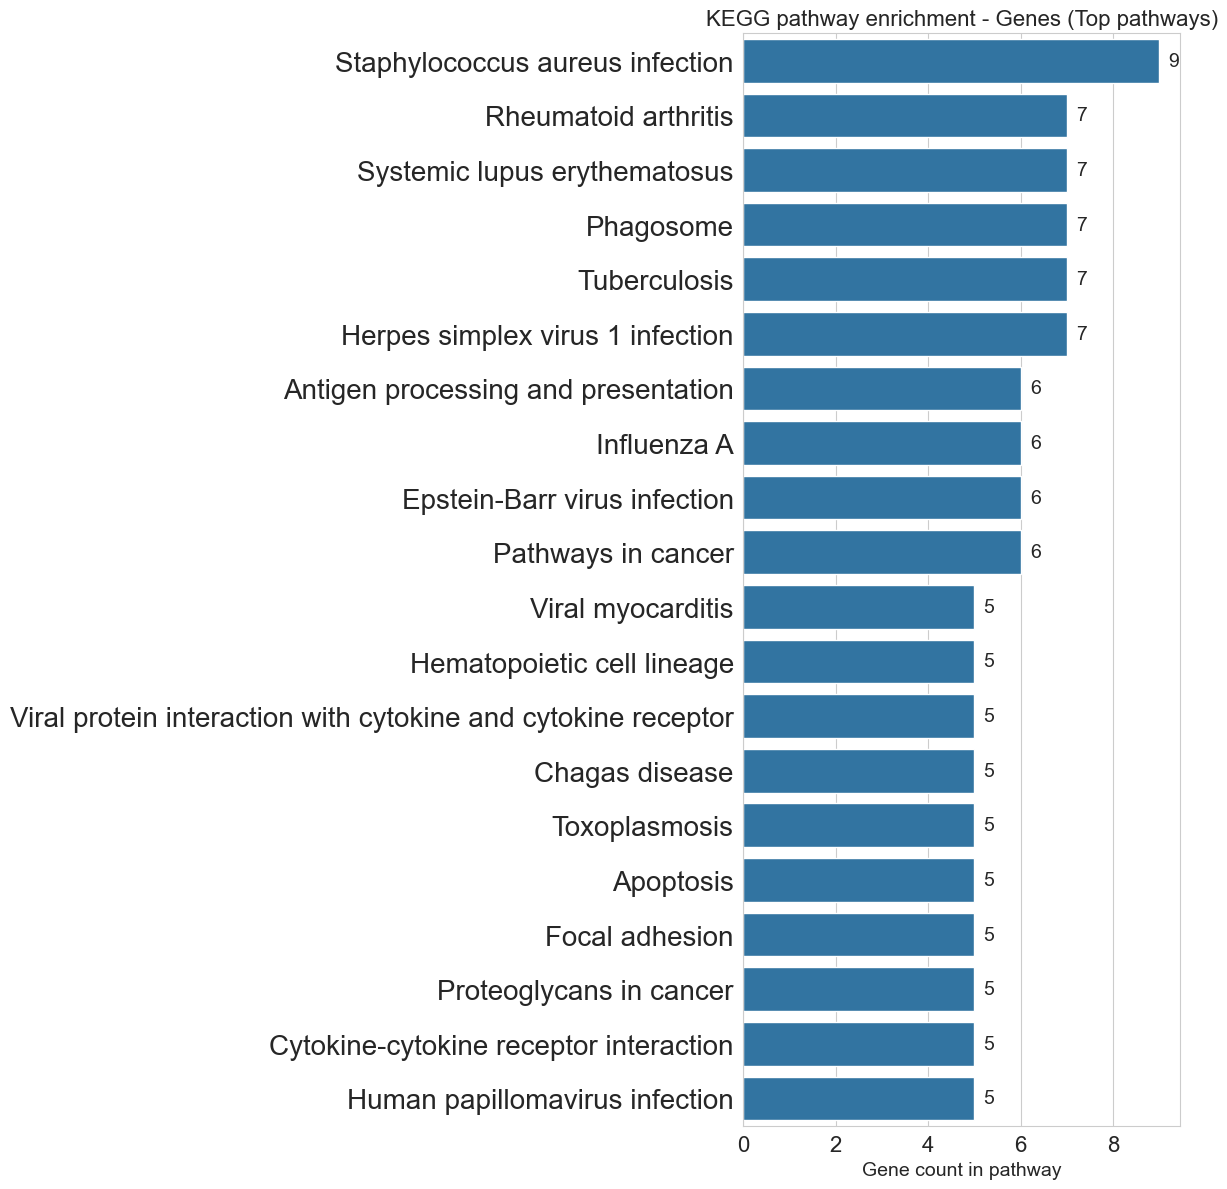

In [109]:
import gseapy as gp
gene_list = top100_transcriptomics["feature"].dropna().astype(str).str.strip().unique().tolist()

enr = gp.enrichr(
    gene_list=gene_list,
    gene_sets=["KEGG_2021_Human"],
    organism="Human",
    outdir="kegg_gene_enrichment",
    cutoff=1.0,
    no_plot=True,
    verbose=True
)

kegg = enr.results.copy()
kegg.to_csv("kegg_gene_enrichment/KEGG_2021_Human_results.csv", index=False)

kegg["gene_count"] = kegg["Overlap"].astype(str).str.split("/").str[0].astype(int)
kegg["Term_clean"] = kegg["Term"].astype(str).str.replace(" - Homo sapiens \\(human\\)", "", regex=True)

topn = 20
plot_df = kegg.sort_values(["gene_count", "Adjusted P-value"], ascending=[False, True]).head(topn)

plt.figure(figsize=(12, max(6, 0.6 * len(plot_df))))
ax = sns.barplot(data=plot_df, x="gene_count", y="Term_clean")

ax.set_xlabel("Gene count in pathway", fontsize=14)
ax.set_ylabel("", fontsize=16)
ax.set_title("KEGG pathway enrichment - Genes (Top pathways)", fontsize=16)

ax.tick_params(axis='y', labelsize=20)
ax.tick_params(axis='x', labelsize=16)

for i, row in plot_df.reset_index(drop=True).iterrows():
    ax.text(row["gene_count"] + 0.2, i, str(row["gene_count"]), va="center", fontsize=14)

plt.tight_layout()
plt.savefig("Results/pathway_analysis/KEGG_gene_count_barplot.pdf", dpi=300)
plt.show()



# Reaction-level Flux Changes (log₂ Fold-Change)

In [110]:
os.makedirs("Results/Flux_log2_Fold_change", exist_ok=True)

In [116]:
import time, requests


from scipy.stats import mannwhitneyu
from statsmodels.stats.multitest import multipletests


REACTIONS_TSV_URL = "https://raw.githubusercontent.com/SysBioChalmers/Human-GEM/main/model/reactions.tsv"

In [112]:
LABEL_COL = "Endometriosis"
CASE_NAME = "Endometriosis"
CTRL_NAME = "Control"
CELLTYPE_COL = "celltype"
EPS = 1e-12
LOG2FC_THR = 0.25
FDR_CUTOFF = 0.0

In [113]:
df = flux_df.copy()

meta_cols = {LABEL_COL, CELLTYPE_COL}
meta_cols = [c for c in meta_cols if c in df.columns]
reaction_cols = [c for c in df.columns if c not in meta_cols]

X = df[reaction_cols].apply(pd.to_numeric, errors="coerce")

mask_case = df[LABEL_COL].astype(str).str.strip().eq(CASE_NAME)
mask_ctrl = df[LABEL_COL].astype(str).str.strip().eq(CTRL_NAME)

X_case = X.loc[mask_case]
X_ctrl = X.loc[mask_ctrl]

case_mean = X_case.mean(axis=0, skipna=True)
ctrl_mean = X_ctrl.mean(axis=0, skipna=True)
delta_mean = case_mean - ctrl_mean

case_abs = X_case.abs().mean(axis=0, skipna=True)
ctrl_abs = X_ctrl.abs().mean(axis=0, skipna=True)
log2fc_mag = np.log2((case_abs + EPS) / (ctrl_abs + EPS))

sign = np.sign(delta_mean.replace(0, np.nan)).fillna(0)
log2fc_signed = log2fc_mag * sign


In [114]:
# collecting p values
pvals = []
for rxn in reaction_cols:
    a = X_case[rxn].dropna().values
    b = X_ctrl[rxn].dropna().values
    if len(a) < 3 or len(b) < 3:
        pvals.append(np.nan)
        continue
    try:
        pvals.append(mannwhitneyu(a, b, alternative="two-sided").pvalue)
    except Exception:
        pvals.append(np.nan)

pvals = np.array(pvals, dtype=float)

fdr = np.full_like(pvals, np.nan)
ok = ~np.isnan(pvals)
if ok.sum() > 0:
    fdr[ok] = multipletests(pvals[ok], method="fdr_bh")[1]

In [ ]:

def stars(q):
    if np.isnan(q): return ""
    if q < 0.001: return "***"
    if q < 0.01:  return "**"
    if q < 0.05:  return "*"
    return ""

def direction(l2, q):
    if np.isnan(l2): return "no_data"
    if not np.isnan(q) and q <= FDR_CUTOFF:
        if l2 >= LOG2FC_THR:  return "Up"
        if l2 <= -LOG2FC_THR: return "Down"
    return "no_change"

sig = [stars(q) for q in fdr]
dirn = [direction(l2, q) for l2, q in zip(log2fc_signed.values, fdr)]

rxn_stats = pd.DataFrame({
    "reaction": reaction_cols,
    "log2FC_signed": log2fc_signed.values,
    "fdr_bh": fdr,
    "sig": sig,

})


In [117]:
def _hex(rgb):
    return "#{:02x}{:02x}{:02x}".format(*rgb)

def _blend(c1, c2, t):
    return tuple(int(round((1-t)*a + t*b)) for a,b in zip(c1,c2))

RED  = (215, 48, 39)
BLUE = (69, 117, 180)
GREY = (220, 220, 220)

mx = np.nanpercentile(np.abs(rxn_stats["log2FC_signed"].values), 95)
mx = mx if mx > 0 else 1.0

def color_for_log2fc(v):
    if np.isnan(v):
        return _hex(GREY)
    t = min(abs(v) / mx, 1.0)
    if abs(v) < LOG2FC_THR:
        return _hex(GREY)
    if v > 0:
        return _hex(_blend(GREY, RED, t))
    return _hex(_blend(GREY, BLUE, t))

rxn_stats["color_hex"] = rxn_stats["log2FC_signed"].apply(color_for_log2fc)

reaction_color_map_signed = (
    rxn_stats[["reaction", "log2FC_signed", "direction", "sig", "color_hex"]]
    .sort_values("log2FC_signed", ascending=False)
    .copy()
)
reaction_color_map_signed.to_csv(f"Results/Flux_log2_Fold_change/reaction_color_map_signed.csv", index=False)


 # KEGG Enrichment and Reaction-Level Flux Analysis

In [118]:
def safe_str(x):
    if x is None:
        return ""
    try:
        if pd.isna(x):
            return ""
    except Exception:
        pass
    return str(x).strip()

def split_ids(x):
    s = safe_str(x)
    if not s:
        return []
    out = []
    for chunk in s.replace(",", ";").split(";"):
        chunk = chunk.strip()
        if chunk:
            out.append(chunk)
    return out

In [119]:
top = top100_flux.copy()
top["input_reaction"] = top["feature"].astype(str).str.strip()

HUMANGEM_XML_PATH = 'Human-GEM/Human-GEM.xml'
hg_model = cb.io.read_sbml_model(HUMANGEM_XML_PATH)
hg_ids = set([r.id for r in hg_model.reactions])

resp = requests.get(REACTIONS_TSV_URL, timeout=60)
resp.raise_for_status()
hg_rxn = pd.read_csv(pd.io.common.BytesIO(resp.content), sep="\t")

ID_COLS = ["rxns", "rxnBiGGID", "rxnRecon3DID", "rxnKEGGID", "rxnMetaNetXID", "rxnRheaID", "rxnHMR2ID"]
ID_COLS = [c for c in ID_COLS if c in hg_rxn.columns]

ext_to_hg = {}
for _, row in hg_rxn.iterrows():
    hg_id = safe_str(row.get("rxns", ""))
    if not hg_id:
        continue
    for col in ID_COLS:
        for v in split_ids(row.get(col, "")):
            ext_to_hg.setdefault(v, hg_id)

top["hg_rxn_id"] = top["input_reaction"].where(top["input_reaction"].isin(hg_ids), "")
m = (top["hg_rxn_id"] == "")
top.loc[m, "hg_rxn_id"] = top.loc[m, "input_reaction"].map(ext_to_hg).fillna("")

hg_to_kegg = {}
for _, row in hg_rxn.iterrows():
    hg_id = safe_str(row.get("rxns", ""))
    kegg = safe_str(row.get("rxnKEGGID", ""))
    if hg_id and kegg:
        hg_to_kegg[hg_id] = split_ids(kegg)

def kegg_link_pathways_for_reaction(rid):
    url = f"https://rest.kegg.jp/link/pathway/rn:{rid}"
    r = requests.get(url, timeout=30)
    if r.status_code != 200:
        return []
    out = []
    for ln in r.text.splitlines():
        ln = ln.strip()
        if not ln:
            continue
        parts = ln.split("\t")
        if len(parts) == 2:
            out.append(parts[1].replace("path:", ""))
    return sorted(set(out))

def kegg_pathway_name(pid):
    url = f"https://rest.kegg.jp/get/{pid}"
    r = requests.get(url, timeout=30)
    if r.status_code != 200:
        return ""
    for ln in r.text.splitlines():
        if ln.startswith("NAME"):
            return ln.replace("NAME", "").strip()
    return ""

In [121]:

rows = []
name_cache = {}

for _, row in top.iterrows():
    inp = safe_str(row.get("input_reaction", ""))
    hg_id = safe_str(row.get("hg_rxn_id", ""))
    kegg_ids = hg_to_kegg.get(hg_id, []) if hg_id else []

    if not kegg_ids:
        rows.append({"input_reaction": inp, "hg_rxn_id": hg_id, "kegg_reaction": "", "kegg_pathway_id": "", "kegg_pathway_name": ""})
        continue

    for kid in kegg_ids:
        pids = kegg_link_pathways_for_reaction(kid)
        time.sleep(0.2)

        if not pids:
            rows.append({"input_reaction": inp, "hg_rxn_id": hg_id, "kegg_reaction": kid, "kegg_pathway_id": "", "kegg_pathway_name": ""})
        else:
            for pid in pids:
                if pid not in name_cache:
                    name_cache[pid] = kegg_pathway_name(pid)
                    time.sleep(0.2)
                rows.append({"input_reaction": inp, "hg_rxn_id": hg_id, "kegg_reaction": kid, "kegg_pathway_id": pid, "kegg_pathway_name": name_cache.get(pid, "")})

kegg_rxn_map = pd.DataFrame(rows)
kegg_rxn_map.to_csv(f"Results/pathway_analysis/top100_flux_reactions_to_kegg_pathways.csv", index=False)

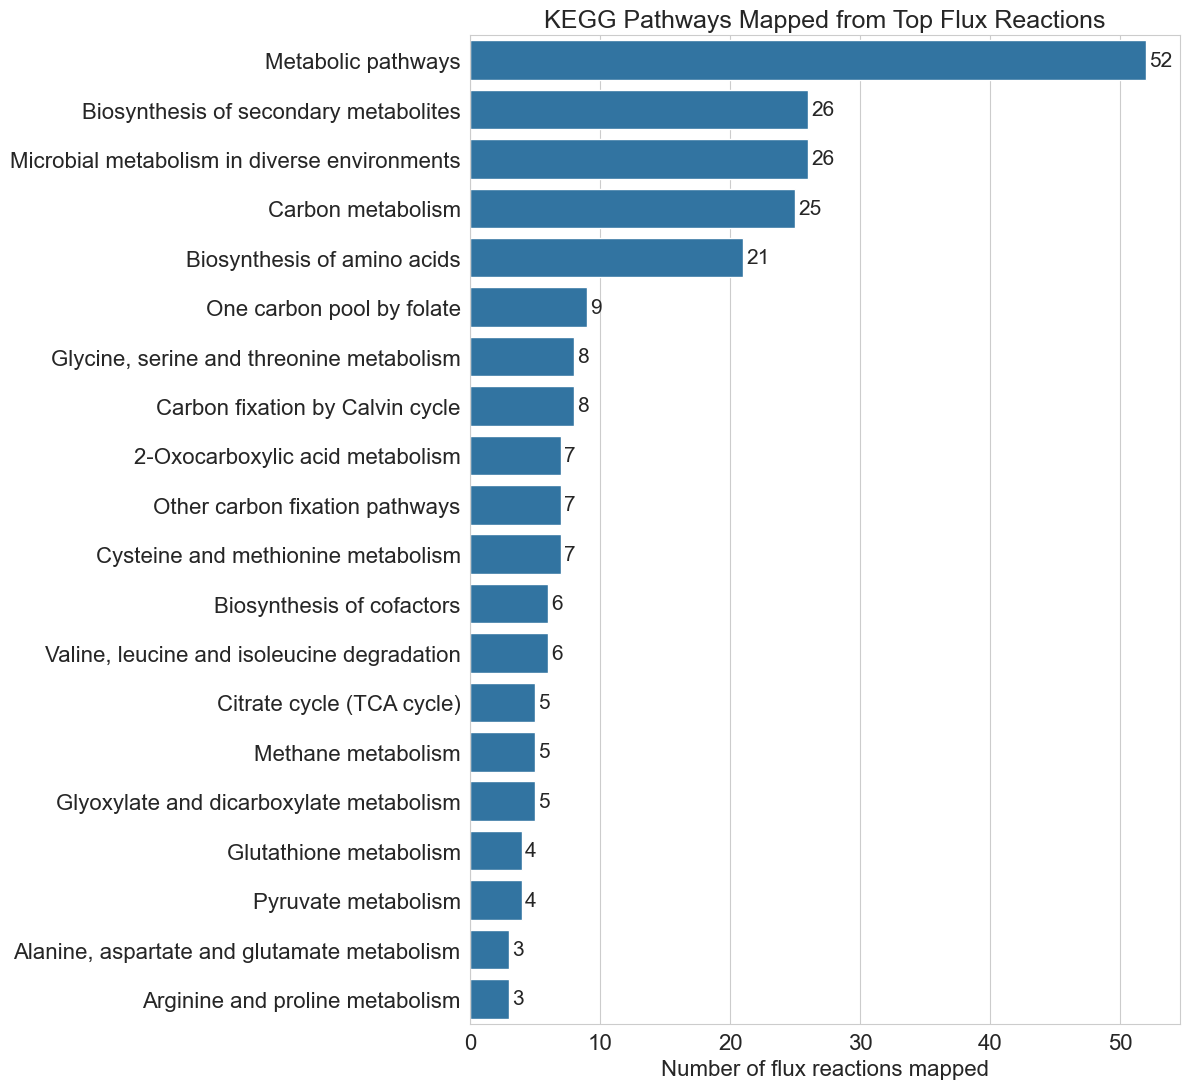

In [123]:
rxn_path_df = kegg_rxn_map.copy()

# keep only rows with pathway names
rxn_path_df = rxn_path_df.dropna(subset=["kegg_pathway_name"])
rxn_path_df = rxn_path_df[rxn_path_df["kegg_pathway_name"].astype(str).str.strip() != ""]

# count unique reactions per KEGG pathway
path_counts = (
    rxn_path_df.groupby("kegg_pathway_name")["input_reaction"]
    .nunique()
    .reset_index(name="reaction_count")
    .sort_values("reaction_count", ascending=False)
)

topn = 20
plot_df = path_counts.head(topn).copy()

plt.figure(figsize=(12, max(6, 0.55 * len(plot_df))))
ax = sns.barplot(data=plot_df, x="reaction_count", y="kegg_pathway_name")

ax.set_title("KEGG Pathways Mapped from Top Flux Reactions", fontsize=18)
ax.set_xlabel("Number of flux reactions mapped", fontsize=16)
ax.set_ylabel("", fontsize=16)

ax.tick_params(axis="x", labelsize=16)
ax.tick_params(axis="y", labelsize=16)

# add count labels
for i, row in plot_df.reset_index(drop=True).iterrows():
    ax.text(row["reaction_count"] + 0.2, i, str(row["reaction_count"]),
            va="center", fontsize=15)

plt.tight_layout()


plt.savefig(f"Results/pathway_analysis/KEGG_flux_reaction_pathway_barplot.pdf", bbox_inches="tight")


plt.show()
plt.close()



# Find the Overexpressed and underexpressed reaction's pathway

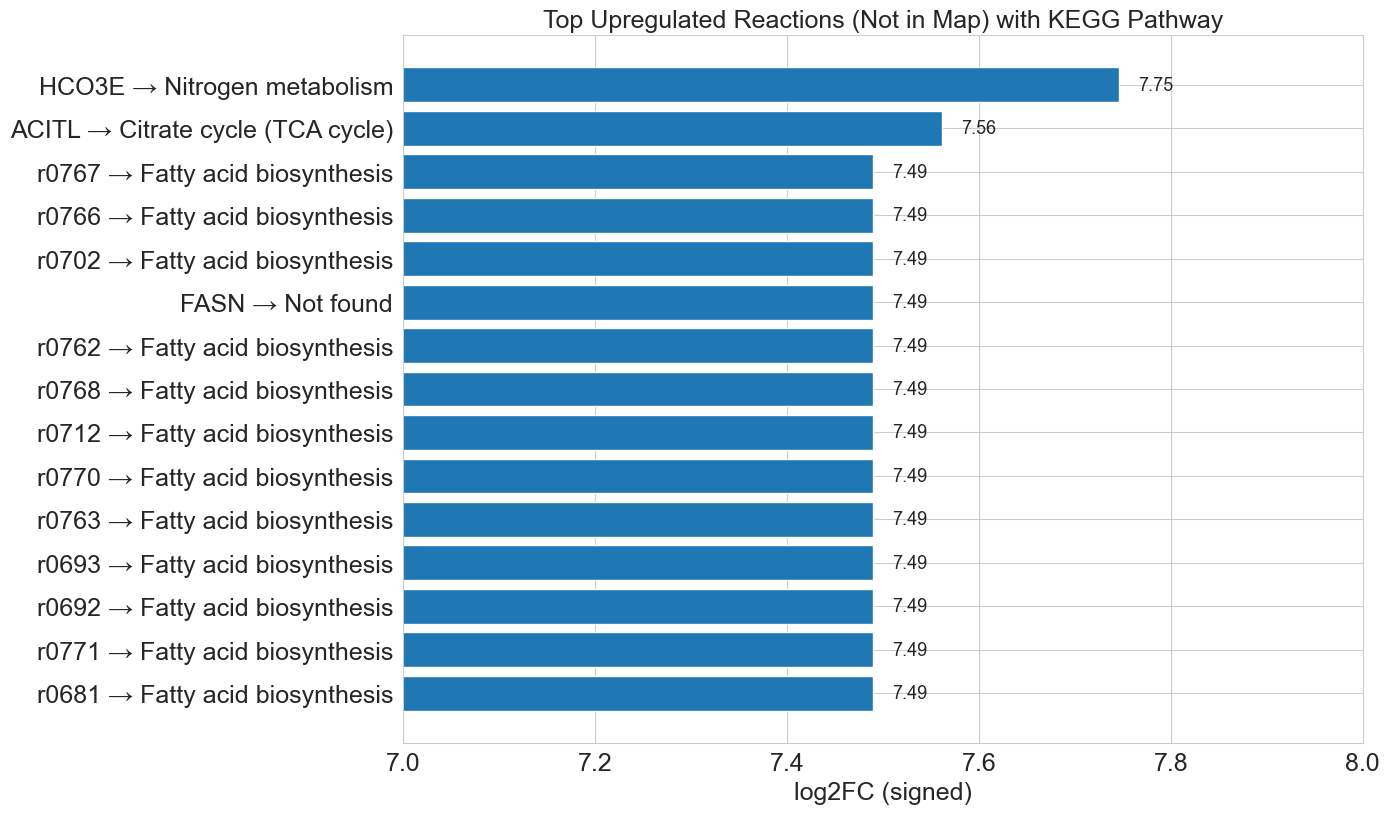

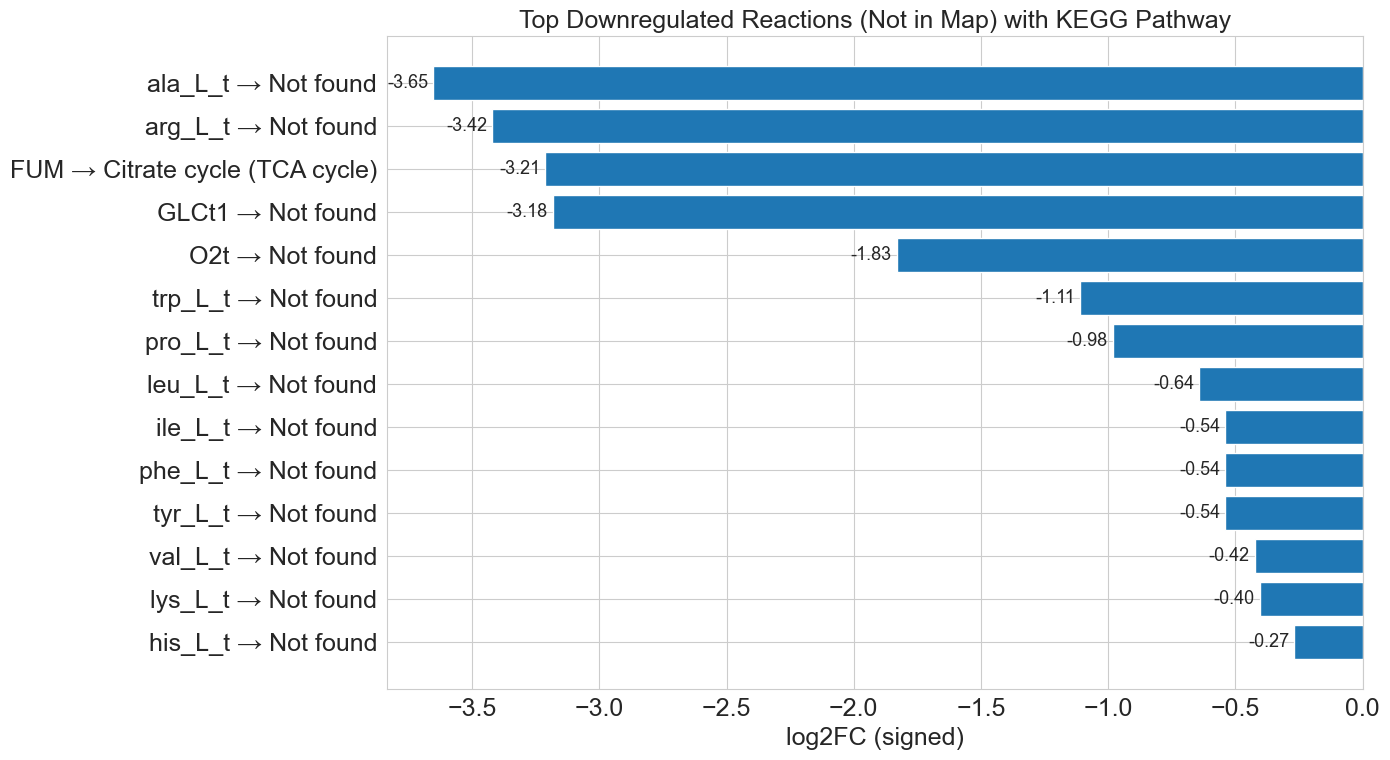

In [129]:
hg_rxn = pd.read_csv(REACTIONS_TSV_URL, sep="\t")

id_cols = ["rxns","rxnBiGGID","rxnRecon3DID","rxnKEGGID","rxnMetaNetXID","rxnRheaID","rxnHMR2ID"]
id_cols = [c for c in id_cols if c in hg_rxn.columns]

ext_to_hg = {}
hg_to_kegg = {}

for _, r in hg_rxn.iterrows():
    hg_id = safe_str(r.get("rxns", ""))
    if not hg_id:
        continue
    for col in id_cols:
        for v in split_ids(r.get(col, "")):
            ext_to_hg.setdefault(v, hg_id)
    kegg_ids = split_ids(r.get("rxnKEGGID", ""))
    if kegg_ids:
        hg_to_kegg[hg_id] = kegg_ids

def kegg_link_pathways_for_reaction(rid):
    url = f"https://rest.kegg.jp/link/pathway/rn:{rid}"
    r = requests.get(url, timeout=30)
    if r.status_code != 200:
        return []
    out = []
    for ln in r.text.splitlines():
        parts = ln.strip().split("\t")
        if len(parts) == 2:
            out.append(parts[1].replace("path:", ""))
    return sorted(set(out))

def kegg_pathway_name(pid):
    url = f"https://rest.kegg.jp/get/{pid}"
    r = requests.get(url, timeout=30)
    if r.status_code != 200:
        return ""
    for ln in r.text.splitlines():
        if ln.startswith("NAME"):
            return ln.replace("NAME", "").strip()
    return ""

name_cache = {}
rxn_path_cache = {}

def reaction_to_one_pathway(rxn_id):
    if rxn_id in rxn_path_cache:
        return rxn_path_cache[rxn_id]

    hg_id = ext_to_hg.get(rxn_id, rxn_id)
    kegg_ids = hg_to_kegg.get(hg_id, [])

    best_name = "Not found"

    for kid in kegg_ids:
        pids = kegg_link_pathways_for_reaction(kid)
        time.sleep(0.2)
        if not pids:
            continue
        pid = pids[0]
        if pid not in name_cache:
            name_cache[pid] = kegg_pathway_name(pid)
            time.sleep(0.2)
        best_name = name_cache.get(pid, "") or "Not found"
        break

    rxn_path_cache[rxn_id] = best_name
    return best_name

THR = 0.25
TOP_N = 15

map_rxns = [
    "HEX1","PGI","PFK","FBA","TPI","GAPD","PGK","PGM","ENO","PYK","LDH_L",
    "PYRt2m","PDHm","CSm","ACONTm","ICDHxm","AKGDm","SUCOAS1m","SUCD1m",
    "FUMm","MDHm","ASPTA","ASPGlu_m","AKGMALtm","CO2tm","EX_co2[e]"
]

rxn_stats = rxn_stats.copy()
rxn_stats["direction"] = np.where(
    rxn_stats["log2FC_signed"] > THR, "Up",
    np.where(rxn_stats["log2FC_signed"] < -THR, "Down", "no_change")
)

sig_df = rxn_stats[
    (~rxn_stats["reaction"].isin(map_rxns)) &
    (rxn_stats["sig"] == "***") &
    (rxn_stats["direction"].isin(["Up", "Down"]))
].copy()

sig_df["kegg_pathway_name"] = sig_df["reaction"].apply(reaction_to_one_pathway)
sig_df["reaction_label"] = sig_df["reaction"].astype(str) + " → " + sig_df["kegg_pathway_name"].astype(str)
up_top = sig_df[sig_df["direction"] == "Up"].sort_values("log2FC_signed", ascending=False).head(TOP_N)
down_top = sig_df[sig_df["direction"] == "Down"].sort_values("log2FC_signed", ascending=True).head(TOP_N)
def plot_reaction_bars(plot_df, title, out_pdf, flag):
    if plot_df.empty:
        print(f"No reactions found for: {title}")
        return

    y = plot_df["reaction_label"].astype(str).values
    x = plot_df["log2FC_signed"].astype(float).values

    plt.figure(figsize=(14, max(6, 0.55 * len(plot_df))))
    plt.barh(y, x)

    plt.title(title, fontsize=18)
    plt.xlabel("log2FC (signed)", fontsize=18)
    plt.ylabel("")
    plt.xticks(fontsize=18)
    plt.yticks(fontsize=18)
    plt.gca().invert_yaxis()

    if flag == True:
        plt.xlim(7, 8)
    for i, v in enumerate(x):
        plt.text(
            v + (0.02 if v >= 0 else -0.02),
            i,
            f"{v:.2f}",
            va="center",
            ha="left" if v >= 0 else "right",
            fontsize=13
        )

    plt.tight_layout()
    plt.savefig(out_pdf, bbox_inches="tight")
    plt.show()
    plt.close()

plot_reaction_bars(
    up_top,
    "Top Upregulated Reactions (Not in Map) with KEGG Pathway",
    f"Results/pathway_analysis/up_not_in_map_with_kegg_pathway_thr_{THR}.pdf",
    flag = True
)

plot_reaction_bars(
    down_top,
    "Top Downregulated Reactions (Not in Map) with KEGG Pathway",
    f"Results/pathway_analysis/down_not_in_map_with_kegg_pathway_thr_{THR}.pdf",
    flag = False
)
